# BKT: experiments added in the revision

This notebook contains the code of the experiments added to the revised submission "Backward Kolmogorov Transport: Sampling Invariant Laws of Reversible Diffusions from Trajectory Data", the results of the runs reported in the paper (embedded below as data), and the tables and figures computed from them.

| experiment | script | in the paper |
|---|---|---|
| E1. Barrier-height scan, $V=a(x^2-1)^2$, trajectory data from chains in both wells or in one well | `e1_v2.py`, `e1_stationarity.py` | Section 5 (Limitations and diagnostics), Appendix E.6, Table 13, Figure 12 |
| E2. Two well-separated Gaussian mixtures (mode discovery, weight equilibration); exact eigenfunction with a wrong eigenvalue | `e2_mixture.py`, `e2_rest.py` | Appendix E.6, Tables 14 and 15 |
| E3. Sensitivity to the Gaussian dictionary, two-dimensional double well | `e3_v2.py` | Appendix E.6, Table 16 |
| E5. LAWGD against BKT with the same estimated eigenpairs on the double wells and the four-well product | `e5_v2.py` | Table 1, Appendix E.4, Table 11, Figure 11 |
| E6. Coupled three-dimensional double well with jointly estimated eigenpairs ($J=513$ and $J=1729$), and an exchange of the slow eigenvalues of the two dictionaries | `e6_v2.py`, `e6b_dictionary.py`, `e6c_swap.py` | Table 1, Section 5, Appendix E.5, Table 12 |
| E7. The barrier-height scan with data from a biased simulation, reweighted, and the residual term of Corollary 4.2 | `e7_biased.py` | Section 5, Appendices E.6 and E.7, Table 17 |

**How to use it.** Running the notebook from the top writes the library and the scripts to the current folder (`%%writefile` cells), writes the embedded results to `results/`, and recomputes all tables and figures from them in a few seconds. The experiments themselves are not rerun by the notebook; each script is run from a terminal in the same folder (`python e1_v2.py`, and so on), resumes from its result file, and needs between about one minute and about seventy minutes (E1) on one core. The times given with each script are those of a rerun of all scripts from scratch on a two-core machine running two scripts at a time. The scripts resume from the files in `results/`, so a file must be deleted to rerun its experiment from scratch; `e6_target.npy` is the target sample of the three-dimensional example, shared by E6 and E6b. E3 and E5 use `bktlib.py`, the library of the original experiments (cells 1 to 4 of `BKT_experiments.ipynb` in the repository), which is also written below.

All runs use one thread of OpenBLAS (`OPENBLAS_NUM_THREADS=1`).

In [1]:
import os, sys, json, gzip, base64, platform
import numpy as np, scipy, matplotlib
import matplotlib.pyplot as plt
%matplotlib inline
os.makedirs('results', exist_ok=True); os.makedirs('figures', exist_ok=True)
print('python', platform.python_version(), '| numpy', np.__version__, '| scipy', scipy.__version__, '| matplotlib', matplotlib.__version__)

python 3.13.18 | numpy 2.5.3 | scipy 1.18.1 | matplotlib 3.11.2


## 1. Library

`rebuttal_lib.py`: simulation of the chains, tensor Gaussian dictionaries, reversible gEDMD with the lag consistency check, finite-difference spectra in one and three dimensions, BKT with RK4 (as in the paper) and with a per-particle adaptive Dormand-Prince 5(4) integrator, LAWGD with the same eigenpairs, and the error metrics.

In [2]:
%%writefile rebuttal_lib.py
"""Self-contained numerical library for the rebuttal experiments of the BKT paper.

Reproduces the protocol of BKT_experiments.ipynb (Euler step 2e-3, lag 0.1, 500 chains,
burn-in 20, reversible gEDMD with Gaussian dictionaries, RK4 transport with the density
threshold and the velocity bound), with a few additions needed for the rebuttal:
per-chain transition counts, the generator/lag eigenvalue disagreement, per-particle
safeguard masks, a LAWGD transport with the same eigenpairs, and 3D finite differences.
"""
import numpy as np
from scipy.linalg import eigh
import scipy.sparse as sp
import scipy.sparse.linalg as spla

DTSIM, TAU = 2e-3, 0.1


# ----------------------------------------------------------------------------- simulation
def simulate_chains(grad, box, n, rng, chains=500, burn=20.0, init=None, dt_sim=DTSIM, tau=TAU, reflect=True):
    """Pairs (X_0, X_tau) along `chains` reversible diffusions dX = -grad(X) dt + sqrt(2) dW.
    Returns X, Y of shape (steps, chains, d) so that transitions can be counted per chain."""
    box = np.asarray(box, float); d = box.shape[0]
    x = init(chains, rng) if init is not None else rng.uniform(box[:, 0] * 0.5, box[:, 1] * 0.5, size=(chains, d))
    sub = max(1, int(round(tau / dt_sim))); dt_sim = tau / sub
    def step(x):
        y = x - grad(x) * dt_sim + np.sqrt(2 * dt_sim) * rng.standard_normal(x.shape)
        return np.clip(y, box[:, 0], box[:, 1]) if reflect else y
    for _ in range(int(round(burn / dt_sim))): x = step(x)
    st = int(np.ceil(n / chains)); X = np.empty((st, chains, d)); Y = np.empty_like(X)
    for s in range(st):
        X[s] = x
        for _ in range(sub): x = step(x)
        Y[s] = x
    return X, Y


def count_transitions(X, saddle=0.0, coord=0):
    """Number of sign changes of X[:, :, coord] - saddle along each chain, summed over chains."""
    s = np.sign(X[:, :, coord] - saddle)
    return int((s[1:] * s[:-1] < 0).sum())


# ----------------------------------------------------------------------------- dictionaries
class TensorRBF:
    """Constant plus a tensor grid of Gaussians, n per coordinate, on the box."""
    def __init__(self, box, n, wfrac=0.075, width=None):
        box = np.asarray(box, float); self.d = box.shape[0]
        self.cen = [np.linspace(box[i, 0], box[i, 1], n) for i in range(self.d)]
        self.wid = [width if width is not None else wfrac * (box[i, 1] - box[i, 0]) for i in range(self.d)]
    def size(self): return 1 + len(self.cen[0]) ** self.d
    def eval(self, X):
        X = np.atleast_2d(X); M, d = X.shape
        g, dg = [], []
        for i in range(d):
            z = (X[:, i][:, None] - self.cen[i][None, :]) / self.wid[i]; e = np.exp(-0.5 * z ** 2)
            g.append(e); dg.append(-z / self.wid[i] * e)
        if d == 1:
            return np.hstack([np.ones((M, 1)), g[0]]), np.hstack([np.zeros((M, 1)), dg[0]])[:, :, None]
        # tensor product over coordinates
        P = g[0]; dPs = [dg[0]] + [g[0]] * (d - 1)
        for i in range(1, d):
            P = np.einsum('ma,mb->mab', P, g[i]).reshape(M, -1)
            dPs = [np.einsum('ma,mb->mab', dPs[j], dg[i] if j == i else g[i]).reshape(M, -1) for j in range(d)]
        return np.hstack([np.ones((M, 1)), P]), np.concatenate([np.zeros((M, 1, d)), np.stack(dPs, 2)], 1)


# ----------------------------------------------------------------------------- reversible gEDMD
class GEDMD:
    """Reversible gEDMD (Klus et al. 2020) from the Gram matrix G and the Dirichlet matrix D of the
    dictionary, with whitening at tolerance `tol`. Also keeps the lag matrix A = E[psi(X_0) psi(X_tau)^T]
    to compute the Koopman (lag) eigenvalues of the same eigenvectors, which gives the consistency
    diagnostic disagreement(k) = |lam_k - lam_k^lag| / lam_k."""
    def __init__(self, dic, X, Y, tol=1e-8, chunk=5000, tau=TAU):
        J = dic.size(); G = np.zeros((J, J)); D = np.zeros((J, J)); A = np.zeros((J, J))
        for a in range(0, len(X), chunk):
            P, dP = dic.eval(X[a:a + chunk]); Q, _ = dic.eval(Y[a:a + chunk])
            G += P.T @ P; A += P.T @ Q; D += np.einsum('mjd,mkd->jk', dP, dP, optimize=True)
        n = len(X); G /= n; D /= n; A /= n
        sg, U = np.linalg.eigh(G); keep = sg > tol * sg.max(); W = U[:, keep] / np.sqrt(sg[keep])
        lw, Z = np.linalg.eigh(W.T @ D @ W); V = W @ Z; o = np.argsort(lw); lam, V = lw[o], V[:, o]; lam[0] = 0.0
        nrm = np.sqrt(np.einsum('jk,jk->k', V, G @ V)); V = V / nrm; V[:, 0] *= np.sign(G[0] @ V[:, 0])
        ray = np.einsum('jk,jk->k', V, A @ V) / np.einsum('jk,jk->k', V, G @ V)
        self.dic, self.V, self.lam, self.kept, self.G = dic, V, lam, int(keep.sum()), G
        self.lam_lag = -np.log(np.clip(ray, 1e-300, None)) / tau
    def disagreement(self, k): return float(abs(self.lam[k] - self.lam_lag[k]) / max(self.lam[k], 1e-300))
    def field(self, coef):
        """rho and grad rho for the dictionary coefficients `coef` (J,)."""
        def f(Y):
            P, dP = self.dic.eval(Y)
            return P @ coef, np.einsum('mjd,j->md', dP, coef)
        return f
    def modes(self, Y, idx):
        P, dP = self.dic.eval(Y); Vr = self.V[:, idx]
        return P @ Vr, np.einsum('mjd,jk->mkd', dP, Vr)



class WeightedGEDMD(GEDMD):
    """Reversible gEDMD from samples of a biased law with importance weights w, for instance data of a simulation
    with a bias potential V_b and w = exp(-(V - V_b)). The Gram and Dirichlet matrices are averages over pi and are
    estimated as weighted averages. The subspace kept by the whitening is chosen with the Gram matrix of the samples
    themselves, which measures the linear dependence of the dictionary where the data lie; whitening with the
    weighted Gram matrix would discard the functions supported on the barrier, where pi is small. The generalized
    eigenproblem D v = lam G v is then solved in that subspace. Without unbiased pairs there is no lag matrix, and
    lam_lag is not defined."""
    def __init__(self, dic, X, w, tol=1e-8, chunk=5000):
        from scipy.linalg import eigh as geigh
        J = dic.size(); Gs = np.zeros((J, J)); G = np.zeros((J, J)); D = np.zeros((J, J)); w = np.asarray(w, float) / np.sum(w)
        for a in range(0, len(X), chunk):
            P, dP = dic.eval(X[a:a + chunk]); ww = w[a:a + chunk]
            Gs += P.T @ P; G += (P * ww[:, None]).T @ P; D += np.einsum('m,mjd,mkd->jk', ww, dP, dP, optimize=True)
        Gs /= len(X)
        sg, U = np.linalg.eigh(Gs); keep = sg > tol * sg.max(); W = U[:, keep] / np.sqrt(sg[keep])
        A, B = W.T @ D @ W, W.T @ G @ W
        lw, Z = geigh(0.5 * (A + A.T), 0.5 * (B + B.T)); V = W @ Z; o = np.argsort(lw); lam, V = lw[o], V[:, o]; lam[0] = 0.0
        nrm = np.sqrt(np.einsum('jk,jk->k', V, G @ V)); V = V / nrm; V[:, 0] *= np.sign(G[0] @ V[:, 0])
        self.dic, self.V, self.lam, self.kept, self.G = dic, V, lam, int(keep.sum()), G
        self.lam_lag = np.full_like(lam, np.nan)

# ----------------------------------------------------------------------------- 1D finite differences
def fd_1d(Vfun, N=1401, L=3.5):
    """Grid eigenpairs of L = -d^2/dx^2 + V' d/dx on [-L, L] (Neumann), orthonormal in L^2(pi)."""
    xg = np.linspace(-L, L, N); h = xg[1] - xg[0]
    pi = np.exp(-(Vfun(xg) - Vfun(xg).min())); pi /= np.sum(pi) * h
    pih = np.sqrt(pi[:-1] * pi[1:])
    A = np.zeros((N, N)); i = np.arange(N - 1)
    A[i, i] += pih / h; A[i + 1, i + 1] += pih / h; A[i, i + 1] -= pih / h; A[i + 1, i] -= pih / h
    lam, Phi = eigh(A, np.diag(pi * h)); lam[0] = 0.0; Phi[:, 0] = 1.0
    Phi = Phi / np.sqrt(np.sum(Phi ** 2 * (pi * h)[:, None], axis=0)); dPhi = np.gradient(Phi, h, axis=0)
    cdf = np.cumsum(pi) * h; cdf /= cdf[-1]
    return dict(xg=xg, h=h, pi=pi, lam=lam, Phi=Phi, dPhi=dPhi, cdf=cdf)


def fd_field_1d(G, weights):
    """rho, grad rho on the grid eigenbasis with mode weights (len r+1)."""
    xg, Phi, dPhi = G['xg'], G['Phi'], G['dPhi']; r1 = len(weights)
    rho_g, drho_g = Phi[:, :r1] @ weights, dPhi[:, :r1] @ weights
    def f(Y):
        y = Y[:, 0]; return np.interp(y, xg, rho_g), np.interp(y, xg, drho_g)[:, None]
    return f


def fd_modes_1d(G, Y, idx):
    y = np.atleast_2d(Y)[:, 0]
    P = np.stack([np.interp(y, G['xg'], G['Phi'][:, k]) for k in idx], 1)
    dP = np.stack([np.interp(y, G['xg'], G['dPhi'][:, k]) for k in idx], 1)[:, :, None]
    return P, dP


# ----------------------------------------------------------------------------- 3D finite differences
def fd_nd(Vfun, box, n, kmax=40):
    """Grid eigenpairs of the generator in d dimensions (tensor grid with n points per axis)."""
    box = np.asarray(box, float); d = box.shape[0]
    axes = [np.linspace(box[i, 0], box[i, 1], n) for i in range(d)]; hs = [a[1] - a[0] for a in axes]
    mesh = np.meshgrid(*axes, indexing='ij'); Vg = Vfun(np.stack([m.ravel() for m in mesh], 1)).reshape(mesh[0].shape)
    w = np.exp(-(Vg - Vg.min())); vol = np.prod(hs); w /= w.sum() * vol; N = w.size; idx = np.arange(N).reshape(w.shape)
    rows, cols, vals = [], [], []
    for ax in range(d):
        sl_a = [slice(None)] * d; sl_b = [slice(None)] * d; sl_a[ax] = slice(1, None); sl_b[ax] = slice(None, -1)
        we = 0.5 * (w[tuple(sl_a)] + w[tuple(sl_b)]) * vol / hs[ax] ** 2
        i, j = idx[tuple(sl_a)].ravel(), idx[tuple(sl_b)].ravel(); c = we.ravel()
        rows += [i, j, i, j]; cols += [i, j, j, i]; vals += [c, c, -c, -c]
    K = sp.csc_matrix((np.concatenate(vals), (np.concatenate(rows), np.concatenate(cols))), shape=(N, N))
    Mm = sp.diags((w * vol).ravel())
    lam, U = spla.eigsh(K, k=kmax + 1, M=Mm, sigma=-1e-3, which='LM'); o = np.argsort(lam); lam, U = lam[o], U[:, o]; lam[0] = 0.0
    U = U / np.sqrt(np.einsum('ij,i,ij->j', U, (w * vol).ravel(), U)); U[:, 0] *= np.sign(U[:, 0].mean())
    return dict(axes=axes, w=w, lam=lam, U=U.reshape(w.shape + (kmax + 1,)), vol=vol)


def fd_modes_nd(G, Y, idx):
    """Trilinear interpolation of grid eigenfunctions and their gradients at the points Y."""
    from scipy.interpolate import RegularGridInterpolator
    axes = G['axes']; U = G['U']; d = len(axes)
    P = np.stack([RegularGridInterpolator(axes, U[..., k], bounds_error=False, fill_value=None)(Y) for k in idx], 1)
    dP = np.zeros((len(Y), len(idx), d))
    for k_i, k in enumerate(idx):
        grads = np.gradient(U[..., k], *[a[1] - a[0] for a in axes])
        for ax in range(d):
            dP[:, k_i, ax] = RegularGridInterpolator(axes, grads[ax], bounds_error=False, fill_value=None)(Y)
    return P, dP


# ----------------------------------------------------------------------------- transport
def transport_bkt(X0, lam, modes, r, T, dt, box=None, eps0=1e-3, vmax=20.0, coefficients=None, field=None, steps_log=None):
    """BKT with RK4. `modes(Y, idx)` returns (P (M, r+1), dP (M, r+1, d)); if `field(coef)` is given
    (dictionary-coefficient form, faster) it is used for the velocity instead.
    Returns the particles and diagnostics: fraction of particles whose path met the threshold or the bound."""
    X = X0.copy(); M, d = X.shape; idx = np.arange(r + 1)
    if coefficients is None:
        P0, _ = modes(X0, idx); c0 = P0.mean(0); c0[0] = 1.0
    else:
        c0 = np.asarray(coefficients, float)
    lam_s = np.asarray(lam[idx], float)
    floor = np.zeros(M, bool); cap = np.zeros(M, bool); neg = np.zeros(M, bool)
    def vel(Y, t):
        w = np.exp(-lam_s * t) * c0
        if field is not None:
            rho, grad = field(w)
        else:
            P, dP = modes(Y, idx); rho = P @ w; grad = np.einsum('k,mkd->md', w, dP)
        neg[:] |= rho <= 0; floor[:] |= rho < eps0
        v = -grad / np.maximum(rho, eps0)[:, None]; nv = np.linalg.norm(v, axis=1, keepdims=True)
        cap[:] |= nv[:, 0] > vmax
        return v * np.minimum(1.0, vmax / np.maximum(nv, 1e-12))
    proj = (lambda Y: np.clip(Y, box[:, 0], box[:, 1])) if box is not None else (lambda Y: Y)
    nsteps = int(round(T / dt))
    for i in range(nsteps):
        t = i * dt; k1 = vel(X, t); k2 = vel(proj(X + .5 * dt * k1), t + .5 * dt); k3 = vel(proj(X + .5 * dt * k2), t + .5 * dt); k4 = vel(proj(X + dt * k3), t + dt)
        X = proj(X + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4))
    diag = dict(floor_fraction=float(floor.mean()), cap_fraction=float(cap.mean()), negative_fraction=float(neg.mean()),
                safeguard_fraction=float((floor | cap).mean()), steps=nsteps, coefficients=c0)
    return X, diag


def transport_lawgd(X0, lam, modes, r, T, dt, box=None, vmax=20.0, checkpoints=None, metric=None):
    """Laplacian-adjusted Wasserstein gradient descent with the same eigenpairs:
    dx_i/dt = -sum_k lam_k^{-1} m_k(t) grad phi_k(x_i), m_k(t) = M^{-1} sum_j phi_k(x_j(t)), RK4, same bound and box."""
    X = X0.copy(); idx = np.arange(1, r + 1); inv = 1.0 / np.asarray(lam[idx], float)
    cap = np.zeros(len(X0), bool)
    def vel(Y):
        P, dP = modes(Y, idx); m = P.mean(0)
        v = -np.einsum('k,mkd->md', inv * m, dP); nv = np.linalg.norm(v, axis=1, keepdims=True)
        cap[:] |= nv[:, 0] > vmax
        return v * np.minimum(1.0, vmax / np.maximum(nv, 1e-12))
    proj = (lambda Y: np.clip(Y, box[:, 0], box[:, 1])) if box is not None else (lambda Y: Y)
    out = []; nsteps = int(round(T / dt)); cps = sorted(checkpoints or [])
    for i in range(nsteps):
        k1 = vel(X); k2 = vel(proj(X + .5 * dt * k1)); k3 = vel(proj(X + .5 * dt * k2)); k4 = vel(proj(X + dt * k3))
        X = proj(X + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4))
        t = (i + 1) * dt
        while cps and t >= cps[0] - 1e-9:
            out.append((cps.pop(0), metric(X) if metric else None))
    while cps: out.append((cps.pop(0), metric(X) if metric else None))   # checkpoints at the horizon missed by rounding
    return X, dict(cap_fraction=float(cap.mean()), steps=nsteps, checkpoints=out)


def transport_bkt_checkpoints(X0, lam, modes, r, T, dt, checkpoints, metric, box=None, eps0=1e-3, vmax=20.0):
    """BKT with the error recorded at checkpoints (same integrator as transport_bkt)."""
    X = X0.copy(); idx = np.arange(r + 1); P0, _ = modes(X0, idx); c0 = P0.mean(0); c0[0] = 1.0; lam_s = lam[idx]
    cap = np.zeros(len(X0), bool); floor = np.zeros(len(X0), bool)
    def vel(Y, t):
        w = np.exp(-lam_s * t) * c0; P, dP = modes(Y, idx); rho = P @ w; grad = np.einsum('k,mkd->md', w, dP)
        floor[:] |= rho < eps0; v = -grad / np.maximum(rho, eps0)[:, None]; nv = np.linalg.norm(v, axis=1, keepdims=True)
        cap[:] |= nv[:, 0] > vmax; return v * np.minimum(1.0, vmax / np.maximum(nv, 1e-12))
    proj = (lambda Y: np.clip(Y, box[:, 0], box[:, 1])) if box is not None else (lambda Y: Y)
    out = []; nsteps = int(round(T / dt)); cps = sorted(checkpoints)
    for i in range(nsteps):
        t = i * dt; k1 = vel(X, t); k2 = vel(proj(X + .5 * dt * k1), t + .5 * dt); k3 = vel(proj(X + .5 * dt * k2), t + .5 * dt); k4 = vel(proj(X + dt * k3), t + dt)
        X = proj(X + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4)); t = (i + 1) * dt
        while cps and t >= cps[0] - 1e-9:
            out.append((cps.pop(0), metric(X)))
    while cps: out.append((cps.pop(0), metric(X)))
    return X, dict(cap_fraction=float(cap.mean()), floor_fraction=float(floor.mean()), safeguard_fraction=float((cap | floor).mean()), steps=nsteps, checkpoints=out)


# ----------------------------------------------------------------------------- sources and metrics
def bump_sampler(center, width, M, rng):
    u = np.linspace(center - width, center + width, 4001)
    dens = np.cos(np.pi * (u - center) / (2 * width)) ** 2; F = np.cumsum(dens); F /= F[-1]
    return np.interp(rng.random(M), F, u)


def w2_1d(X, cdf, xg):
    x = np.sort(np.ravel(X)); q = np.interp((np.arange(len(x)) + 0.5) / len(x), cdf, xg)
    return float(np.sqrt(np.mean((x - q) ** 2)))


def quantile_sample_1d(cdf, xg, M, rng):
    return np.interp(rng.random(M), cdf, xg)[:, None]


def sliced_w2(X, Y, seed=0, n=64):
    g = np.random.default_rng(seed); th = g.standard_normal((n, X.shape[1])); th /= np.linalg.norm(th, axis=1, keepdims=True)
    m = min(len(X), len(Y)); return float(np.sqrt(np.mean([np.mean((np.sort(X @ u)[:m] - np.sort(Y @ u)[:m]) ** 2) for u in th])))


def basin_masses_sign(X):
    """Masses of the 2^d orthants (wells of a product of double wells)."""
    d = X.shape[1]; code = ((X > 0).astype(int) * (2 ** np.arange(d))).sum(1)
    return np.bincount(code, minlength=2 ** d) / len(X)


def mean_sd(v):
    v = np.asarray(v, float); return float(v.mean()), (float(v.std(ddof=1)) if len(v) > 1 else 0.0)


def pm(v, digits=4):
    m, s = mean_sd(v); return f"{m:.{digits}f} ± {s:.{digits}f}"


# ----------------------------------------------------------------------------- adaptive transport in normalized time
def transport_adaptive(X0, lam, modes, r, lam1, s_max=8.0, box=None, eps0=1e-3, vmax=20.0, coefficients=None,
                       rtol=1e-6, atol=1e-8, max_step=0.05, method='DOP853', checkpoints=None, metric=None):
    """BKT integrated in the normalized time s = lam1 t with an adaptive Runge-Kutta method (DOP853),
    as in the alanine experiment. Returns particles, diagnostics (nfev, safeguard fractions) and checkpoint values."""
    from scipy.integrate import solve_ivp
    X0 = np.asarray(X0, float); M, d = X0.shape; idx = np.arange(r + 1)
    if coefficients is None:
        P0, _ = modes(X0, idx); c0 = P0.mean(0); c0[0] = 1.0
    else:
        c0 = np.asarray(coefficients, float)
    lam_s = np.asarray(lam[idx], float); floor = np.zeros(M, bool); cap = np.zeros(M, bool); nfev = [0]
    def rhs(s, flat):
        Y = flat.reshape(M, d); t = s / lam1; w = np.exp(-lam_s * t) * c0
        P, dP = modes(Y, idx); rho = P @ w; grad = np.einsum('k,mkd->md', w, dP)
        floor[:] |= rho < eps0; v = -grad / np.maximum(rho, eps0)[:, None]; nv = np.linalg.norm(v, axis=1, keepdims=True)
        cap[:] |= nv[:, 0] > vmax; v = v * np.minimum(1.0, vmax / np.maximum(nv, 1e-12))
        if box is not None:   # no outward velocity at the walls of the box
            v = np.where((Y <= box[:, 0]) & (v < 0), 0.0, v); v = np.where((Y >= box[:, 1]) & (v > 0), 0.0, v)
        nfev[0] += 1
        return (v / lam1).ravel()
    t_eval = sorted(checkpoints) if checkpoints else None
    sol = solve_ivp(rhs, (0.0, s_max), X0.ravel(), method=method, rtol=rtol, atol=atol, max_step=max_step, t_eval=t_eval)
    if not sol.success: raise RuntimeError(sol.message)
    X = sol.y[:, -1].reshape(M, d)
    if box is not None: X = np.clip(X, box[:, 0], box[:, 1])
    cps = [(float(s), metric(sol.y[:, i].reshape(M, d))) for i, s in enumerate(sol.t)] if (metric and t_eval) else []
    return X, dict(nfev=nfev[0], nsteps=len(sol.t) if t_eval is None else None, floor_fraction=float(floor.mean()),
                   cap_fraction=float(cap.mean()), safeguard_fraction=float((floor | cap).mean()), coefficients=c0, checkpoints=cps)


# ----------------------------------------------------------------------------- per-particle adaptive integration (physical time)
_DP = dict(
    c=np.array([0, 1/5, 3/10, 4/5, 8/9, 1.0, 1.0]),
    a=[[], [1/5], [3/40, 9/40], [44/45, -56/15, 32/9], [19372/6561, -25360/2187, 64448/6561, -212/729],
       [9017/3168, -355/33, 46732/5247, 49/176, -5103/18656], [35/384, 0, 500/1113, 125/192, -2187/6784, 11/84]],
    b5=np.array([35/384, 0, 500/1113, 125/192, -2187/6784, 11/84, 0]),
    b4=np.array([5179/57600, 0, 7571/16695, 393/640, -92097/339200, 187/2100, 1/40]))


def transport_per_particle(X0, lam, modes, r, T, box=None, eps0=1e-3, vmax=20.0, coefficients=None,
                           rtol=1e-6, atol=1e-9, h0=None, hmax=None, max_iter=200000):
    """BKT in physical time with the Dormand-Prince 5(4) pair and an independent adaptive step for each
    particle, which the absence of interaction allows. A particle crossing a barrier takes small steps
    while the others keep large ones. Returns particles, and diagnostics with the number of accepted and
    rejected steps per particle."""
    X = np.asarray(X0, float).copy(); M, d = X.shape; idx = np.arange(r + 1)
    if coefficients is None:
        P0, _ = modes(X0, idx); c0 = P0.mean(0); c0[0] = 1.0
    else:
        c0 = np.asarray(coefficients, float)
    lam_s = np.asarray(lam[idx], float); floor = np.zeros(M, bool); cap = np.zeros(M, bool)
    def vel(Y, t):   # Y (m, d), t (m,)
        W = np.exp(-np.outer(t, lam_s)) * c0; P, dP = modes(Y, idx); rho = (P * W).sum(1); grad = np.einsum('mk,mkd->md', W, dP)
        fl = rho < eps0; v = -grad / np.maximum(rho, eps0)[:, None]; nv = np.linalg.norm(v, axis=1, keepdims=True); cp = nv[:, 0] > vmax
        v = v * np.minimum(1.0, vmax / np.maximum(nv, 1e-12))
        if box is not None:
            v = np.where((Y <= box[:, 0]) & (v < 0), 0.0, v); v = np.where((Y >= box[:, 1]) & (v > 0), 0.0, v)
        return v, fl, cp
    t = np.zeros(M); h = np.full(M, (T * 1e-4) if h0 is None else h0); hmax = T if hmax is None else hmax
    accepted = np.zeros(M, int); rejected = np.zeros(M, int); active = np.ones(M, bool)
    c, a, b5, b4 = _DP['c'], _DP['a'], _DP['b5'], _DP['b4']; it = 0
    while active.any() and it < max_iter:
        it += 1; ia = np.flatnonzero(active); x = X[ia]; ta = t[ia]; ha = np.minimum(h[ia], T - ta)
        k = []
        for s in range(7):
            xs = x + ha[:, None] * sum(a[s][j] * k[j] for j in range(s)) if s else x
            v, fl, cp = vel(xs, ta + c[s] * ha); k.append(v)
            if s == 0: floor[ia] |= fl; cap[ia] |= cp
        x5 = x + ha[:, None] * sum(b5[j] * k[j] for j in range(7)); x4 = x + ha[:, None] * sum(b4[j] * k[j] for j in range(7))
        sc = atol + rtol * np.maximum(np.abs(x), np.abs(x5)); err = np.max(np.abs(x5 - x4) / sc, axis=1)
        ok = err <= 1.0; fac = 0.9 * np.power(np.maximum(err, 1e-16), -0.2); fac = np.clip(fac, 0.2, 5.0)
        X[ia[ok]] = x5[ok]; t[ia[ok]] = ta[ok] + ha[ok]; accepted[ia[ok]] += 1; rejected[ia[~ok]] += 1
        h[ia] = np.minimum(ha * fac, hmax)
        active[ia[ok]] = t[ia[ok]] < T * (1 - 1e-12)
    if box is not None: X = np.clip(X, box[:, 0], box[:, 1])
    return X, dict(accepted=accepted, rejected=rejected, mean_steps=float(accepted.mean()), max_steps=int(accepted.max()),
                   iterations=it, finished=bool(not active.any()), unfinished_fraction=float(active.mean()), floor_fraction=float(floor.mean()), cap_fraction=float(cap.mean()),
                   safeguard_fraction=float((floor | cap).mean()), coefficients=c0)


# ----------------------------------------------------------------------------- fast transports for dictionary-based eigenpairs
# `est` is any object with est.V (J x K eigenvector coefficients), est.lam (K,) and est.dic.eval(Y) -> (P (m,J), dP (m,J,d)),
# e.g. GEDMD above or RREstimate of the paper's notebook. Mode sums are contracted with the eigenvectors before the
# dictionary is evaluated, as in the paper's implementation, so each velocity costs one dictionary evaluation.
def _project(box):
    return (lambda Y: np.clip(Y, box[:, 0], box[:, 1])) if box is not None else (lambda Y: Y)


def bkt_fast(est, X0, r, T, dt, box=None, eps0=1e-3, vmax=20.0, coef_source=None, checkpoints=(), metric=None):
    """BKT with the RK4 scheme of the paper. Checkpoints are physical times. Returns particles and diagnostics
    (per-particle safeguard masks summarized as fractions, checkpoint values, the coefficients)."""
    idx = np.arange(r + 1); Vr = est.V[:, idx]; lam = np.asarray(est.lam[idx], float)
    src = X0 if coef_source is None else coef_source
    c0 = (est.dic.eval(src)[0] @ Vr).mean(0); c0[0] = 1.0
    X = np.array(X0, float); M = len(X); floor = np.zeros(M, bool); cap = np.zeros(M, bool); proj = _project(box)
    def vel(Y, t):
        agg = Vr @ (np.exp(-lam * t) * c0); P, dP = est.dic.eval(Y); rho = P @ agg; grad = np.einsum('mjd,j->md', dP, agg, optimize=True)
        floor[:] |= rho < eps0; v = -grad / np.maximum(rho, eps0)[:, None]; nv = np.linalg.norm(v, axis=1, keepdims=True); cap[:] |= nv[:, 0] > vmax
        return v * np.minimum(1.0, vmax / np.maximum(nv, 1e-12))
    nsteps = int(round(T / dt)); want = {int(round(c / dt)): c for c in checkpoints}; out = []
    for i in range(nsteps):
        t = i * dt; k1 = vel(X, t); k2 = vel(proj(X + .5 * dt * k1), t + .5 * dt); k3 = vel(proj(X + .5 * dt * k2), t + .5 * dt); k4 = vel(proj(X + dt * k3), t + dt)
        X = proj(X + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4))
        if metric is not None and (i + 1) in want: out.append((want[i + 1], metric(X)))
    return X, dict(steps=nsteps, floor_fraction=float(floor.mean()), cap_fraction=float(cap.mean()),
                   safeguard_fraction=float((floor | cap).mean()), coefficients=c0, checkpoints=out)


def lawgd_fast(est, X0, r, S, ds, box=None, vmax=np.inf, checkpoints=(), metric=None):
    """LAWGD (Chewi et al. 2020) with the same eigenpairs: dx/ds = -sum_k lam_k^{-1} m_k(s) grad phi_k(x),
    m_k(s) = mean of phi_k over the current particles. With this normalization every mode of the linearized
    dynamics decays like e^{-s}, the slowest mode of the KL flow decays like e^{-lam_1 t}, so s is comparable with
    lam_1 t. RK4 with step ds, the same projection; vmax applies in the time s."""
    idx = np.arange(1, r + 1); Vr = est.V[:, idx]; inv = 1.0 / np.asarray(est.lam[idx], float)
    X = np.array(X0, float); M = len(X); cap = np.zeros(M, bool); proj = _project(box)
    def vel(Y):
        P, dP = est.dic.eval(Y); m = P.mean(0) @ Vr; agg = Vr @ (inv * m)
        v = -np.einsum('mjd,j->md', dP, agg, optimize=True); nv = np.linalg.norm(v, axis=1, keepdims=True); cap[:] |= nv[:, 0] > vmax
        return v * np.minimum(1.0, vmax / np.maximum(nv, 1e-12))
    nsteps = int(round(S / ds)); want = {int(round(c / ds)): c for c in checkpoints}; out = []
    for i in range(nsteps):
        k1 = vel(X); k2 = vel(proj(X + .5 * ds * k1)); k3 = vel(proj(X + .5 * ds * k2)); k4 = vel(proj(X + ds * k3))
        X = proj(X + ds / 6 * (k1 + 2 * k2 + 2 * k3 + k4))
        if metric is not None and (i + 1) in want: out.append((want[i + 1], metric(X)))
    return X, dict(steps=nsteps, cap_fraction=float(cap.mean()), checkpoints=out)


def modes_from_est(est):
    """(P, dP) of the eigenfunctions with indices idx, shapes (m, len(idx)) and (m, len(idx), d)."""
    def modes(Y, idx):
        P, dP = est.dic.eval(np.atleast_2d(Y)); Vr = est.V[:, idx]
        return P @ Vr, np.einsum('mjd,jk->mkd', dP, Vr, optimize=True)
    return modes


def transport_pp(X0, lam, modes, r, T, box=None, eps0=1e-3, vmax=20.0, coefficients=None, rtol=1e-6, atol=1e-9,
                 max_iter=3000, h0=None):
    """Per-particle adaptive Dormand-Prince 5(4) in physical time (see transport_per_particle), with an iteration cap.
    Particles not finished after max_iter iterations are left where they are and counted in 'unfinished_fraction';
    in the runs reported this happens only where the safeguarded field has a sink at a negative minimum of the
    truncated ratio, where the particles no longer move."""
    X, d = transport_per_particle(X0, lam, modes, r, T, box=box, eps0=eps0, vmax=vmax, coefficients=coefficients,
                                  rtol=rtol, atol=atol, h0=h0, max_iter=max_iter)
    return X, d


# ----------------------------------------------------------------------------- tensor-structured evaluation
class TensorField:
    """Values and gradients of sum_j a_j psi_j for a TensorRBF dictionary (constant plus tensor Gaussians),
    computed from the one-dimensional factors instead of the M x J dictionary matrix. The arithmetic is that of
    dic.eval(Y) contracted with a, in a different order (O(M n^d) per contraction, no M x J x d array)."""
    def __init__(self, dic):
        self.dic, self.d, self.n = dic, dic.d, len(dic.cen[0])
    def factors(self, Y):
        g, dg = [], []
        for i in range(self.d):
            z = (Y[:, i][:, None] - self.dic.cen[i][None, :]) / self.dic.wid[i]; e = np.exp(-0.5 * z ** 2)
            g.append(e); dg.append(-z / self.dic.wid[i] * e)
        return g, dg
    def _contract(self, A, fs):
        T = np.tensordot(fs[-1], A, axes=([1], [self.d - 1]))          # (M, n, ..., n), d-1 trailing axes
        for i in range(self.d - 2, -1, -1):
            T = np.einsum('m...a,ma->m...', T, fs[i])
        return T
    def field(self, Y, a):
        """rho = sum_j a_j psi_j(Y) and its gradient (M, d)."""
        Y = np.atleast_2d(Y); A = np.asarray(a[1:]).reshape((self.n,) * self.d); g, dg = self.factors(Y)
        rho = a[0] + self._contract(A, g)
        grad = np.stack([self._contract(A, [dg[i] if i == k else g[i] for i in range(self.d)]) for k in range(self.d)], 1)
        return rho, grad
    def mean_psi(self, Y):
        """Average over the points Y of the dictionary vector (J,)."""
        Y = np.atleast_2d(Y); M = len(Y); g, _ = self.factors(Y); P = g[0]
        for i in range(1, self.d):
            P = (P[:, :, None] * g[i][:, None, :]).reshape(M, -1)
        return np.concatenate([[1.0], P.mean(0)])


def bkt_tensor(est, X0, r, T, dt, box=None, eps0=1e-3, vmax=20.0, coef_source=None, checkpoints=(), metric=None):
    """bkt_fast with the velocity evaluated through TensorField (same scheme, same safeguards)."""
    tf = TensorField(est.dic); idx = np.arange(r + 1); Vr = est.V[:, idx]; lam = np.asarray(est.lam[idx], float)
    src = X0 if coef_source is None else coef_source
    c0 = tf.mean_psi(src) @ Vr; c0[0] = 1.0
    X = np.array(X0, float); M = len(X); floor = np.zeros(M, bool); cap = np.zeros(M, bool); proj = _project(box)
    def vel(Y, t):
        rho, grad = tf.field(Y, Vr @ (np.exp(-lam * t) * c0))
        floor[:] |= rho < eps0; v = -grad / np.maximum(rho, eps0)[:, None]; nv = np.linalg.norm(v, axis=1, keepdims=True); cap[:] |= nv[:, 0] > vmax
        return v * np.minimum(1.0, vmax / np.maximum(nv, 1e-12))
    nsteps = int(round(T / dt)); want = {int(round(c / dt)): c for c in checkpoints}; out = []
    for i in range(nsteps):
        t = i * dt; k1 = vel(X, t); k2 = vel(proj(X + .5 * dt * k1), t + .5 * dt); k3 = vel(proj(X + .5 * dt * k2), t + .5 * dt); k4 = vel(proj(X + dt * k3), t + dt)
        X = proj(X + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4))
        if metric is not None and (i + 1) in want: out.append((want[i + 1], metric(X)))
    return X, dict(steps=nsteps, floor_fraction=float(floor.mean()), cap_fraction=float(cap.mean()),
                   safeguard_fraction=float((floor | cap).mean()), coefficients=c0, checkpoints=out)


def lawgd_tensor(est, X0, r, S, ds, box=None, vmax=np.inf, checkpoints=(), metric=None):
    """lawgd_fast with the velocity evaluated through TensorField."""
    tf = TensorField(est.dic); idx = np.arange(1, r + 1); Vr = est.V[:, idx]; inv = 1.0 / np.asarray(est.lam[idx], float)
    X = np.array(X0, float); M = len(X); cap = np.zeros(M, bool); proj = _project(box)
    def vel(Y):
        m = tf.mean_psi(Y) @ Vr; a = Vr @ (inv * m); _, grad = tf.field(Y, a)
        v = -grad; nv = np.linalg.norm(v, axis=1, keepdims=True); cap[:] |= nv[:, 0] > vmax
        return v * np.minimum(1.0, vmax / np.maximum(nv, 1e-12))
    nsteps = int(round(S / ds)); want = {int(round(c / ds)): c for c in checkpoints}; out = []
    for i in range(nsteps):
        k1 = vel(X); k2 = vel(proj(X + .5 * ds * k1)); k3 = vel(proj(X + .5 * ds * k2)); k4 = vel(proj(X + ds * k3))
        X = proj(X + ds / 6 * (k1 + 2 * k2 + 2 * k3 + k4))
        if metric is not None and (i + 1) in want: out.append((want[i + 1], metric(X)))
    return X, dict(steps=nsteps, cap_fraction=float(cap.mean()), checkpoints=out)

Overwriting rebuttal_lib.py


`make_figures.py`: the figures of the new experiments (Figures 11 and 12 of the paper and the figure of the three-dimensional example), in the style of the figures of the submission.

In [3]:
%%writefile make_figures.py
"""Figures of the experiments added in the revision, in the style of the figures of the submission.

Reads the result files in results/ and writes figures/fig_lawgd_double_wells.pdf (Figure 11),
figures/fig_barrier_scan.pdf (Figure 12) and figures/fig_coupled3d.pdf (three-dimensional example).
Independent panels carry their quantity as a title. A shared quantity of a row is written once on the left.
Legends are placed below the panels."""
import json, os
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

HERE = os.path.dirname(os.path.abspath(__file__))
RES = os.path.join(HERE, 'results'); FIG = os.path.join(HERE, 'figures'); os.makedirs(FIG, exist_ok=True)

STYLE = {'font.size': 8, 'axes.titlesize': 8.5, 'axes.labelsize': 8, 'legend.fontsize': 7.5, 'xtick.labelsize': 7, 'ytick.labelsize': 7,
         'figure.titlesize': 10, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'axes.grid.axis': 'y',
         'grid.color': '0.9', 'grid.linewidth': 0.6, 'legend.frameon': False, 'lines.linewidth': 1.1, 'lines.markersize': 3,
         'errorbar.capsize': 1.8, 'pdf.fonttype': 42}
C = dict(bkt='#0072b2', lawgd='#d55e00', fd='#009e73', est='#8e44ad', lag='#e69f00', ref='0.35', band='0.9', data='0.5')
mean = lambda v: float(np.mean(v))
sd = lambda v: float(np.std(v, ddof=1)) if len(v) > 1 else 0.0
load = lambda name: json.load(open(os.path.join(RES, name)))


def ref_band(ax, m, s, **kw):
    ax.axhspan(m - s, m + s, color=C['band'], lw=0, zorder=0); ax.axhline(m, color=C['ref'], ls=':', lw=0.9, zorder=1)


def legend_below(fig, handles, ncol, y=0.0):
    fig.legend(handles=handles, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, y), handlelength=1.8, columnspacing=1.2, handletextpad=0.5)


def fig_lawgd():
    rows = load('e5v2_results.json')
    names = {'A2_beta0.0': r'$\beta=0$', 'A2_beta0.25': r'$\beta=0.25$', 'A2_beta0.5': r'$\beta=0.5$', 'A2_beta1.0': r'$\beta=1$', 'B_quartic4': 'Four wells'}
    fig, axs = plt.subplots(1, 5, figsize=(7.0, 2.25), sharey=True)
    for ax, (key, label) in zip(axs, names.items()):
        R = [r for r in rows if r['system'] == key]
        S = [c for c, _ in R[0]['lawgd']['checkpoints']]
        for meth, col, mk in (('bkt', C['bkt'], 'o'), ('lawgd', C['lawgd'], 's')):
            v = np.array([[x for _, x in r[meth]['checkpoints']] for r in R])
            ax.errorbar(S, v.mean(0), v.std(0, ddof=1), color=col, marker=mk)
        ref_band(ax, R[0]['reference']['metrics']['sw']['mean'], R[0]['reference']['metrics']['sw']['std'])
        ax.set_xscale('log'); ax.set_yscale('log'); ax.set_title(label); ax.set_xlabel(r'Flow time $s=\hat\lambda_1 t$')
    axs[0].set_ylabel(r'Sliced $W_2$')
    fig.suptitle('BKT and LAWGD with the same estimated eigenpairs')
    legend_below(fig, [Line2D([], [], color=C['bkt'], marker='o', label='BKT'), Line2D([], [], color=C['lawgd'], marker='s', label='LAWGD'),
                       Line2D([], [], color=C['ref'], ls=':', label='Target reference')], 3)
    fig.tight_layout(rect=(0, 0.1, 1, 1)); fig.savefig(os.path.join(FIG, 'fig_lawgd_double_wells.pdf')); plt.close(fig)


def fig_barrier():
    rows = [r for r in load('e1v2_results.json') if r['a'] <= 10]
    stat = {(r['a'], r['init'], r['seed']): r for r in load('e1_stationarity.json')}
    E = {}
    for init in ('both', 'right'):
        for a in sorted({r['a'] for r in rows}):
            R = [r for r in rows if r['a'] == a and r['init'] == init]
            g = lambda f: np.array([f(r) for r in R], float)
            E[(init, a)] = dict(dataL=g(lambda r: r['data_left_fraction']), ref=R[0]['reference_mean'], fd_w2=g(lambda r: r['fd']['w2']), fd_left=g(lambda r: r['fd']['left']),
                                rel=g(lambda r: abs(r['adapted']['rel'])), dis1=g(lambda r: r['adapted']['dis1']), w2=g(lambda r: r['adapted']['w2']), left=g(lambda r: r['adapted']['left']))
    ks = sorted(a for (i, a) in E if i == 'both')
    fig, ax = plt.subplots(1, 3, figsize=(7.0, 2.6))
    for init, ls in (('both', '-'), ('right', '--')):
        dd = [E[(init, a)] for a in ks]
        ax[0].plot(ks, [np.median(x['rel']) for x in dd], color=C['est'], ls=ls, marker='o')
        ax[0].plot(ks, [np.median(x['dis1']) for x in dd], color=C['lag'], ls=ls, marker='s')
        ax[1].errorbar(ks, [mean(x['w2']) for x in dd], [sd(x['w2']) for x in dd], color=C['est'], ls=ls, marker='o')
        ax[2].errorbar(ks, [mean(x['left']) for x in dd], [sd(x['left']) for x in dd], color=C['est'], ls=ls, marker='o')
        ax[2].plot(ks, [mean(x['dataL']) for x in dd], color=C['data'], ls=ls, lw=0.9, marker='x')
        if init == 'both':
            ax[1].errorbar(ks, [mean(x['fd_w2']) for x in dd], [sd(x['fd_w2']) for x in dd], color=C['fd'], marker='^')
            ax[1].plot(ks, [x['ref'] for x in dd], color=C['ref'], ls=':', lw=0.9)
            ax[2].errorbar(ks, [mean(x['fd_left']) for x in dd], [sd(x['fd_left']) for x in dd], color=C['fd'], marker='^')
    ax[0].set_yscale('log'); ax[0].set_title(r'$|\hat\lambda_1/\lambda_1-1|$ and lag disagreement (median)')
    ax[1].set_yscale('log'); ax[1].set_title(r'$W_2$ to the target')
    ax[2].set_title('Mass of the left well'); ax[2].axhline(0.5, color=C['ref'], ls=':', lw=0.9); ax[2].set_ylim(-0.02, 0.62)
    for a_ in ax: a_.set_xlabel(r'Barrier height $a$ ($k_BT$)'); a_.set_xticks(ks)
    fig.suptitle(r'Barrier-height scan, $V=a(x^2-1)^2$, trajectory data')
    legend_below(fig, [Line2D([], [], color=C['est'], marker='o', label='Estimated eigenpairs'),
                       Line2D([], [], color=C['lag'], marker='s', label='Lag disagreement'),
                       Line2D([], [], color=C['fd'], marker='^', label='FD eigenpairs'),
                       Line2D([], [], color=C['ref'], ls=':', label='Target reference'),
                       Line2D([], [], color=C['data'], marker='x', lw=0.9, label='Left-well fraction of the data'),
                       Line2D([], [], color='k', label='Chains start in both wells'),
                       Line2D([], [], color='k', ls='--', label='Chains start in the right well')], 4, y=0.0)
    fig.tight_layout(rect=(0, 0.19, 1, 1)); fig.savefig(os.path.join(FIG, 'fig_barrier_scan.pdf')); plt.close(fig)


def fig_coupled3d():
    a, b = load('e6v2_results.json'), load('e6b_results.json'); A6, B6 = a['rows'], b['rows']; rs = [8, 16, 32, 64]
    fig, ax = plt.subplots(1, 2, figsize=(6.2, 2.5))
    series = (('fd', A6, 'fd', 'BKT, FD-41', C['fd'], '^'), ('k513', A6, 'koopman', 'BKT, $J=513$', C['bkt'], 'o'), ('k1729', B6, 'koopman', 'BKT, $J=1729$', '#56b4e9', 'o'),
              ('l513', A6, 'lawgd', 'LAWGD, $J=513$', C['lawgd'], 's'), ('l1729', B6, 'lawgd', 'LAWGD, $J=1729$', '#f0a070', 's'))
    for key, R, src, label, col, mk in series:
        for j, q in enumerate(('w2', 'tv')):
            v = np.array([[x[src][str(r)][q] for r in rs] for x in R])
            ax[j].errorbar(rs, v.mean(0), v.std(0, ddof=1), color=col, marker=mk)
    ref_band(ax[0], a['reference']['mean'], a['reference']['sd'])
    ax[0].set_title(r'Sliced $W_2$ to the target sample'); ax[1].set_title('TV of the masses of the eight wells')
    for a_ in ax: a_.set_xscale('log', base=2); a_.set_xticks(rs); a_.set_xticklabels([str(r) for r in rs]); a_.set_xlabel(r'Retained modes $r$')
    fig.suptitle(r'Coupled three-dimensional double well, $\beta=0.5$')
    legend_below(fig, [Line2D([], [], color=col, marker=mk, label=label) for _, _, _, label, col, mk in series] + [Line2D([], [], color=C['ref'], ls=':', label='Target reference')], 3)
    fig.tight_layout(rect=(0, 0.2, 1, 1)); fig.savefig(os.path.join(FIG, 'fig_coupled3d.pdf')); plt.close(fig)


def main(png=False):
    """Write the three PDFs (and PNG copies if png=True, for display in the notebook) and return their paths."""
    with plt.rc_context(STYLE):
        fig_lawgd(); fig_barrier(); fig_coupled3d()
    out = [os.path.join(FIG, f) for f in ('fig_lawgd_double_wells.pdf', 'fig_barrier_scan.pdf', 'fig_coupled3d.pdf')]
    if png:
        import subprocess
        for f in out:
            subprocess.run(['pdftoppm', '-r', '150', '-png', '-singlefile', f, f[:-4]], check=False)
        out = [f[:-4] + '.png' for f in out]
    return out


if __name__ == '__main__':
    print('\n'.join(main()))

Overwriting make_figures.py


`bktlib.py`: the library of the original experiments (potentials, trajectory data, reversible gEDMD, sources, target samples and sliced Wasserstein distance of Table 1), used by E3 and E5 so that they follow the protocol of Table 1 exactly.

In [4]:
%%writefile bktlib.py
# Fixed manuscript settings and verified data archives
import sys, os, time, json, math
# Keep numerical outputs and cache together, outside the source files.
from pathlib import Path
_here = Path.cwd().resolve()
PROJECT_DIR = _here.parent if _here.name == 'outputs' and (_here.parent / 'BKT_experiments.ipynb').exists() else _here
import sys
sys.path.insert(0, str(PROJECT_DIR / "supplementary"))
try:
    from experiment_store import activate_notebook_store
    activate_notebook_store()
except Exception as _e:
    print('store not activated:', _e)
OUTPUT_DIR = PROJECT_DIR / 'outputs'
OUTPUT_DIR.mkdir(exist_ok=True)
os.chdir(OUTPUT_DIR)
os.environ['OPENBLAS_NUM_THREADS'] = '1'
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['MKL_NUM_THREADS'] = '1'
import numpy as np
import matplotlib; import matplotlib.pyplot as plt
QUICK = False   # Full experiment budgets
if QUICK: NPAIR, M2D, M10D, SEEDS_MAIN, SEEDS_SEC, SEEDS_10D, DT = 3000, 120, 60, 1, 1, 1, 0.1   # small sizes for a quick check of the code (a few minutes)
else:     NPAIR, M2D, M10D, SEEDS_MAIN, SEEDS_SEC, SEEDS_10D, DT = 200000, 2000, 1000, 10, 10, 10, 0.05
DT_A2 = 0.05  # transport step for all 2D A double-well experiments
TUNE = {'wfrac': 0.075, 'rbf_n1d': 30, 'poly_p1d': 20, 'poly_p2d': 16}   # fixed dictionary settings
# Existing 10D defaults remain n=8 (657 functions), p=3 (286 functions).
R10 = 16  # retained nonconstant modes in Part I 10D experiments
# Retained appendix sensitivity experiments.
TRAINING_BUDGETS = [10000, 100000, 200000]
FIXED_TRAINING_PAIRS = {'A2_beta0.0':200000, 'A2_beta0.25':200000, 'A2_beta0.5':200000, 'A2_beta1.0':200000, 'B_quartic4':200000, 'B_poly9':200000, 'A10_beta0.0':100000}
APPENDIX_SYSTEMS = {}
RETAINED_SYSTEMS = {f'A2_beta{b}' for b in [0.,.25,.5,1.]} | {'B_quartic4','B_poly9','A10_beta0.0'}
REFERENCE_REPEATS = 10
CACHE_ENABLED = True

# Embedded persistent cache: no local Python modules are required.
"""Content-addressed numerical cache. Arrays only; never loads pickled code.

Callers must include numerical parameters and implementation/dependency hashes.
Cache hits return fresh arrays, so subsequent in-place edits cannot poison disk.
"""
from pathlib import Path
from collections import Counter
from functools import wraps
import hashlib
import json
import os
import sys
import tempfile
import types
import zipfile
import numpy as np
import scipy

CACHE_DIR = Path('cache/numerics')
STATS = Counter()


def _identity(value):
    if isinstance(value, np.ndarray):
        a = np.ascontiguousarray(value)
        return {'array': hashlib.sha256(a.tobytes()).hexdigest(),
                'shape': a.shape, 'dtype': a.dtype.str}
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, dict):
        return {str(k): _identity(v) for k, v in sorted(value.items(), key=lambda p: str(p[0]))}
    if isinstance(value, (list, tuple)):
        return [_identity(v) for v in value]
    if isinstance(value, types.CodeType):
        return {'bytecode': value.co_code.hex(), 'consts': _identity(value.co_consts),
                'names': value.co_names, 'vars': value.co_varnames,
                'freevars': value.co_freevars, 'cellvars': value.co_cellvars}
    if isinstance(value, bytes):
        return {'bytes': value.hex()}
    if value is None or isinstance(value, (str, int, float, bool)):
        return value
    raise TypeError(f'Unsupported cache key: {type(value).__name__}')


def digest(value):
    return hashlib.sha256(json.dumps(_identity(value), sort_keys=True,
                                     separators=(',', ':')).encode()).hexdigest()


def code_hash(*functions):
    """Ignores notebook execution counts/filenames; includes defaults and code."""
    parts = []
    for fn in functions:
        fn = getattr(fn, '__wrapped__', fn)
        parts.append((fn.__code__, fn.__defaults__, fn.__kwdefaults__))
    return digest(parts)


def class_hash(cls):
    functions = []
    for _, value in sorted(vars(cls).items()):
        if isinstance(value, (staticmethod, classmethod)):
            value = value.__func__
        if isinstance(value, types.FunctionType):
            functions.append(value)
    return code_hash(*functions)


def _pack(value, arrays):
    if isinstance(value, np.ndarray):
        if value.dtype.hasobject:
            raise TypeError('Object arrays are not supported')
        key = f'a{len(arrays)}'; arrays[key] = value
        return {'array': key}
    if isinstance(value, np.generic):
        value = value.item()
    if isinstance(value, dict):
        return {'dict': [[k, _pack(v, arrays)] for k, v in value.items()]}
    if isinstance(value, (tuple, list)):
        return {'tuple' if isinstance(value, tuple) else 'list': [_pack(v, arrays) for v in value]}
    if value is None or isinstance(value, (str, int, float, bool)):
        return {'scalar': value}
    raise TypeError(f'Unsupported cache value: {type(value).__name__}')


def _unpack(tree, arrays):
    if 'array' in tree: return arrays[tree['array']].copy()
    if 'dict' in tree: return {k: _unpack(v, arrays) for k, v in tree['dict']}
    if 'tuple' in tree: return tuple(_unpack(v, arrays) for v in tree['tuple'])
    if 'list' in tree: return [_unpack(v, arrays) for v in tree['list']]
    return tree['scalar']


def cached_arrays(name, key, compute):
    if not CACHE_ENABLED:
        STATS[f'{name}:disabled'] += 1
        return compute()
    config = {'format': 1, 'python': sys.version_info[:2], 'numpy': np.__version__,
              'scipy': scipy.__version__, 'parameters': key}
    folder = CACHE_DIR / name
    path = folder / (digest(config) + '.npz')
    if path.exists():
        try:
            with np.load(path, allow_pickle=False) as data:
                result = _unpack(json.loads(str(data['metadata'])), data)
            STATS[f'{name}:hit'] += 1
            return result
        except (ValueError, OSError, KeyError, EOFError, zipfile.BadZipFile):
            STATS[f'{name}:invalid'] += 1
    result = compute()
    arrays = {}; tree = _pack(result, arrays)
    arrays['metadata'] = np.array(json.dumps(tree))
    arrays['config'] = np.array(json.dumps(_identity(config), sort_keys=True))
    folder.mkdir(parents=True, exist_ok=True)
    # Unique temporary file and atomic replacement also allow concurrent readers.
    with tempfile.NamedTemporaryFile(dir=folder, suffix='.npz', delete=False) as f:
        temporary = Path(f.name)
        np.savez_compressed(f, **arrays)
    os.replace(temporary, path)
    STATS[f'{name}:miss'] += 1
    return result


def cache_grid_1d(fn):
    @wraps(fn)
    def wrapped(Vfun, N=1401, L=3.5):
        grid = np.linspace(-L, L, N)
        values = np.asarray(Vfun(grid))
        return cached_arrays('grid_1d', dict(N=N, L=L, potential=values, code=code_hash(fn)),
                             lambda: fn(Vfun, N=N, L=L))
    return wrapped


os.makedirs('figures', exist_ok=True); os.makedirs('tables', exist_ok=True)

def section(cell, title, notes=''):
    """Print a short experiment heading without creating a duplicate log"""
    print('\n' + '=' * 100 + f'\n[code cell {cell}] {title}\n' + (notes + '\n' if notes else '') + '-' * 100)
section(1, 'Settings', f'QUICK={QUICK}; pairs per data set {NPAIR}; particles M={M2D} (2D), {M10D} (10D); seeds {SEEDS_MAIN}/{SEEDS_SEC}/{SEEDS_10D} (main/secondary/10D cells); transport step {DT} (2D A: {DT_A2}); dictionaries {TUNE}')

# Enforce the declared thread setting even in an already initialized kernel.
os.environ['BLIS_NUM_THREADS'] = '1'
from threadpoolctl import threadpool_limits
_NOTEBOOK_THREAD_LIMITS = threadpool_limits(limits=1)


# code cell 2: one-dimensional helpers (grid eigenpairs of the double well, bump source, transport in one dimension)
"""One-dimensional helpers: grid eigenpairs of the double well, bump source, support for separable multidimensional products."""
import numpy as np
from scipy.linalg import eigh
from scipy.stats import norm

# ---------------- Hermite (OU) basis ----------------
def hermite_basis(x, r):
    x = np.asarray(x, float)
    P = np.zeros((r + 1, x.size)); dP = np.zeros((r + 1, x.size))
    P[0] = 1.0
    if r >= 1: P[1] = x
    for k in range(1, r):
        P[k + 1] = (x * P[k] - np.sqrt(k) * P[k - 1]) / np.sqrt(k + 1)
    for k in range(1, r + 1):
        dP[k] = np.sqrt(k) * P[k - 1]
    return P, dP


# ---------------- 1D generator on a grid (Dirichlet form) ----------------
@cache_grid_1d
def setup_1d(Vfun, N=1401, L=3.5):
    xg = np.linspace(-L, L, N); h = xg[1] - xg[0]
    pi = np.exp(-Vfun(xg)); pi /= np.sum(pi) * h
    pih = np.sqrt(pi[:-1] * pi[1:])
    A = np.zeros((N, N)); i = np.arange(N - 1)
    A[i, i] += pih / h; A[i + 1, i + 1] += pih / h; A[i, i + 1] -= pih / h; A[i + 1, i] -= pih / h
    lam, Phi = eigh(A, np.diag(pi * h))
    lam[0] = 0.0; Phi[:, 0] = 1.0
    Phi = Phi / np.sqrt(np.sum(Phi**2 * (pi * h)[:, None], axis=0))
    dPhi = np.gradient(Phi, h, axis=0)
    cdf = np.cumsum(pi) * h; cdf /= cdf[-1]
    return dict(xg=xg, h=h, pi=pi, lam=lam, Phi=Phi, dPhi=dPhi, cdf=cdf)

def grid_basis_factory(G):
    xg, Phi, dPhi = G['xg'], G['Phi'], G['dPhi']; h = xg[1] - xg[0]
    def basis(x, r):
        idx = np.clip(np.searchsorted(xg, x), 1, len(xg) - 1)
        w = np.clip((x - xg[idx - 1]) / h, 0, 1)[:, None]
        P = (Phi[idx - 1, :r + 1] * (1 - w) + Phi[idx, :r + 1] * w).T
        dP = (dPhi[idx - 1, :r + 1] * (1 - w) + dPhi[idx, :r + 1] * w).T
        return P, dP
    def weighted(x, weights):
        # Interpolation is linear in the grid values; sum modes on the grid first.
        size = len(weights)
        return (np.interp(x, xg, Phi[:, :size] @ weights),
                np.interp(x, xg, dPhi[:, :size] @ weights))
    basis.weighted = weighted
    return basis

def bump_sampler(center, width, M, rng):
    u = np.linspace(center - width, center + width, 4001)
    dens = np.cos(np.pi * (u - center) / (2 * width))**2; F = np.cumsum(dens); F /= F[-1]
    return np.interp(rng.random(M), F, u)

# ---------------- metrics ----------------
def w2_gauss(X):
    M = len(X); q = norm.ppf((np.arange(M) + 0.5) / M)
    return np.sqrt(np.mean((np.sort(X) - q)**2))

def w2_grid(X, G):
    M = len(X); q = np.interp((np.arange(M) + 0.5) / M, G['cdf'], G['xg'])
    return np.sqrt(np.mean((np.sort(X) - q)**2))



# code cell 3: common code of the reconstructed experiments: potentials, data, dictionaries (RBF / Legendre), reversible gEDMD estimator, exact 1D and 2D eigenpairs, transport, metrics
"""Common protocol for the reconstructed experiments (one code path).
Potentials: 'A' (double well in x1 + harmonic coordinates, nearest-neighbour coupling beta),
'quartic4', 'poly9' (full-plane separable polynomial multiwells). Dictionaries: 'rbf' and 'poly' (tensor Legendre).
Estimator: reversible gEDMD on the Dirichlet form (RR) with whitening; VAC lag eigenvalue for the disagreement diagnostic.
Exact eigenpairs: 1D grid (setup_1d) and 2D grid (sparse generalised eigenproblem of the Dirichlet form, Neumann)."""
import numpy as np, itertools, time
import scipy.sparse as sp, scipy.sparse.linalg as spla
from scipy.interpolate import RegularGridInterpolator
from numpy.polynomial import legendre as L
from scipy.integrate import cumulative_trapezoid
from scipy.optimize import brentq
from functools import lru_cache

DTSIM, TAU = 2e-3, 0.1

# ------------------------------------------------------------------ potentials ------------------------------------------------------------------
class Potential:
    def __init__(self, kind, d=1, beta=0.0, k=2):
        self.kind, self.d, self.beta = kind, d, beta
        self.full_plane = kind in ('quartic4', 'poly9')
        self.reflect_box = False
        if self.full_plane:
            self.d = 2
            self.k = {'quartic4': 2, 'poly9': 3}[kind]
            self.centres = {2: np.array([-1., 1.]), 3: np.array([-1., 0., 1.])}[self.k]
            self.saddles = {2: np.array([0.]), 3: np.array([-1., 1.]) / np.sqrt(3)}[self.k]
            # This bulk sets grid/dictionary resolution, not the state space.
            bulk = brentq(lambda x: self.V1(x) - 30., self.centres[-1], 4.)
            self.box = np.array([[-bulk, bulk]] * 2)
        elif kind == 'A':
            self.k = k
            self.box = np.array([[-2.8, 2.8]] + [[-2.5, 2.5]] * (d - 1))
        else:
            raise ValueError(f'Unknown potential: {kind}')

    def V1(self, x):
        x = np.asarray(x)
        if self.kind == 'poly9': return (27. / 4.) * x**2 * (x**2 - 1)**2
        return (x**2 - 1)**2

    def grad1(self, x):
        if self.kind == 'poly9': return (27. / 2.) * x * (x**2 - 1) * (3 * x**2 - 1)
        return 4*x*(x**2 - 1)

    def hess1(self, x):
        if self.kind == 'poly9': return (27. / 2.) * (15*x**4 - 12*x**2 + 1)
        return 12*x**2 - 4

    def grad(self, X):
        if self.full_plane: return self.grad1(X)
        if self.kind == 'A':
            G = 2.0 * X.copy(); G[:, 0] = 4 * X[:, 0] * (X[:, 0]**2 - 1)
        else: G = 4 * X * (X**2 - 1)
        if self.beta > 0 and X.shape[1] > 1:
            D = X[:, 1:] - X[:, :-1]; G[:, :-1] -= self.beta * D; G[:, 1:] += self.beta * D
        return G

    def wells(self):
        c = self.centres if self.full_plane else np.array([-1., 1.])
        return np.array(list(itertools.product(c, c)))

    def reflect(self, X):
        # Full-plane B experiments never clip or reflect particles.
        if self.full_plane: return X
        return np.clip(X, self.box[:, 0], self.box[:, 1])

    def diffusion_step(self, X, rng, dt):
        if not self.full_plane:
            return self.reflect(X - self.grad(X)*dt + np.sqrt(2*dt)*rng.standard_normal(X.shape))
        # Drift-implicit Euler avoids explicit Euler explosions for superlinear
        # polynomial drift. It approximates the continuous diffusion (O(dt) bias).
        rhs = X + np.sqrt(2*dt)*rng.standard_normal(X.shape)
        Z = rhs.copy()
        for _ in range(30):
            delta = (Z + dt*self.grad1(Z) - rhs) / (1 + dt*self.hess1(Z))
            Z -= delta
            if np.max(np.abs(delta)) < 1e-12: break
        if not np.all(np.isfinite(Z)) or np.max(np.abs(Z + dt*self.grad1(Z) - rhs)) > 1e-9:
            raise RuntimeError('Implicit diffusion step did not converge; reduce dt_sim.')
        return Z


def _polynomial_target(kind, n=40001, tail_energy=40.):
    """Numerical full-line pi and saddle-basin masses, tensorised in 2D.
    Increase n and tail_energy to check quadrature and tail truncation errors.
    """
    pot = Potential(kind)
    bound = brentq(lambda x: pot.V1(x) - tail_energy, pot.centres[-1], 4.)
    x = np.linspace(-bound, bound, n); density = np.exp(-pot.V1(x))
    cdf = cumulative_trapezoid(density, x, initial=0); Z = cdf[-1]; cdf /= Z
    masses = np.diff(np.r_[0., np.interp(pot.saddles, x, cdf), 1.])
    return dict(x=x, cdf=cdf, Z=float(Z), mass1d=masses,
                mass2d=np.outer(masses, masses).ravel(),
                nearest_mass1d=np.diff(np.r_[0., np.interp((pot.centres[:-1]+pot.centres[1:])/2, x, cdf), 1.]),
                saddles=pot.saddles, barriers=pot.V1(pot.saddles),
                curvature=pot.hess1(pot.centres), bound=float(bound))


# Verified compatibility for the exact branch-removal edit below. Further
# edits to Potential receive a new version automatically.
_POTENTIAL_CACHE_COMPATIBILITY = {'25bb61c9d1ea502849831cfc6adb55862de649e7301af89550709dd85b3a8d04': 'a6fc5c3e8d7319e88fcf38c1465fb49d39224c7e37813fd30539591c0c5f6487'}

def potential_cache_version():
    actual = class_hash(Potential)
    return _POTENTIAL_CACHE_COMPATIBILITY.get(actual, actual)

def potential_key(pot):
    return dict(parameters=vars(pot), implementation=potential_cache_version())

def polynomial_target(kind, n=40001, tail_energy=40.):
    return cached_arrays('polynomial_target',
        dict(kind=kind, n=n, tail_energy=tail_energy,
             code=code_hash(_polynomial_target), potential=potential_cache_version()),
        lambda: _polynomial_target(kind, n, tail_energy))


def _simulate_pairs(pot, n, rng, chains=500, burn=20.0, init=None, dt_sim=None):
    d = pot.d; x = init(chains, rng) if init is not None else rng.uniform(pot.box[:, 0] * 0.5, pot.box[:, 1] * 0.5, size=(chains, d))
    dt_sim = DTSIM if dt_sim is None else dt_sim
    sub = max(1, int(round(TAU / dt_sim))); dt_sim = TAU / sub
    step = lambda x: pot.diffusion_step(x, rng, dt_sim)
    for _ in range(int(round(burn / dt_sim))): x = step(x)
    sub = int(round(TAU / dt_sim)); st = int(np.ceil(n / chains)); X = np.empty((st, chains, d)); Y = np.empty_like(X)
    for s in range(st):
        X[s] = x
        for _ in range(sub): x = step(x)
        Y[s] = x
    return X.reshape(-1, d)[:n], Y.reshape(-1, d)[:n]

def simulate_pairs(pot, n, rng, chains=500, burn=20.0, init=None, dt_sim=None):
    # Arbitrary initializer closures are intentionally not cached.
    if init is not None:
        return _simulate_pairs(pot, n, rng, chains, burn, init, dt_sim)
    key = dict(potential=potential_key(pot), n=n, chains=chains, burn=burn,
               dt_sim=DTSIM if dt_sim is None else dt_sim, tau=TAU,
               rng=rng.bit_generator.state, code=code_hash(_simulate_pairs))
    def compute():
        X, Y = _simulate_pairs(pot, n, rng, chains, burn, None, dt_sim)
        return dict(X=X, Y=Y, rng_after=rng.bit_generator.state)
    result = cached_arrays('trajectory_pairs', key, compute)
    # Consuming cached data advances the RNG exactly as a fresh simulation would.
    rng.bit_generator.state = result['rng_after']
    return result['X'], result['Y']


def stationary_samples(pot, M, rng, burn=40.0, thin=2.0):
    """B: independent grid-inverse-CDF target draws; A: long-run diffusion draws."""
    if pot.full_plane:
        target = polynomial_target(pot.kind)
        return np.interp(rng.random((M, pot.d)), target['cdf'], target['x'])
    X, _ = simulate_pairs(pot, M, rng, chains=M, burn=burn); return X

# ------------------------------------------------------------------ dictionaries ------------------------------------------------------------------
class Dictionary:
    """rbf: per-coordinate Gaussians (d=1), tensor grid (d=2), per-coordinate + neighbour-pair products (d>=3).
       poly: tensor Legendre polynomials of total degree <= p on the box rescaled to [-1,1]^d."""
    def __init__(self, kind, pot, n=12, ratio=None, p=12, wfrac=0.075):
        self.kind, self.pot, self.d = kind, pot, pot.d; box = pot.box
        if kind == 'rbf':
            self.cen = [np.linspace(box[i, 0], box[i, 1], n) for i in range(self.d)]
            self.wid = [(ratio * (self.cen[i][1] - self.cen[i][0])) if ratio is not None else wfrac * (box[i, 1] - box[i, 0]) for i in range(self.d)]
            if self.d == 2: self.pairs = None
            elif self.d >= 3: self.pairs = [(i, i + 1) for i in range(self.d - 1)]
        else:
            self.p = p; self.idx = [m for m in itertools.product(range(p + 1), repeat=self.d) if sum(m) <= p] if self.d <= 2 else \
                       [m for m in self._multi(self.d, p)]
    @staticmethod
    def _multi(d, p):
        out = []
        def rec(prefix, remaining, pos):
            if pos == d: out.append(tuple(prefix)); return
            for a in range(remaining + 1): rec(prefix + [a], remaining - a, pos + 1)
        rec([], p, 0); return out
    def size(self):
        if self.kind == 'poly': return len(self.idx)
        n = len(self.cen[0])
        return 1 + n if self.d == 1 else (1 + n * n if self.d == 2 else 1 + self.d * n + len(self.pairs) * n * n)
    def eval(self, X):
        """returns Psi (M,J) and dPsi (M,J,d)"""
        M, d = X.shape
        if self.kind == 'rbf':
            g = []; dg = []
            for i in range(d):
                z = (X[:, i][:, None] - self.cen[i][None, :]) / self.wid[i]; e = np.exp(-0.5 * z**2); g.append(e); dg.append(-z / self.wid[i] * e)
            if d == 1:
                Psi = np.hstack([np.ones((M, 1)), g[0]]); dPsi = np.hstack([np.zeros((M, 1)), dg[0]])[:, :, None]; return Psi, dPsi
            if d == 2:
                Psi = np.einsum('ma,mb->mab', g[0], g[1]).reshape(M, -1); dPx = np.einsum('ma,mb->mab', dg[0], g[1]).reshape(M, -1); dPy = np.einsum('ma,mb->mab', g[0], dg[1]).reshape(M, -1)
                return np.hstack([np.ones((M, 1)), Psi]), np.concatenate([np.zeros((M, 1, 2)), np.stack([dPx, dPy], 2)], 1)
            cols = [np.ones((M, 1))]; grads = [np.zeros((M, 1, d))]
            for i in range(d):
                cols.append(g[i]); G = np.zeros((M, g[i].shape[1], d)); G[:, :, i] = dg[i]; grads.append(G)
            for (i, j) in self.pairs:
                prod = np.einsum('ma,mb->mab', g[i], g[j]).reshape(M, -1); cols.append(prod)
                G = np.zeros((M, prod.shape[1], d)); G[:, :, i] = np.einsum('ma,mb->mab', dg[i], g[j]).reshape(M, -1); G[:, :, j] = np.einsum('ma,mb->mab', g[i], dg[j]).reshape(M, -1); grads.append(G)
            return np.hstack(cols), np.concatenate(grads, 1)
        # Legendre
        box = self.pot.box; Z = 2 * (X - box[:, 0]) / (box[:, 1] - box[:, 0]) - 1; scale = 2 / (box[:, 1] - box[:, 0])
        Pv = []; Pd = []
        for i in range(d):
            V = L.legvander(Z[:, i] if self.pot.full_plane else np.clip(Z[:, i], -1, 1), self.p); D = np.zeros_like(V)
            for k in range(1, self.p + 1): D[:, k] = L.legval(Z[:, i] if self.pot.full_plane else np.clip(Z[:, i], -1, 1), L.legder(np.eye(self.p + 1)[k]))
            Pv.append(V); Pd.append(D * scale[i])
        J = len(self.idx); Psi = np.ones((M, J)); dPsi = np.zeros((M, J, d))
        for j, m in enumerate(self.idx):
            for i in range(d): Psi[:, j] *= Pv[i][:, m[i]]
            for i in range(d):
                t = Pd[i][:, m[i]].copy()
                for l in range(d):
                    if l != i: t *= Pv[l][:, m[l]]
                dPsi[:, j, i] = t
        return Psi, dPsi

# ------------------------------------------------------------------ estimator ------------------------------------------------------------------
class RREstimate:
    def __init__(self, dic, Xd, Yd, tol=1e-8, chunk=5000, r_max=200, align=None):
        J = dic.size(); Gm = np.zeros((J, J)); Dm = np.zeros((J, J)); Am = np.zeros((J, J))
        for a in range(0, len(Xd), chunk):
            P, dP = dic.eval(Xd[a:a + chunk]); Q, _ = dic.eval(Yd[a:a + chunk]); Gm += P.T @ P; Am += P.T @ Q; Dm += np.einsum('mjd,mkd->jk', dP, dP, optimize=True)
        n = len(Xd); Gm /= n; Dm /= n; Am /= n
        sg, U = np.linalg.eigh(Gm); keep = sg > tol * sg.max(); W = U[:, keep] / np.sqrt(sg[keep])
        lw, Z = np.linalg.eigh(W.T @ Dm @ W); V = W @ Z; o = np.argsort(lw); lam, V = lw[o], V[:, o]; lam[0] = 0.0
        nrm = np.sqrt(np.einsum('jk,jk->k', V, Gm @ V)); V = V / nrm; V[:, 0] *= np.sign((Gm[0] @ V[:, 0]))
        self.dic, self.V, self.lam, self.kept, self.Gm, self.Am = dic, V, lam, int(keep.sum()), Gm, Am
        self.r_max = min(r_max, V.shape[1] - 1)
        ray = np.einsum('jk,jk->k', V, Am @ V) / np.einsum('jk,jk->k', V, Gm @ V); self.lam_lag = -np.log(np.clip(ray, 1e-12, None)) / TAU
        if align is not None:   # align signs with exact eigenfunctions evaluated on data
            Pex = align(Xd[:min(20000, n)]); P, _ = dic.eval(Xd[:min(20000, n)]); Ph = P @ V[:, :Pex.shape[0]]
            s = np.sign((Ph * Pex.T).sum(0)); s[s == 0] = 1; V[:, :Pex.shape[0]] *= s
    def basis(self, X, r):
        Vr = self.V[:, r] if isinstance(r, np.ndarray) else self.V[:, :r + 1]
        P, dP = self.dic.eval(X); return (P @ Vr).T, np.einsum('mjd,jk->kmd', dP, Vr)
    def disagreement(self, k): return abs(self.lam[k] - self.lam_lag[k]) / max(self.lam[k], 1e-12)

# Persist fitted eigenpairs/matrices separately from transport rank and horizon.
_rr_init = RREstimate.__init__
def _cached_rr_init(self, dic, Xd, Yd, tol=1e-8, chunk=5000, r_max=200, align=None):
    parameters = {k: v for k, v in vars(dic).items() if k != 'pot'}
    key = dict(dictionary=parameters, potential=potential_key(dic.pot),
        X=Xd, Y=Yd, tol=tol, chunk=chunk, tau=TAU,
        alignment=None if align is None else align(Xd[:min(20000, len(Xd))]),
        code=code_hash(_rr_init), dictionary_code=class_hash(Dictionary))
    def compute():
        fitted = object.__new__(RREstimate)
        _rr_init(fitted, dic, Xd, Yd, tol=tol, chunk=chunk, r_max=r_max, align=align)
        return {k: v for k, v in vars(fitted).items() if k not in ('dic', 'r_max')}
    self.__dict__.update(cached_arrays('rr_eigenpairs', key, compute))
    self.dic = dic
    self.r_max = min(r_max, self.V.shape[1] - 1)
RREstimate.__init__ = _cached_rr_init

# ------------------------------------------------------------------ exact eigenpairs ------------------------------------------------------------------
def exact_1d(kind='dw'):
    G = setup_1d(lambda x: (x**2 - 1)**2); return G

def _exact_2d_arrays(pot, n=201, kmax=40):
    """Grid eigenproblem. For full-plane B, Neumann endpoints approximate negligible tails at V1=30; they are not physical reflecting walls."""
    (ax, bx), (ay, by) = pot.box; xs = np.linspace(ax, bx, n); ys = np.linspace(ay, by, n); hx, hy = xs[1] - xs[0], ys[1] - ys[0]
    XX, YY = np.meshgrid(xs, ys, indexing='ij')
    if pot.full_plane: Vg = pot.V1(XX) + pot.V1(YY)
    else: Vg = (XX**2 - 1)**2 + YY**2 + 0.5 * pot.beta * (YY - XX)**2
    w = np.exp(-(Vg - Vg.min())); w /= w.sum() * hx * hy; N = n * n; idx = np.arange(N).reshape(n, n)
    rows, cols, vals = [], [], []
    def add(i, j, c):
        rows.extend([i, j, i, j]); cols.extend([i, j, j, i]); vals.extend([c, c, -c, -c])
    we = 0.5 * (w[1:, :] + w[:-1, :]) * hx * hy / hx**2; i, j = idx[1:, :].ravel(), idx[:-1, :].ravel(); add(i, j, we.ravel())
    we = 0.5 * (w[:, 1:] + w[:, :-1]) * hx * hy / hy**2; i, j = idx[:, 1:].ravel(), idx[:, :-1].ravel(); add(i, j, we.ravel())
    K = sp.csc_matrix((np.concatenate(vals), (np.concatenate(rows), np.concatenate(cols))), shape=(N, N)); Mm = sp.diags((w * hx * hy).ravel())
    lam, U = spla.eigsh(K, k=kmax + 1, M=Mm, sigma=-1e-3, which='LM'); o = np.argsort(lam); lam, U = lam[o], U[:, o]; lam[0] = 0.0
    U = U / np.sqrt(np.einsum('ij,i,ij->j', U, (w * hx * hy).ravel(), U)); U[:, 0] *= np.sign(U[:, 0].mean())
    Phi = U.reshape(n, n, -1); dPx = np.gradient(Phi, hx, axis=0); dPy = np.gradient(Phi, hy, axis=1)
    return dict(lam=lam, w=w, xs=xs, ys=ys, Phi=Phi, dPx=dPx, dPy=dPy, hx=hx, hy=hy)

def exact_2d(pot, n=201, kmax=40):
    data = cached_arrays('grid_2d',
        dict(potential=potential_key(pot), n=n, kmax=kmax, code=code_hash(_exact_2d_arrays)),
        lambda: _exact_2d_arrays(pot, n, kmax))
    xs, ys, Phi, dPx, dPy = (data[k] for k in ['xs', 'ys', 'Phi', 'dPx', 'dPy'])
    fP = RegularGridInterpolator((xs, ys), Phi, bounds_error=False, fill_value=None); fx = RegularGridInterpolator((xs, ys), dPx, bounds_error=False, fill_value=None); fy = RegularGridInterpolator((xs, ys), dPy, bounds_error=False, fill_value=None)
    def basis(X, r):
        # Bilinear interpolation commutes with selecting spectral columns.
        # Evaluate only requested modes; preserve linear extrapolation outside
        # the numerical bulk for full-plane polynomial targets.
        idx = r if isinstance(r, np.ndarray) else np.arange(r + 1)
        if len(idx) > 96:
            return fP(X)[:, idx].T, np.stack([fx(X)[:, idx], fy(X)[:, idx]], 2).transpose(1, 0, 2)
        ix = np.clip(np.searchsorted(xs, X[:, 0])-1, 0, len(xs)-2)
        iy = np.clip(np.searchsorted(ys, X[:, 1])-1, 0, len(ys)-2)
        tx = (X[:, 0]-xs[ix])/(xs[ix+1]-xs[ix])
        ty = (X[:, 1]-ys[iy])/(ys[iy+1]-ys[iy])
        P = np.zeros((len(X),len(idx)))
        G = np.zeros((len(idx),len(X),2))
        for a in (0,1):
            for b in (0,1):
                factor = (tx if a else 1-tx)*(ty if b else 1-ty)
                take = ((ix+a)[:,None],(iy+b)[:,None],idx)
                P += factor[:,None]*Phi[take]
                G[:,:,0] += (factor[:,None]*dPx[take]).T
                G[:,:,1] += (factor[:,None]*dPy[take]).T
        return np.ascontiguousarray(P.T), G

    def align_fn(X): return fP(X)[:, :5].T
    return dict(data, basis=basis, align=align_fn)

def energy_errors_2d(est, ex, Xs, kmax=4):
    """energy-norm errors ||grad(phi_hat_k - phi_k)||_{L2(pi)} by Monte Carlo over stationary samples Xs"""
    _, dPh = est.basis(Xs, kmax); _, dPe = ex['basis'](Xs, kmax)
    return np.sqrt(((dPh - dPe)**2).sum(-1).mean(1))[1:]

# ------------------------------------------------------------------ transport ------------------------------------------------------------------
def transport(X0, lam, basis, r, T, dt, pot, eps0=1e-3, vmax=20.0, r0=0, R=None, selection_source=None, diagnostics=None):
    """R = None: the first r modes in eigenvalue order. R > r: the r modes with the largest source coefficients among the first R (selection by coefficient); only the selected modes are evaluated along the transport."""
    from revision_common import PathMasks, selection_moments
    watch = PathMasks(len(X0)) if diagnostics is not None else None
    X = X0.copy()
    if R is None: idx = np.arange(r + 1)
    else:
        cand = np.asarray(R) if isinstance(R, np.ndarray) else np.arange(1, R + 1)     # candidate mode indices (R = int: 1..R)
        if selection_source is None:
            P0, _ = basis(X0, cand); cC = P0.mean(1)
        else:
            cC = selection_moments(basis, selection_source, cand)
        idx = np.concatenate([[0], cand[np.argsort(-np.abs(cC))[:r]]])
    P0, _ = basis(X0, idx); c0 = P0.mean(1); c0[0] = 1.0; lam_s = lam[idx]
    def vel(Y, t):
        w = np.exp(-lam_s * t) * c0
        fitted = getattr(basis, '__self__', None)
        if isinstance(fitted, RREstimate) and r0 == 0:
            # Linear spectral sums commute with dictionary evaluation. Avoid
            # materializing one gradient array for every retained eigenmode.
            coefficients = fitted.V[:, idx] @ w
            P, dP = fitted.dic.eval(Y)
            rho = P @ coefficients
            gradient = np.einsum('mjd,j->md', dP, coefficients)
        else:
            P, dP = basis(Y, idx)
            if r0 > 0: w[1:r0 + 1] = P[1:r0 + 1].mean(1)
            rho = w @ P
            gradient = np.einsum('k,kmd->md', w, dP)
        v = -gradient / np.maximum(rho, eps0)[:, None]
        nv = np.linalg.norm(v, axis=1, keepdims=True)
        if watch is not None: watch.velocity(rho,nv[:,0],eps0,vmax)
        return v * np.minimum(1.0, vmax / np.maximum(nv, 1e-12))
    def project(Y):
        result=pot.reflect(Y)
        if watch is not None:watch.projection(Y,result)
        return result
    for i in range(int(round(T / dt))):
        t = i * dt; k1 = vel(X, t); k2 = vel(project(X + .5 * dt * k1), t + .5 * dt); k3 = vel(project(X + .5 * dt * k2), t + .5 * dt); k4 = vel(project(X + dt * k3), t + dt)
        X = project(X + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4))
    if diagnostics is not None:
        diagnostics.update(watch.result(),selected_indices=idx.tolist(),initial_coefficients=c0.tolist(),
                           selection_sample_count=len(selection_source) if selection_source is not None else len(X0))
    return X

# ------------------------------------------------------------------ metrics ------------------------------------------------------------------
def sliced_w2(X, Y, seed=0, n=64):
    g = np.random.default_rng(seed); th = g.standard_normal((n, X.shape[1])); th /= np.linalg.norm(th, axis=1, keepdims=True)
    m = min(len(X), len(Y)); return float(np.sqrt(np.mean([np.mean((np.sort(X @ u)[:m] - np.sort(Y @ u)[:m])**2) for u in th])))
def energy_dist(X, Y, seed=0, m=1500):
    g = np.random.default_rng(seed); m = min(m, len(X), len(Y)); A, B = X[g.choice(len(X), m, replace=False)], Y[g.choice(len(Y), m, replace=False)]
    dd = lambda U, V: np.sqrt(((U[:, None, :] - V[None, :, :])**2).sum(-1)).mean(); return float(2 * dd(A, B) - dd(A, A) - dd(B, B))
def marg_w2(X, Y):
    m = min(len(X), len(Y)); return np.array([np.sqrt(np.mean((np.sort(X[:, i])[:m] - np.sort(Y[:, i])[:m])**2)) for i in range(X.shape[1])])
def well_masses(X, pot):
    if pot.full_plane:
        bins = np.searchsorted(pot.saddles, X[:, :2], side='right')
        return np.bincount(bins[:, 0]*pot.k + bins[:, 1], minlength=pot.k**2) / len(X)
    W = pot.wells(); idx = np.argmin(((X[:, None, :2] - W[None, :, :])**2).sum(-1), axis=1); return np.bincount(idx, minlength=len(W)) / len(X)
def w2_1d_exact(X, cdf, xg): return float(np.sqrt(np.mean((np.sort(X) - np.interp((np.arange(len(X)) + 0.5) / len(X), cdf, xg))**2)))


# Shared reference statistics and paired evaluation.
from scipy.spatial.distance import cdist

def energy_dist(X, Y, seed=0, m=1500):
    g = np.random.default_rng(seed); m = min(m, len(X), len(Y))
    A = X[g.choice(len(X), m, replace=False)]
    B = Y[g.choice(len(Y), m, replace=False)]
    return float(2*cdist(A, B).mean()-cdist(A, A).mean()-cdist(B, B).mean())

def particle_metrics(X, Y):
    if not np.isfinite(X).all(): raise FloatingPointError('Nonfinite transported particles')
    mm = marg_w2(X, Y)
    return dict(sw=float(sliced_w2(X, Y)), energy=energy_dist(X, Y),
                max_marginal=float(mm.max()), marginal_w2=mm.tolist())

def summarize(values):
    a = np.asarray(values, dtype=float)
    return dict(mean=np.mean(a, axis=0).tolist(),
                std=np.std(a, axis=0, ddof=1).tolist() if len(a)>1 else None,
                values=a.tolist())

REFERENCE_RESULTS = json.loads(Path('reference_statistics.json').read_text()) if Path('reference_statistics.json').exists() else {}

def reference_statistics(name, sampler_key, draw, M, gaussian=False, product=False):
    """Ten independent clouds (OU) or cloud pairs; fixed metric directions."""
    seeds = [[310000+2*b, 310001+2*b] for b in range(REFERENCE_REPEATS)]
    key = dict(sampler=sampler_key, M=M, gaussian=gaussian, product=product,
               repeats=REFERENCE_REPEATS, seeds=seeds, ddof=1,
               projection_seed=0, projections=64, energy_seed=0, energy_M=1500,
               code=code_hash(particle_metrics, energy_dist, sliced_w2, marg_w2, w2_gauss))
    def compute():
        rows = []
        for b, (s1,s2) in enumerate(seeds):
            A = draw(M, np.random.default_rng(s1))
            if gaussian:
                row = dict(w2=float(w2_gauss(A)))
            else:
                B = draw(M, np.random.default_rng(s2))
                row = particle_metrics(A, B)
                if product:
                    ca = np.bincount((A<0).sum(1), minlength=A.shape[1]+1)/M
                    cb = np.bincount((B<0).sum(1), minlength=B.shape[1]+1)/M
                    row['negative_count_tv'] = float(.5*np.abs(ca-cb).sum())
            rows.append(row)
            print(f'  reference {name}: {b+1}/{REFERENCE_REPEATS}', flush=True)
        return dict(repetitions=REFERENCE_REPEATS, seeds=seeds, ddof=1,
                    metrics={k:summarize([v[k] for v in rows]) for k in rows[0]},
                    configuration=_identity(key))
    value = cached_arrays('reference_statistics', key, compute)
    REFERENCE_RESULTS[name] = value
    Path('reference_statistics.json').write_text(json.dumps(REFERENCE_RESULTS, indent=2), encoding='utf-8')
    return value

def reference_for_potential(pot, M, name):
    return reference_statistics(name, dict(potential=potential_key(pot),
        sampler=code_hash(stationary_samples, _simulate_pairs, _polynomial_target),
        dt_sim=DTSIM, tau=TAU, burn=40.),
        lambda count, rng: stationary_samples(pot, count, rng), M)

def save_json(name, value):
    # Supplementary results are independent entries, outside the Part I loop.
    path = Path(name)
    if path.name == 'results.json' and isinstance(value, dict) and path.exists():
        existing = json.loads(path.read_text(encoding='utf-8'))
        supplementary = {key: item for key, item in existing.items()
                         if key not in value and (key in ('comparison', 'sample_size_table')
                                                  or key.startswith('A2v2_beta'))}
        value = dict(supplementary, **value)
    path.write_text(json.dumps(value, indent=2, allow_nan=False), encoding='utf-8')


# code cell 4: Fixed double/multiwell experiments and appendix sensitivity studies
section(4, 'Double/multiwell sampling: fixed manuscript protocol',
        'RBF is the main learned method; Legendre is an appendix comparison. References: 10 independent repetitions, mean +/- sample SD.')
CONFIG = dict(version='manuscript-fixed-v1', quick=QUICK, frozen_n=FIXED_TRAINING_PAIRS,
              budgets=TRAINING_BUDGETS, M2D=M2D, M10D=M10D,
              seeds=[SEEDS_MAIN,SEEDS_SEC,SEEDS_10D], dt_a=DT_A2, dt_b=.02,
              tune=TUNE, r10=R10, references=REFERENCE_REPEATS,
              code=code_hash(transport, _rr_init, _simulate_pairs, _exact_2d_arrays),
              potential=potential_cache_version(), dictionary=class_hash(Dictionary))
R = dict(_config=CONFIG)
if Path('results.json').exists():
    previous = json.loads(Path('results.json').read_text())
    if previous.get('_config') == CONFIG:
        R = {name:case for name,case in previous.items() if name=='_config' or name in RETAINED_SYSTEMS}

for name,case in R.items():
    if not name.startswith('_'):
        case['presentation']='appendix limitation' if name in APPENDIX_SYSTEMS else 'main'

def source_A(pot, M, rng):
    return np.column_stack([bump_sampler(1.,.6,M,rng)] +
        [rng.standard_normal(M)/np.sqrt(2) for _ in range(pot.d-1)])

def make_dict(kind, pot, size=None):
    if kind=='rbf':
        n = size or (TUNE.get('rbf_n2d',12) if pot.d==2 else TUNE.get('rbf_n10d',8))
        return Dictionary(kind,pot,n=n,wfrac=TUNE['wfrac'])
    p = size or (TUNE['poly_p2d'] if pot.d==2 else TUNE.get('poly_p10d',3))
    return Dictionary('poly',pot,p=p)

def training_data(pot, seed):
    # Fixed maximal trajectory; all smaller budgets are exact prefixes.
    return simulate_pairs(pot, max(TRAINING_BUDGETS), np.random.default_rng(100+seed))

def fit_for(pot, kind, n, seed, align=None, size=None):
    Xd,Yd = training_data(pot,seed)
    dic = make_dict(kind,pot,size)
    chunk = 500 if pot.d==10 and kind=='poly' and dic.size()>500 else 2000 if pot.d==10 else 5000
    return RREstimate(dic, Xd[:n], Yd[:n], align=align, chunk=chunk)

def learned_transport(pot, est, X0, requested, dt, horizon=None, selection_source=None, diagnostics=None):
    cand = np.asarray([k for k in range(1,est.r_max+1) if est.disagreement(k)<.5],dtype=int) if pot.d==10 else None
    actual = min(requested, len(cand) if cand is not None else est.r_max)
    T = float(horizon if horizon is not None else 8./est.lam[1])
    if not np.isfinite(T) or T<=0: raise FloatingPointError('Invalid transport horizon')
    key = dict(potential=potential_key(pot), dictionary=vars(est.dic), X0=X0,
               V=est.V, lam=est.lam, candidates=cand, selection_source=selection_source, selection_rule=2, r=actual, T=T, dt=dt,
               code=code_hash(transport,Dictionary.eval,RREstimate.basis))
    key['dictionary'] = {k:v for k,v in vars(est.dic).items() if k!='pot'}
    def compute():
        info={}
        x=transport(X0,est.lam,est.basis,actual,T,dt,pot,R=cand,
                    selection_source=selection_source,diagnostics=info)
        return dict(final=x,diagnostics=info)
    result=cached_arrays('learned_transport',key,compute)
    X=result['final']
    if diagnostics is not None:diagnostics.update(result['diagnostics'])
    return X, actual, T

def evaluate_learned(pot, kind, n, seed, X0, Y, rank, dt, horizon=None, align=None, size=None):
    est = fit_for(pot,kind,n,seed,align,size)
    selection=source_A(pot,100000,np.random.default_rng(900+seed)) if pot.d==10 else None
    X,actual,T = learned_transport(pot,est,X0,rank,dt,horizon,selection_source=selection)
    row = dict(seed=seed, training_seed=100+seed, source_seed=500+seed,
               n_pairs=n,J=est.dic.size(),gram_rank=est.kept,r_requested=rank,
               r_used=actual,T=T,dt=dt,lambda1=float(est.lam[1]),
               finite=bool(np.isfinite(X).all()))
    if row['finite']:
        row.update(particle_metrics(X,Y))
        row['mass'] = well_masses(X,pot).tolist() if pot.d==2 else float((X[:,0]<0).mean())
    else:
        row.update(sw=None, failure='nonfinite output')
    return row



def summarize_method(rows):
    valid = all(v.get('sw') is not None and np.isfinite(v['sw']) for v in rows)
    return dict(rows=rows,sw=[v.get('sw') for v in rows],
                mean=float(np.mean([v['sw'] for v in rows])) if valid else None,
                std=float(np.std([v['sw'] for v in rows],ddof=1)) if valid and len(rows)>1 else None,
                all_finite=valid)

def run_system(pot,name,source,seeds):
    """Compatibility entry point to the fixed ten-realisation revision runners."""
    if seeds!=10:raise ValueError('The retained revision protocol requires ten realisations')
    from revision_notebook import ensure_stages
    from revision_publish import publish_regular,publish_a2
    global R
    stage='a2' if pot.kind=='A' and pot.d==2 else 'a10' if pot.d==10 else 'multi'
    ensure_stages(stage)
    R=json.loads(Path('results.json').read_text())
    if stage=='a2':publish_a2(R)
    else:publish_regular(R,stage)
    save_json('results.json',R)

# (revision pipeline calls removed for library use)

Overwriting bktlib.py


## 2. Experiment scripts

### E1. Barrier-height scan

Ten realizations for each $a\in\{1,2,3,4,6,8,10,12\}$ and each initialization of the chains; $a=12$ is not reported (the embedded results stop after two of its runs). About seventy minutes.

In [5]:
%%writefile e1_v2.py
"""E1 (v2): barrier-height scan in one dimension, V = a (x^2-1)^2, with trajectory data.

Source: the target restricted smoothly to the right well, density proportional to pi(x) s(4x), s the logistic
function; its ratio to pi is s(4x)/Z <= 2, bounded and smooth for every a, so that a failure is not due to the
truncation. Data: the paper's protocol (2e5 pairs, 500 chains, burn-in 20, lag 0.1, Euler 2e-3). Two chain
initializations: 'both' (uniform in [-1.4, 1.4]) and 'right' (uniform in [0.5, 1.5]); independent random streams.
Eigenpairs: FD on a grid (accurate spectrum, control) and reversible gEDMD with two dictionaries,
'fixed' (80 Gaussians on [-2.8, 2.8], width 0.14, as in the paper's product experiments) and
'adapted' (120 Gaussians on [-L, L], L where a(L^2-1)^2 = 12, width twice the spacing); whitening 1e-10.
BKT: r = 16, M = 2000, regime (S), horizon 8/lambda_1 of the spectrum used, per-particle adaptive Dormand-Prince
in physical time (at most 4000 iterations). Ten realizations.
"""
import os, sys
HERE = os.path.dirname(os.path.abspath(__file__))
RES = os.path.join(HERE, 'results'); os.makedirs(RES, exist_ok=True)
sys.path.insert(0, HERE)
import json, sys, time, os
import numpy as np
import rebuttal_lib as R

OUT = sys.argv[1] if len(sys.argv) > 1 else os.path.join(RES, 'e1v2_results.json')
AS = [1, 2, 3, 4, 6, 8, 10, 12]
N, M, r, KAPPA, MAXIT = 200000, 2000, 16, 4.0, 4000
box = np.array([[-2.8, 2.8]])
results = json.load(open(OUT)) if os.path.exists(OUT) else []
done = {(x['a'], x['init'], x['seed']) for x in results}
t_start = time.time()
for a in AS:
    V = lambda x, a=a: a * (x ** 2 - 1) ** 2
    grad = lambda X, a=a: 4 * a * X * (X ** 2 - 1)
    Lg = float(np.sqrt(1 + np.sqrt(40 / a))); G = R.fd_1d(V, N=2001, L=Lg); lam_fd = float(G['lam'][1])
    fd_modes = lambda Y, idx, G=G: R.fd_modes_1d(G, Y, idx)
    # fine grid for exact sampling of the source and of the target
    xf = np.linspace(-Lg, Lg, 400001); pf = np.exp(-V(xf)); pf /= pf.sum()
    cdf_t = np.cumsum(pf); cdf_t /= cdf_t[-1]
    ps = pf / (1 + np.exp(-KAPPA * xf)); cdf_s = np.cumsum(ps); cdf_s /= cdf_s[-1]
    rng_ref = np.random.default_rng(1000 + a)
    ref = [R.w2_1d(np.interp(rng_ref.random(M), cdf_t, xf), cdf_t, xf) for _ in range(10)]
    Lb = float(np.sqrt(1 + np.sqrt(12 / a)))
    dics = {'fixed': lambda: R.TensorRBF(box, 80, width=0.14),
            'adapted': lambda: R.TensorRBF(np.array([[-Lb, Lb]]), 120, width=2 * (2 * Lb / 119))}
    print(f"a={a}: lambda_1 FD {lam_fd:.4e}, lambda_2 {G['lam'][2]:.3f}, reference {np.mean(ref):.4f} +- {np.std(ref, ddof=1):.4f}, adapted box {Lb:.2f}", flush=True)
    for init_name, base in (('both', 100), ('right', 300)):
        init = None if init_name == 'both' else (lambda chains, rng: rng.uniform(0.5, 1.5, size=(chains, 1)))
        for seed in range(10):
            if (a, init_name, seed) in done: continue
            rng = np.random.default_rng(base + seed)
            X, Y = R.simulate_chains(grad, box, N, rng, init=init); Xd, Yd = X.reshape(-1, 1), Y.reshape(-1, 1)
            X0 = np.interp(rng.random(M), cdf_s, xf)[:, None]
            row = dict(a=a, init=init_name, seed=seed, lam1_fd=lam_fd, transitions=R.count_transitions(X),
                       layer_samples=int((np.abs(Xd[:, 0]) < 0.3).sum()), data_left_fraction=float((Xd[:, 0] < 0).mean()),
                       reference_mean=float(np.mean(ref)), reference_sd=float(np.std(ref, ddof=1)), source_left=float((X0[:, 0] < 0).mean()))
            t0 = time.time(); Xf, df = R.transport_pp(X0, G['lam'], fd_modes, r, 8 / lam_fd, box=box, max_iter=MAXIT)
            row['fd'] = dict(w2=R.w2_1d(Xf, cdf_t, xf), left=float((Xf[:, 0] < 0).mean()), safeguard=df['safeguard_fraction'],
                             unfinished=df['unfinished_fraction'], mean_steps=df['mean_steps'], seconds=time.time() - t0)
            for dname, mk in dics.items():
                est = R.GEDMD(mk(), Xd, Yd, tol=1e-10)
                rr = min(r, est.kept - 1)
                t0 = time.time(); Xt, dg = R.transport_pp(X0, est.lam, R.modes_from_est(est), rr, 8 / est.lam[1], box=box, max_iter=MAXIT)
                row[dname] = dict(lam1=float(est.lam[1]), lam1_lag=float(est.lam_lag[1]), rel=float(est.lam[1] / lam_fd - 1),
                                  dis1=est.disagreement(1), dis_mean=float(np.mean([est.disagreement(k) for k in range(1, rr + 1)])),
                                  kept=est.kept, w2=R.w2_1d(Xt, cdf_t, xf), left=float((Xt[:, 0] < 0).mean()),
                                  safeguard=dg['safeguard_fraction'], unfinished=dg['unfinished_fraction'], mean_steps=dg['mean_steps'],
                                  seconds=time.time() - t0)
            results.append(row); json.dump(results, open(OUT, 'w'), indent=1)
            fx, ad = row['fixed'], row['adapted']
            print(f"a={a:2d} {init_name:5s} s={seed} trans {row['transitions']:5d} layer {row['layer_samples']:5d} dataL {row['data_left_fraction']:.3f} | "
                  f"FD W2 {row['fd']['w2']:.4f} L {row['fd']['left']:.3f} sg {row['fd']['safeguard']:.3f} st {row['fd']['mean_steps']:.0f} | "
                  f"fixed rel {fx['rel']:+.3f} dis {fx['dis1']:.3f} W2 {fx['w2']:.4f} L {fx['left']:.3f} sg {fx['safeguard']:.3f} uf {fx['unfinished']:.2f} | "
                  f"adapt rel {ad['rel']:+.3f} dis {ad['dis1']:.3f} W2 {ad['w2']:.4f} L {ad['left']:.3f} sg {ad['safeguard']:.3f} uf {ad['unfinished']:.2f} | ref {np.mean(ref):.4f} | {time.time()-t_start:.0f}s", flush=True)
print('done', time.time() - t_start)

Overwriting e1_v2.py


### E1. Stationarity check of the same trajectories

Left-well occupation in the two halves of each trajectory (same random streams as `e1_v2.py`). About one minute.

In [6]:
%%writefile e1_stationarity.py
"""Post-hoc stationarity diagnostic for E1 v2: left-well occupancy in the first and second halves of the
trajectory data (same random streams as e1_v2.py, so the trajectories are identical)."""
import os, sys
HERE = os.path.dirname(os.path.abspath(__file__))
RES = os.path.join(HERE, 'results'); os.makedirs(RES, exist_ok=True)
sys.path.insert(0, HERE)
import json, numpy as np, rebuttal_lib as R
box = np.array([[-2.8, 2.8]]); out = []
for a in (1, 2, 3, 4, 6, 8, 10, 12):
    grad = lambda X, a=a: 4 * a * X * (X ** 2 - 1)
    for init_name, base in (('both', 100), ('right', 300)):
        init = None if init_name == 'both' else (lambda chains, rng: rng.uniform(0.5, 1.5, size=(chains, 1)))
        for seed in range(10):
            rng = np.random.default_rng(base + seed); X, Y = R.simulate_chains(grad, box, 200000, rng, init=init)
            h = X.shape[0] // 2; first = float((X[:h, :, 0] < 0).mean()); second = float((X[h:, :, 0] < 0).mean())
            out.append(dict(a=a, init=init_name, seed=seed, left_first=first, left_second=second, drift=second - first))
    print(a, flush=True)
json.dump(out, open(os.path.join(RES, 'e1_stationarity.json'), 'w'), indent=1)

Overwriting e1_stationarity.py


### E2. Gaussian mixtures, part 1

Definitions, two-state formula, exact eigenpair, and the first runs of part A (mode discovery for $s^2\in\{0.08,0.05,0.03\}$). The remaining runs are made by `e2_rest.py`, as in the runs reported in the paper. About thirty minutes.

In [7]:
%%writefile e2_mixture.py
"""E2: well-separated Gaussian mixtures in one dimension (the two tests of the review) and milder versions.

Part A. Estimated eigenpairs: n = 2e5 exact samples of the target (plus lag-0.1 pairs simulated from them for
        the consistency diagnostic), 80 Gaussians on [-1.5, 1.5], regime (S), r in {1, 4, 16}, BKT with the
        per-particle adaptive integrator to T = 8 / lambda_hat_1.
        Targets: (i) 1/2 N(0.9, s2) + 1/2 N(-0.9, s2), source N(0.9, s2)      [mode discovery]
                 (ii) 10/11 N(-0.9, s2) + 1/11 N(0.9, s2), source 1/2-1/2     [weight equilibration]
        for s2 in {0.08, 0.05, 0.03, 0.02, 0.012} (barriers from about 5 to 33 kT).
Part B. Exact eigenfunction (two-state committor form), eigenvalue lambda_hat_1 = kappa lambda_1 (lambda_1 by
        the two-state formula), r = 1, T = 8 / lambda_hat_1, kappa in {1e-2, 1e-1, 1, 10, 1e2, 1e6}: the effect
        of an eigenvalue error alone (Remark on eigenvalue errors).
"""
import os, sys
HERE = os.path.dirname(os.path.abspath(__file__))
RES = os.path.join(HERE, 'results'); os.makedirs(RES, exist_ok=True)
sys.path.insert(0, HERE)
import json, sys, time
import numpy as np
from scipy import integrate
import rebuttal_lib as R

OUT = sys.argv[1] if len(sys.argv) > 1 else os.path.join(RES, 'e2_results.json')
M, N = 2000, 200000
box = np.array([[-1.8, 1.8]])
XG = np.linspace(-1.8, 1.8, 36001)


def mixture(ws, ms, s2):
    p = lambda x: sum(w * np.exp(-(x - m) ** 2 / (2 * s2)) / np.sqrt(2 * np.pi * s2) for w, m in zip(ws, ms))
    grad = lambda x: sum(w * np.exp(-(x - m) ** 2 / (2 * s2)) / np.sqrt(2 * np.pi * s2) * (-(x - m) / s2) for w, m in zip(ws, ms))
    gradV = lambda X: -grad(X) / p(X)            # V = -log p
    return p, gradV


def two_state(p, ws, ms):
    """Barrier, lambda_1, MFPTs and the committor eigenfunction of a two-well density p on the grid."""
    px = p(XG); mask = (XG > min(ms) + 0.05) & (XG < max(ms) - 0.05); xs = XG[mask][np.argmin(px[mask])]
    dV = float(np.log(px.max() / p(xs)))
    I, _ = integrate.quad(lambda y: 1.0 / p(y), min(ms), max(ms), limit=500, points=[xs])
    wL = ws[int(np.argmin(ms))]; wR = ws[int(np.argmax(ms))]; lam1 = (1 / wL + 1 / wR) / I
    # committor to the right well: q(x) = int_{xL}^{x} 1/p / int_{xL}^{xR} 1/p (log-sum-exp free: 1/p stays < 1e300)
    inv = 1.0 / px; cum = integrate.cumulative_trapezoid(inv, XG, initial=0.0)
    iL, iR = np.searchsorted(XG, min(ms)), np.searchsorted(XG, max(ms))
    q = np.clip((cum - cum[iL]) / (cum[iR] - cum[iL]), 0, 1)
    phi1 = (q - wR) / np.sqrt(wL * wR)
    # one Picard iteration of the eigenvalue equation (pi phi')' = -lam pi phi: corrects the tails,
    # where the committor form has phi' ~ 1/pi instead of phi' ~ Pi_well/pi
    for _ in range(2):
        Psi = -integrate.cumulative_trapezoid(px * phi1, XG, initial=0.0); dphi1 = lam1 * Psi / px
        phi1 = integrate.cumulative_trapezoid(dphi1, XG, initial=0.0); dx = XG[1] - XG[0]
        phi1 = phi1 - np.sum(px * phi1) * dx; phi1 = phi1 / np.sqrt(np.sum(px * phi1 ** 2) * dx)
        Psi = -integrate.cumulative_trapezoid(px * phi1, XG, initial=0.0); dphi1 = lam1 * Psi / px
    if phi1[-1] < 0: phi1, dphi1 = -phi1, -dphi1
    cdf = np.cumsum(px); cdf /= cdf[-1]
    return dict(saddle=float(xs), barrier=dV, lam1=lam1, mfpt_RL=wR * I, mfpt_LR=wL * I, phi1=phi1, dphi1=dphi1, cdf=cdf,
                layer_mass=float(px[np.abs(XG) < 0.3].sum() * (XG[1] - XG[0])))


def sample_mixture(ws, ms, s2, n, rng):
    comp = rng.choice(len(ws), size=n, p=ws); return (np.asarray(ms)[comp] + np.sqrt(s2) * rng.standard_normal(n))[:, None]


def lag_pairs(X, gradV, rng, tau=0.1, dt=2e-3):
    Y = X.copy()
    for _ in range(int(round(tau / dt))):
        Y = Y - gradV(Y) * dt + np.sqrt(2 * dt) * rng.standard_normal(Y.shape)
    return np.clip(Y, box[:, 0], box[:, 1])


def exact_modes(ts):
    def modes(Y, idx):
        y = np.atleast_2d(Y)[:, 0]; P = np.stack([np.ones_like(y), np.interp(y, XG, ts['phi1'])], 1)
        dP = np.stack([np.zeros_like(y), np.interp(y, XG, ts['dphi1'])], 1)[:, :, None]
        return P[:, idx], dP[:, idx]
    return modes


import os
results = json.load(open(OUT)) if os.path.exists(OUT) else dict(partA=[], partB=[])
doneA = {(r_['case'], r_['s2']) for r_ in results['partA'] if r_.get('width') != 'FD' or True}
doneA = {(r_['case'], r_['s2']) for r_ in results['partA']}
t0 = time.time()
MAXIT = 20000
cases = {'discovery': dict(ws=[0.5, 0.5], ms=[0.9, -0.9], src=lambda rng, s2: sample_mixture([1.0], [0.9], s2, M, rng)),
         'equilibration': dict(ws=[1 / 11, 10 / 11], ms=[0.9, -0.9], src=lambda rng, s2: sample_mixture([0.5, 0.5], [0.9, -0.9], s2, M, rng))}

# Runs reported in the paper: this script makes the mode-discovery runs of part A for s2 in {0.08, 0.05, 0.03};
# e2_rest.py makes the remaining runs of part A, with a bounded integrator, and part B.
FIRST_RUNS = {('discovery', 0.08), ('discovery', 0.05), ('discovery', 0.03)}
RUN_PART_B = False

# ---------------------------------------------------------------- Part A: estimated eigenpairs
for name, case in cases.items():
    for s2 in [0.08, 0.05, 0.03, 0.02, 0.012]:
        if (name, s2) in doneA or (name, s2) not in FIRST_RUNS: continue
        p, gradV = mixture(case['ws'], case['ms'], s2); ts = two_state(p, case['ws'], case['ms'])
        target_left = case['ws'][int(np.argmin(case['ms']))]
        Gfd = R.fd_1d(lambda x: -np.log(p(x)), N=3001, L=1.8) if s2 >= 0.02 else None
        for seed in range(3):
            rng = np.random.default_rng(seed)
            Xd = sample_mixture(case['ws'], case['ms'], s2, N, rng); Yd = lag_pairs(Xd, gradV, rng)
            ref = [R.w2_1d(np.interp(rng.random(M), ts['cdf'], XG), ts['cdf'], XG) for _ in range(10)]
            if Gfd is not None:
                X0f = case['src'](rng, s2); Xf, dgf = R.transport_per_particle(X0f, Gfd['lam'], lambda Yy, idx: R.fd_modes_1d(Gfd, Yy, idx), 16, 8 / Gfd['lam'][1], box=box, max_iter=MAXIT)
                results['partA'].append(dict(case=name, s2=s2, seed=seed, width='FD', r=16, barrier=ts['barrier'], lam1_two_state=ts['lam1'], lam1_est=float(Gfd['lam'][1]),
                                             ratio=float(Gfd['lam'][1] / ts['lam1']), w2=R.w2_1d(Xf, ts['cdf'], XG), left=float((Xf[:, 0] < 0).mean()), target_left=target_left,
                                             safeguard=dgf['safeguard_fraction'], mean_steps=dgf['mean_steps'], reference_mean=float(np.mean(ref)), reference_sd=float(np.std(ref, ddof=1))))
                print(f"A {name:13s} s2={s2:.3f} seed={seed} FD      r=16 | barrier {ts['barrier']:5.1f} lam1 FD {Gfd['lam'][1]:.2e} | W2 {results['partA'][-1]['w2']:.4f} left {results['partA'][-1]['left']:.3f} sg {dgf['safeguard_fraction']:.3f} steps {dgf['mean_steps']:.0f}", flush=True)
            for width in (0.14, 0.07):
                est = R.GEDMD(R.TensorRBF(box, 80, width=width), Xd, Yd, tol=1e-10)
                X0 = case['src'](rng, s2)
                for r in (1, 4, 16):
                    rr = min(r, est.kept - 1)
                    Xt, dg = R.transport_per_particle(X0, est.lam, est.modes, rr, 8 / est.lam[1], box=box, max_iter=MAXIT)
                    row = dict(case=name, s2=s2, seed=seed, width=width, r=rr, barrier=ts['barrier'], lam1_two_state=ts['lam1'],
                               lam1_est=float(est.lam[1]), ratio=float(est.lam[1] / ts['lam1']), lam1_lag=float(est.lam_lag[1]),
                               disagreement1=est.disagreement(1), layer_samples=int((np.abs(Xd[:, 0]) < 0.3).sum()), layer_mass=ts['layer_mass'],
                               w2=R.w2_1d(Xt, ts['cdf'], XG), left=float((Xt[:, 0] < 0).mean()), target_left=target_left,
                               source_left=float((X0[:, 0] < 0).mean()), safeguard=dg['safeguard_fraction'], floor=dg['floor_fraction'],
                               cap=dg['cap_fraction'], mean_steps=dg['mean_steps'], finished=dg['finished'],
                               reference_mean=float(np.mean(ref)), reference_sd=float(np.std(ref, ddof=1)))
                    results['partA'].append(row)
                    print(f"A {name:13s} s2={s2:.3f} seed={seed} w={width} r={rr:2d} | barrier {ts['barrier']:5.1f} lam1 {ts['lam1']:.2e} est {est.lam[1]:.2e} "
                          f"ratio {row['ratio']:.1e} dis {row['disagreement1']:.2f} layer {row['layer_samples']:6d} | W2 {row['w2']:.4f} left {row['left']:.3f} "
                          f"(target {target_left:.3f}) sg {row['safeguard']:.3f} steps {dg['mean_steps']:.0f} | ref {row['reference_mean']:.4f} | {time.time()-t0:.0f}s", flush=True)
        json.dump(results, open(OUT, 'w'), indent=1)

# ---------------------------------------------------------------- Part B: exact eigenfunction, wrong eigenvalue
for name, case in (cases.items() if RUN_PART_B else []):
    s2 = 0.012; p, gradV = mixture(case['ws'], case['ms'], s2); ts = two_state(p, case['ws'], case['ms'])
    target_left = case['ws'][int(np.argmin(case['ms']))]
    for seed in range(3):
        rng = np.random.default_rng(10 + seed); X0 = case['src'](rng, s2)
        for kappa in [1e-2, 1e-1, 1.0, 10.0, 1e2, 1e6]:
            lam = np.array([0.0, kappa * ts['lam1']])
            Xt, dg = R.transport_per_particle(X0, lam, exact_modes(ts), 1, 8 / lam[1], box=box, max_iter=MAXIT)
            row = dict(case=name, seed=seed, kappa=kappa, lam1=ts['lam1'], w2=R.w2_1d(Xt, ts['cdf'], XG), left=float((Xt[:, 0] < 0).mean()),
                       target_left=target_left, safeguard=dg['safeguard_fraction'], floor=dg['floor_fraction'], cap=dg['cap_fraction'],
                       mean_steps=dg['mean_steps'], max_steps=dg['max_steps'], finished=dg['finished'],
                       residual_term=float(abs(1 - 1 / kappa) * abs(dg['coefficients'][1]) * np.sum(np.abs(ts['phi1']) * p(XG)) * (XG[1] - XG[0])))
            results['partB'].append(row)
            print(f"B {name:13s} seed={seed} kappa={kappa:.0e} | W2 {row['w2']:.4f} left {row['left']:.3f} (target {target_left:.3f}) "
                  f"sg {row['safeguard']:.3f} steps {dg['mean_steps']:.0f}/{dg['max_steps']} fin {dg['finished']} | residual term {row['residual_term']:.3f} | {time.time()-t0:.0f}s", flush=True)
        json.dump(results, open(OUT, 'w'), indent=1)
print('done', time.time() - t0)

Overwriting e2_mixture.py


### E2. Gaussian mixtures, part 2

Remaining runs of part A and the eigenvalue-only experiment (part B). About sixteen minutes.

In [8]:
%%writefile e2_rest.py
"""E2 (remaining runs): mode discovery at 19.6 and 33 kT, weight equilibration at all barriers, and part B.

Same definitions as e2_mixture.py. To bound the cost, the estimated-eigenpair runs use the 80 Gaussians of
width 0.14 and r = 16 only, and the per-particle integrator is stopped after 4000 iterations (the fraction of
unfinished particles is recorded; they sit at sinks of the safeguarded field). The FD control is used up to
19.6 kT; at 33 kT the double-precision FD eigensolver cannot resolve lambda_1 ~ 1e-12, and the exact two-state
eigenpair of part B (kappa = 1) is the control.
"""
import os, sys
HERE = os.path.dirname(os.path.abspath(__file__))
RES = os.path.join(HERE, 'results'); os.makedirs(RES, exist_ok=True)
sys.path.insert(0, HERE)
import json, sys, time, os
import numpy as np
src = open(os.path.join(HERE, 'e2_mixture.py')).read().split('import os\nresults')[0]
sys.argv = [sys.argv[0], os.path.join(RES, 'e2_results.json')]
exec(src)
MAXIT = 4000
results = json.load(open(OUT))
have = {(r_['case'], r_['s2'], str(r_['width']), r_['r'], r_['seed']) for r_ in results['partA']}
haveB = {(r_['case'], r_['kappa'], r_['seed']) for r_ in results['partB']}
t0 = time.time()
cases = {'discovery': dict(ws=[0.5, 0.5], ms=[0.9, -0.9], src=lambda rng, s2: sample_mixture([1.0], [0.9], s2, M, rng)),
         'equilibration': dict(ws=[1 / 11, 10 / 11], ms=[0.9, -0.9], src=lambda rng, s2: sample_mixture([0.5, 0.5], [0.9, -0.9], s2, M, rng))}
plan = [('discovery', 0.02), ('discovery', 0.012)] + [('equilibration', s2) for s2 in (0.08, 0.05, 0.03, 0.02, 0.012)]
for name, s2 in plan:
    case = cases[name]; p, gradV = mixture(case['ws'], case['ms'], s2); ts = two_state(p, case['ws'], case['ms'])
    target_left = case['ws'][int(np.argmin(case['ms']))]
    Gfd = R.fd_1d(lambda x: -np.log(p(x)), N=3001, L=1.8) if s2 >= 0.02 else None
    for seed in range(3):
        rng = np.random.default_rng(seed)
        Xd = sample_mixture(case['ws'], case['ms'], s2, N, rng); Yd = lag_pairs(Xd, gradV, rng)
        ref = [R.w2_1d(np.interp(rng.random(M), ts['cdf'], XG), ts['cdf'], XG) for _ in range(10)]
        X0 = case['src'](rng, s2)
        common = dict(case=name, s2=s2, seed=seed, barrier=ts['barrier'], lam1_two_state=ts['lam1'], target_left=target_left,
                      source_left=float((X0[:, 0] < 0).mean()), reference_mean=float(np.mean(ref)), reference_sd=float(np.std(ref, ddof=1)),
                      layer_samples=int((np.abs(Xd[:, 0]) < 0.3).sum()), layer_mass=ts['layer_mass'])
        if Gfd is not None and (name, s2, 'FD', 16, seed) not in have:
            Xf, dgf = R.transport_per_particle(X0, Gfd['lam'], lambda Yy, idx: R.fd_modes_1d(Gfd, Yy, idx), 16, 8 / Gfd['lam'][1], box=box, max_iter=MAXIT)
            results['partA'].append(dict(common, width='FD', r=16, lam1_est=float(Gfd['lam'][1]), ratio=float(Gfd['lam'][1] / ts['lam1']),
                                         w2=R.w2_1d(Xf, ts['cdf'], XG), left=float((Xf[:, 0] < 0).mean()), safeguard=dgf['safeguard_fraction'],
                                         mean_steps=dgf['mean_steps'], unfinished=dgf['unfinished_fraction']))
            x = results['partA'][-1]
            print(f"A {name:13s} s2={s2:.3f} seed={seed} FD   | barrier {ts['barrier']:5.1f} lam1 {ts['lam1']:.2e} FD {Gfd['lam'][1]:.2e} | W2 {x['w2']:.4f} left {x['left']:.3f} (target {target_left:.3f}) sg {x['safeguard']:.3f} steps {x['mean_steps']:.0f} uf {x['unfinished']:.2f} | {time.time()-t0:.0f}s", flush=True)
        if (name, s2, '0.14', 16, seed) not in have:
            est = R.GEDMD(R.TensorRBF(box, 80, width=0.14), Xd, Yd, tol=1e-10)
            Xt, dg = R.transport_per_particle(X0, est.lam, est.modes, 16, 8 / est.lam[1], box=box, max_iter=MAXIT)
            results['partA'].append(dict(common, width=0.14, r=16, lam1_est=float(est.lam[1]), ratio=float(est.lam[1] / ts['lam1']), lam1_lag=float(est.lam_lag[1]),
                                         disagreement1=est.disagreement(1), w2=R.w2_1d(Xt, ts['cdf'], XG), left=float((Xt[:, 0] < 0).mean()),
                                         safeguard=dg['safeguard_fraction'], floor=dg['floor_fraction'], cap=dg['cap_fraction'],
                                         mean_steps=dg['mean_steps'], unfinished=dg['unfinished_fraction']))
            x = results['partA'][-1]
            print(f"A {name:13s} s2={s2:.3f} seed={seed} RBF  | barrier {ts['barrier']:5.1f} lam1 {ts['lam1']:.2e} est {est.lam[1]:.2e} ratio {x['ratio']:.2e} dis {x['disagreement1']:.2f} layer {x['layer_samples']} | W2 {x['w2']:.4f} left {x['left']:.3f} (target {target_left:.3f}) sg {x['safeguard']:.3f} steps {x['mean_steps']:.0f} uf {x['unfinished']:.2f} | {time.time()-t0:.0f}s", flush=True)
        json.dump(results, open(OUT, 'w'), indent=1)

# ---------------------------------------------------------------- Part B: exact eigenfunction, wrong eigenvalue
for name, case in cases.items():
    s2 = 0.012; p, gradV = mixture(case['ws'], case['ms'], s2); ts = two_state(p, case['ws'], case['ms'])
    target_left = case['ws'][int(np.argmin(case['ms']))]
    for seed in range(3):
        rng = np.random.default_rng(10 + seed); X0 = case['src'](rng, s2)
        for kappa in [1e-2, 1e-1, 1.0, 10.0, 1e2, 1e6]:
            if (name, kappa, seed) in haveB: continue
            lam = np.array([0.0, kappa * ts['lam1']])
            Xt, dg = R.transport_per_particle(X0, lam, exact_modes(ts), 1, 8 / lam[1], box=box, max_iter=MAXIT)
            c1 = float(dg['coefficients'][1])
            row = dict(case=name, seed=seed, kappa=kappa, lam1=ts['lam1'], barrier=ts['barrier'], w2=R.w2_1d(Xt, ts['cdf'], XG), left=float((Xt[:, 0] < 0).mean()),
                       target_left=target_left, source_left=float((X0[:, 0] < 0).mean()), safeguard=dg['safeguard_fraction'], floor=dg['floor_fraction'],
                       cap=dg['cap_fraction'], mean_steps=dg['mean_steps'], max_steps=dg['max_steps'], unfinished=dg['unfinished_fraction'], c1=c1,
                       residual_term=float(abs(1 - 1 / kappa) * abs(c1) * np.sum(np.abs(ts['phi1']) * p(XG)) * (XG[1] - XG[0])))
            results['partB'].append(row)
            print(f"B {name:13s} seed={seed} kappa={kappa:.0e} | W2 {row['w2']:.4f} left {row['left']:.3f} (target {target_left:.3f}) sg {row['safeguard']:.3f} "
                  f"steps {row['mean_steps']:.0f}/{row['max_steps']} uf {row['unfinished']:.2f} | residual term {row['residual_term']:.3f} | {time.time()-t0:.0f}s", flush=True)
        json.dump(results, open(OUT, 'w'), indent=1)
print('done', time.time() - t0)

Overwriting e2_rest.py


### E3. Dictionary sensitivity

Grid, width and whitening tolerance of the Gaussian dictionary, three realizations. About twelve minutes.

In [9]:
%%writefile e3_v2.py
"""E3 (v2): sensitivity of BKT to the dictionary on the two-dimensional double well, beta = 0.5, in the protocol of
Table 1 (data of seeds 100+s, sources of seeds 500+s, target sample of seed 7, sliced W2 with 64 directions,
RK4 step 0.05, horizon 8/lambda_1 of the FD spectrum, r = 64 or the number of kept functions minus one).
Grid {8, 12, 16} Gaussians per axis x width {5, 7.5, 10, 15}% of the box x whitening {1e-6, 1e-8, 1e-10},
three realizations. Records the error and the mean generator/lag disagreement of the first eight retained modes
and of all retained modes, to test the rule "choose the dictionary with the smallest disagreement".
"""
import os, sys
HERE = os.path.dirname(os.path.abspath(__file__))
RES = os.path.join(HERE, 'results'); os.makedirs(RES, exist_ok=True)
sys.path.insert(0, HERE)
import json, sys, time, os, itertools
import numpy as np
import bktlib as B
import rebuttal_lib as R

OUT = os.path.join(RES, 'e3v2_results.json')
M = 2000
results = json.load(open(OUT)) if os.path.exists(OUT) else []
done = {(x['seed'], x['wfrac'], x['n'], x['tol']) for x in results}
pot = B.Potential('A', d=2, beta=0.5)
ex = B.exact_2d(pot, n=201, kmax=129); lam1_fd = float(ex['lam'][1]); T = round((8. / lam1_fd) / 0.05) * 0.05
target = B.stationary_samples(pot, M, np.random.default_rng(7)); metric = lambda Z: B.sliced_w2(Z, target)
t_start = time.time()
for seed in range(3):
    Xd, Yd = B.training_data(pot, seed)
    rng = np.random.default_rng(500 + seed)
    grid = np.linspace(0.4, 1.6, 4001); dens = np.cos(np.pi * (grid - 1) / 1.2) ** 2; cdf = np.cumsum(dens); cdf /= cdf[-1]; cdf[0] = 0.0
    X0 = np.column_stack([np.interp(rng.random(M), cdf, grid), np.sqrt(0.3) * rng.standard_normal(M)])
    for n, wfrac, tol in itertools.product([8, 12, 16], [0.05, 0.075, 0.10, 0.15], [1e-6, 1e-8, 1e-10]):
        if (seed, wfrac, n, tol) in done: continue
        t0 = time.time(); est = R.GEDMD(B.Dictionary('rbf', pot, n=n, wfrac=wfrac), Xd, Yd, tol=tol); tf = time.time() - t0
        rr = min(64, est.kept - 1)
        t0 = time.time(); Xt, dg = R.bkt_fast(est, X0, rr, T, 0.05, box=pot.box); tt = time.time() - t0
        row = dict(seed=seed, n=n, wfrac=wfrac, tol=tol, J=1 + n * n, kept=est.kept, rank=rr, lam1=float(est.lam[1]), lam1_fd=lam1_fd,
                   w2=metric(Xt), safeguard=dg['safeguard_fraction'],
                   dis_first8=float(np.mean([est.disagreement(k) for k in range(1, min(9, rr + 1))])),
                   dis_mean=float(np.mean([est.disagreement(k) for k in range(1, rr + 1)])), fit_seconds=tf, transport_seconds=tt)
        results.append(row); json.dump(results, open(OUT, 'w'), indent=1)
        print(f"seed={seed} n={n:2d} w={wfrac:.3f} tol={tol:.0e} J={row['J']:3d} kept={est.kept:3d} r={rr:2d} lam1 {row['lam1']:.4f} (FD {lam1_fd:.4f}) | W2 {row['w2']:.4f} sg {row['safeguard']:.3f} dis8 {row['dis_first8']:.3f} dis {row['dis_mean']:.3f} | {time.time()-t_start:.0f}s", flush=True)
print('done', time.time() - t_start)

Overwriting e3_v2.py


### E5. LAWGD against BKT

Ten realizations for each system. About fifteen minutes.

In [10]:
%%writefile e5_v2.py
"""E5 (v2): LAWGD against BKT with the same estimated eigenpairs, in the exact protocol of Table 1.

Uses the paper's code (bktlib = cells 1-4 of BKT_experiments.ipynb) for the potentials, the trajectory data
(training_data, seeds 100+s), the reversible gEDMD (RREstimate, Koopman (RBF): J = 145, r = 64), the target
sample (stationary_samples with seed 7), the sources (seeds 500+s) and the metric (sliced W2, 64 directions of
seed 0). BKT: RK4 with the step of Table 1 (0.05 for the double wells, 0.02 for the four wells) and the horizon
8/lambda_1 of the FD spectrum (rounded to the step for the double wells, as in the paper). LAWGD: the same
eigenpairs, the same initial particles, velocity -sum_k lam_k^{-1} m_k grad phi_k with the moments re-estimated at
every stage, the same number of RK4 steps over s in [0, 8], the same velocity bound (20 in physical time, i.e.
20/lambda_1 in s) and the same box. Checkpoints s = lambda_1 t in {0.1, 0.5, 1, 2, 4, 8}.
"""
import os, sys
HERE = os.path.dirname(os.path.abspath(__file__))
RES = os.path.join(HERE, 'results'); os.makedirs(RES, exist_ok=True)
sys.path.insert(0, HERE)
import json, sys, time, os
import numpy as np
import bktlib as B
import rebuttal_lib as R

OUT = os.path.join(RES, 'e5v2_results.json')
CHECK = (0.1, 0.5, 1.0, 2.0, 4.0, 8.0)
M = 2000


def bump_source(seed, both):
    rng = np.random.default_rng(seed)
    grid = np.linspace(0.4, 1.6, 4001); dens = np.cos(np.pi * (grid - 1) / 1.2) ** 2; cdf = np.cumsum(dens); cdf /= cdf[-1]; cdf[0] = 0.0
    if both:   # four wells: bump(1, 0.6) in both coordinates (revision_synthetic.regular_stage)
        return np.column_stack([B.bump_sampler(1., .6, M, rng) for _ in range(2)])
    return np.column_stack([np.interp(rng.random(M), cdf, grid), np.sqrt(0.3) * rng.standard_normal(M)])   # new_source


results = json.load(open(OUT)) if os.path.exists(OUT) else []
done = {(r_['system'], r_['seed']) for r_ in results}
t_start = time.time()
systems = [('A2_beta0.0', 'A', 0.0), ('A2_beta0.25', 'A', 0.25), ('A2_beta0.5', 'A', 0.5), ('A2_beta1.0', 'A', 1.0), ('B_quartic4', 'quartic4', 0.0)]
for name, kind, beta in systems:
    pot = B.Potential(kind, d=2, beta=beta)
    ex = B.exact_2d(pot, n=201, kmax=129); lam1_fd = float(ex['lam'][1])
    dt = 0.05 if kind == 'A' else 0.02
    T = round((8. / lam1_fd) / dt) * dt if kind == 'A' else 8. / lam1_fd
    target = B.stationary_samples(pot, M, np.random.default_rng(7))
    metric = lambda Z, target=target: B.sliced_w2(Z, target)
    ref = B.reference_for_potential(pot, M, name)
    print(name, 'lambda_1 FD', lam1_fd, 'T', T, 'reference', {k: ref[k] for k in ref if k in ('mean', 'std', 'metrics')} if isinstance(ref, dict) else ref, flush=True)
    for seed in range(10):
        if (name, seed) in done: continue
        est = B.fit_for(pot, 'rbf', 200000, seed)
        X0 = bump_source(500 + seed, both=(kind != 'A'))
        box = pot.box if not pot.full_plane else None
        t0 = time.time(); Xb, db = R.bkt_fast(est, X0, 64, T, dt, box=box, checkpoints=[c / lam1_fd for c in CHECK], metric=metric); tb = time.time() - t0
        nsteps = int(round(T / dt)); ds = 8.0 / nsteps
        t0 = time.time(); Xl, dl = R.lawgd_fast(est, X0, 64, 8.0, ds, box=box, vmax=20.0 / lam1_fd, checkpoints=CHECK, metric=metric); tl = time.time() - t0
        row = dict(system=name, seed=seed, lam1_fd=lam1_fd, lam1_est=float(est.lam[1]), T=T, dt=dt, steps=nsteps,
                   bkt=dict(final=metric(Xb), checkpoints=[[float(c), float(v)] for c, v in db['checkpoints']], seconds=tb, safeguard=db['safeguard_fraction'],
                            masses=B.well_masses(Xb, pot).tolist()),
                   lawgd=dict(final=metric(Xl), checkpoints=[[float(c), float(v)] for c, v in dl['checkpoints']], seconds=tl, cap=dl['cap_fraction'],
                              masses=B.well_masses(Xl, pot).tolist()),
                   target_masses=B.well_masses(target, pot).tolist(), reference=ref)
        results.append(row); json.dump(results, open(OUT, 'w'), indent=1, default=float)
        cb = ' '.join(f"{v:.3f}" for _, v in db['checkpoints']); cl = ' '.join(f"{v:.3f}" for _, v in dl['checkpoints'])
        print(f"{name} seed={seed} | BKT [{cb}] {tb:.1f}s sg {db['safeguard_fraction']:.3f} | LAWGD [{cl}] {tl:.1f}s | {time.time()-t_start:.0f}s", flush=True)
print('done', time.time() - t_start)

Overwriting e5_v2.py


### E6. Coupled three-dimensional double well, $J=513$ and FD control

Computes the FD-41 spectrum once, then ten realizations. About sixteen minutes in all.

In [11]:
%%writefile e6_v2.py
"""E6 (v2): coupled three-dimensional double well with jointly estimated eigenpairs.

V(x) = sum_i (x_i^2-1)^2 + beta/2 sum_i (x_{i+1}-x_i)^2 on [-2.8, 2.8]^3, beta = 0.5: eight wells, seven slow
modes, eigenfunctions not separable. Source: the target restricted smoothly to the well (+,+,+), density
proportional to pi(x) prod_i s(4 x_i) with s the logistic function (ratio to pi bounded by 1/Z, about 5);
all three coordinates are out of equilibrium and mass must reach all eight wells. Data: 2e5 pairs (500 chains,
burn-in 20, lag 0.1, Euler 2e-3), seeds 100+s. Koopman (RBF): constant plus 8^3 tensor Gaussians (J = 513),
width 7.5% of the box, whitening 1e-8. FD control: 41^3 grid. BKT: RK4 step 0.05, horizon 8/lambda_1 of the
spectrum used, r in {8, 16, 32, 64}, M = 2000, regime (S). LAWGD with the Koopman eigenpairs, the same steps.
The velocity of BKT and LAWGD is evaluated through the tensor structure of the dictionary (rebuttal_lib.TensorField),
which gives the same values as the dictionary matrix to rounding (seeds 0-2 were run with the dictionary matrix).
Error: sliced W2 (64 directions) against a target sample of seed 7; reference: 10 pairs of independent target
samples. Orthant (well) masses against those of the FD density.
"""
import os, sys
HERE = os.path.dirname(os.path.abspath(__file__))
RES = os.path.join(HERE, 'results'); os.makedirs(RES, exist_ok=True)
sys.path.insert(0, HERE)
import json, sys, time, os
import numpy as np
from scipy.ndimage import map_coordinates
import rebuttal_lib as R

OUT = os.path.join(RES, 'e6v2_results.json')
beta, N, M, d = 0.5, 200000, 2000, 3
RANKS = [8, 16, 32, 64]
box = np.array([[-2.8, 2.8]] * d)
def V3(X): return ((X ** 2 - 1) ** 2).sum(1) + beta / 2 * ((X[:, 1:] - X[:, :-1]) ** 2).sum(1)
def grad(X):
    G = 4 * X * (X ** 2 - 1); Dd = X[:, 1:] - X[:, :-1]; G[:, :-1] -= beta * Dd; G[:, 1:] += beta * Dd; return G


def stationary_samples(M, rng, burn=40.0, dt=2e-3):
    x = rng.uniform(box[:, 0] * 0.5, box[:, 1] * 0.5, size=(M, d))
    for _ in range(int(round(burn / dt))):
        x = np.clip(x - grad(x) * dt + np.sqrt(2 * dt) * rng.standard_normal(x.shape), box[:, 0], box[:, 1])
    return x


def one_well_source(M, rng):
    out = np.empty((0, d))
    while len(out) < M:
        y = stationary_samples(12000, rng); acc = rng.random(len(y)) < np.prod(1 / (1 + np.exp(-4 * y)), axis=1)
        out = np.vstack([out, y[acc]])
    return out[:M]


# ---------------------------------------------------------------- FD spectrum on 41^3 (computed once, reused)
if os.path.exists(os.path.join(RES, 'e6_fd_grid.npz')):
    z = np.load(os.path.join(RES, 'e6_fd_grid.npz')); lam_fd = z['lam']; U = z['U']; axes = list(z['axes'])
else:
    Gfd = R.fd_nd(V3, box, 41, kmax=64); lam_fd, U, axes = Gfd['lam'], Gfd['U'], Gfd['axes']
    np.savez(os.path.join(RES, 'e6_fd_grid.npz'), lam=lam_fd, U=U, axes=np.array(axes))
h = np.array([a[1] - a[0] for a in axes]); lo = np.array([a[0] for a in axes])
dU = [np.gradient(U, h[ax], axis=ax) for ax in range(d)]
w_grid = None


def fd_field(Y, w):
    """rho and grad rho of sum_k w_k phi_k (FD eigenfunctions), trilinear interpolation of contracted grids."""
    r1 = len(w); coords = ((Y - lo) / h).T
    rho = map_coordinates(U[..., :r1] @ w, coords, order=1, mode='nearest')
    g = np.stack([map_coordinates(dU[ax][..., :r1] @ w, coords, order=1, mode='nearest') for ax in range(d)], 1)
    return rho, g


def fd_coefficients(X0, r):
    coords = ((X0 - lo) / h).T
    return np.array([1.0] + [map_coordinates(U[..., k], coords, order=1, mode='nearest').mean() for k in range(1, r + 1)])


def bkt_field_rk4(field, c0, lam, T, dt, X0, eps0=1e-3, vmax=20.0):
    X = X0.copy(); floor = np.zeros(len(X), bool); cap = np.zeros(len(X), bool); proj = lambda Y: np.clip(Y, box[:, 0], box[:, 1])
    def vel(Y, t):
        rho, g = field(Y, np.exp(-lam * t) * c0); floor[:] |= rho < eps0
        v = -g / np.maximum(rho, eps0)[:, None]; nv = np.linalg.norm(v, axis=1, keepdims=True); cap[:] |= nv[:, 0] > vmax
        return v * np.minimum(1.0, vmax / np.maximum(nv, 1e-12))
    for i in range(int(round(T / dt))):
        t = i * dt; k1 = vel(X, t); k2 = vel(proj(X + .5 * dt * k1), t + .5 * dt); k3 = vel(proj(X + .5 * dt * k2), t + .5 * dt); k4 = vel(proj(X + dt * k3), t + dt)
        X = proj(X + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4))
    return X, float((floor | cap).mean())


# masses of the eight wells under the FD density
mesh = np.meshgrid(*axes, indexing='ij'); pts = np.stack([m.ravel() for m in mesh], 1); wts = np.exp(-(V3(pts) - V3(pts).min()))
fd_masses = np.bincount(((pts > 0).astype(int) * (2 ** np.arange(d))).sum(1), weights=wts, minlength=8); fd_masses /= fd_masses.sum()

state = json.load(open(OUT)) if os.path.exists(OUT) else dict(rows=[])
t_start = time.time()
if 'reference' not in state:
    Y1 = stationary_samples(M, np.random.default_rng(7)); rr_ = np.random.default_rng(310000)
    ref = [R.sliced_w2(stationary_samples(M, rr_), stationary_samples(M, rr_)) for _ in range(10)]
    np.save(os.path.join(RES, 'e6_target.npy'), Y1)
    state.update(reference=dict(mean=float(np.mean(ref)), sd=float(np.std(ref, ddof=1))), fd=dict(lam=lam_fd[:9].tolist(), masses=fd_masses.tolist()),
                 target_masses=R.basin_masses_sign(Y1).tolist())
    json.dump(state, open(OUT, 'w'), indent=1)
Y1 = np.load(os.path.join(RES, 'e6_target.npy')); metric = lambda Z: R.sliced_w2(Z, Y1)
print(f"reference {state['reference']['mean']:.4f} +- {state['reference']['sd']:.4f}; FD lam {np.round(lam_fd[1:9], 4)}; FD masses {np.round(fd_masses, 3)} | {time.time()-t_start:.0f}s", flush=True)
done = {x['seed'] for x in state['rows']}
tv = lambda m: float(0.5 * np.abs(np.asarray(m) - fd_masses).sum())
for seed in range(10):
    if seed in done: continue
    rng = np.random.default_rng(100 + seed); X, Y = R.simulate_chains(grad, box, N, rng); Xd, Yd = X.reshape(-1, d), Y.reshape(-1, d)
    t0 = time.time(); est = R.GEDMD(R.TensorRBF(box, 8, wfrac=0.075), Xd, Yd, tol=1e-8); t_fit = time.time() - t0
    X0 = one_well_source(M, np.random.default_rng(500 + seed))
    row = dict(seed=seed, J=est.dic.size(), kept=est.kept, lam_est=est.lam[1:9].tolist(), fit_seconds=t_fit, source_masses=R.basin_masses_sign(X0).tolist(),
               source_w2=metric(X0), koopman={}, fd={}, lawgd={})
    for r in RANKS:
        rr = min(r, est.kept - 1)
        t0 = time.time(); Xk, dk = R.bkt_tensor(est, X0, rr, 8 / est.lam[1], 0.05, box=box); tk = time.time() - t0
        row['koopman'][str(r)] = dict(w2=metric(Xk), masses=R.basin_masses_sign(Xk).tolist(), tv=tv(R.basin_masses_sign(Xk)), safeguard=dk['safeguard_fraction'],
                                      dis_mean=float(np.mean([est.disagreement(k) for k in range(1, rr + 1)])), seconds=tk)
        t0 = time.time(); Xf, sgf = bkt_field_rk4(fd_field, fd_coefficients(X0, r), lam_fd[:r + 1], 8 / lam_fd[1], 0.05, X0); tf = time.time() - t0
        row['fd'][str(r)] = dict(w2=metric(Xf), masses=R.basin_masses_sign(Xf).tolist(), tv=tv(R.basin_masses_sign(Xf)), safeguard=sgf, seconds=tf)
        steps = int(round((8 / est.lam[1]) / 0.05))
        t0 = time.time(); Xl, dl = R.lawgd_tensor(est, X0, rr, 8.0, 8.0 / steps, box=box, vmax=20.0 / est.lam[1]); tl = time.time() - t0
        row['lawgd'][str(r)] = dict(w2=metric(Xl), masses=R.basin_masses_sign(Xl).tolist(), tv=tv(R.basin_masses_sign(Xl)), seconds=tl)
        print(f"seed={seed} r={r:2d} | FD W2 {row['fd'][str(r)]['w2']:.4f} TV {row['fd'][str(r)]['tv']:.3f} | Koopman W2 {row['koopman'][str(r)]['w2']:.4f} TV {row['koopman'][str(r)]['tv']:.3f} "
              f"sg {dk['safeguard_fraction']:.3f} dis {row['koopman'][str(r)]['dis_mean']:.3f} ({tk:.0f}s) | LAWGD W2 {row['lawgd'][str(r)]['w2']:.4f} TV {row['lawgd'][str(r)]['tv']:.3f} ({tl:.0f}s) "
              f"| ref {state['reference']['mean']:.4f} | {time.time()-t_start:.0f}s", flush=True)
    state['rows'].append(row); json.dump(state, open(OUT, 'w'), indent=1)
print('done', time.time() - t_start)

Overwriting e6_v2.py


### E6. Coupled three-dimensional double well, $J=1729$

Same data, sources and target as `e6_v2.py` (run it first). About four minutes per realization.

In [12]:
%%writefile e6b_dictionary.py
"""E6b: the coupled three-dimensional double well of E6 with a finer joint dictionary.

Same system, data (seeds 100+s), sources (seeds 500+s), target sample and metric as e6_v2.py. The dictionary is
the constant plus 12^3 tensor Gaussians (J = 1729), the per-axis resolution of the two-dimensional experiments
(12 Gaussians per axis, width 7.5% of the box), whitening 1e-8. BKT and LAWGD at r in {8, 16, 32, 64} with the
same steps as in E6, with the velocity evaluated through the tensor structure of the dictionary (TensorField). Records the estimated eigenvalues, the number of retained functions, the time of the fit and of
the transport, the sliced W2 error and the orthant masses.
"""
import os, sys
HERE = os.path.dirname(os.path.abspath(__file__))
RES = os.path.join(HERE, 'results'); os.makedirs(RES, exist_ok=True)
sys.path.insert(0, HERE)
import json, time, os
import numpy as np
import rebuttal_lib as R

OUT = os.path.join(RES, 'e6b_results.json')
beta, N, M, d = 0.5, 200000, 2000, 3
RANKS = [8, 16, 32, 64]
box = np.array([[-2.8, 2.8]] * d)
def grad(X):
    G = 4 * X * (X ** 2 - 1); Dd = X[:, 1:] - X[:, :-1]; G[:, :-1] -= beta * Dd; G[:, 1:] += beta * Dd; return G


def stationary_samples(M, rng, burn=40.0, dt=2e-3):
    x = rng.uniform(box[:, 0] * 0.5, box[:, 1] * 0.5, size=(M, d))
    for _ in range(int(round(burn / dt))):
        x = np.clip(x - grad(x) * dt + np.sqrt(2 * dt) * rng.standard_normal(x.shape), box[:, 0], box[:, 1])
    return x


def one_well_source(M, rng):
    out = np.empty((0, d))
    while len(out) < M:
        y = stationary_samples(12000, rng); acc = rng.random(len(y)) < np.prod(1 / (1 + np.exp(-4 * y)), axis=1)
        out = np.vstack([out, y[acc]])
    return out[:M]


e6 = json.load(open(os.path.join(RES, 'e6v2_results.json'))); fd_masses = np.array(e6['fd']['masses'])
Y1 = np.load(os.path.join(RES, 'e6_target.npy')); metric = lambda Z: R.sliced_w2(Z, Y1)
tv = lambda m: float(0.5 * np.abs(np.asarray(m) - fd_masses).sum())
state = json.load(open(OUT)) if os.path.exists(OUT) else dict(rows=[])
done = {x['seed'] for x in state['rows']}
t_start = time.time()
for seed in range(10):
    if seed in done: continue
    rng = np.random.default_rng(100 + seed); X, Y = R.simulate_chains(grad, box, N, rng); Xd, Yd = X.reshape(-1, d), Y.reshape(-1, d)
    t0 = time.time(); est = R.GEDMD(R.TensorRBF(box, 12, wfrac=0.075), Xd, Yd, tol=1e-8); t_fit = time.time() - t0
    X0 = one_well_source(M, np.random.default_rng(500 + seed))
    row = dict(seed=seed, data_masses=R.basin_masses_sign(Xd).tolist(), data_masses_first=R.basin_masses_sign(X[:X.shape[0] // 2].reshape(-1, d)).tolist(),
               data_masses_second=R.basin_masses_sign(X[X.shape[0] // 2:].reshape(-1, d)).tolist(), source_masses=R.basin_masses_sign(X0).tolist(), J=est.dic.size(), kept=est.kept, lam_est=est.lam[1:9].tolist(), lam_lag=est.lam_lag[1:9].tolist(), dis_first7=[est.disagreement(k) for k in range(1, 8)], fit_seconds=t_fit, koopman={}, lawgd={})
    for r in RANKS:
        rr = min(r, est.kept - 1); steps = int(round((8 / est.lam[1]) / 0.05))
        t0 = time.time(); Xk, dk = R.bkt_tensor(est, X0, rr, 8 / est.lam[1], 0.05, box=box); tk = time.time() - t0
        row['koopman'][str(r)] = dict(w2=metric(Xk), masses=R.basin_masses_sign(Xk).tolist(), tv=tv(R.basin_masses_sign(Xk)), safeguard=dk['safeguard_fraction'],
                                      dis_mean=float(np.mean([est.disagreement(k) for k in range(1, rr + 1)])), seconds=tk, steps=steps)
        t0 = time.time(); Xl, dl = R.lawgd_tensor(est, X0, rr, 8.0, 8.0 / steps, box=box, vmax=20.0 / est.lam[1]); tl = time.time() - t0
        row['lawgd'][str(r)] = dict(w2=metric(Xl), masses=R.basin_masses_sign(Xl).tolist(), tv=tv(R.basin_masses_sign(Xl)), seconds=tl, steps=steps)
        print(f"seed={seed} J={row['J']} kept={est.kept} r={r:2d} lam1 {est.lam[1]:.4f} (FD {e6['fd']['lam'][1]:.4f}) | BKT W2 {row['koopman'][str(r)]['w2']:.4f} "
              f"TV {row['koopman'][str(r)]['tv']:.3f} sg {dk['safeguard_fraction']:.3f} ({tk:.0f}s) | LAWGD W2 {row['lawgd'][str(r)]['w2']:.4f} TV {row['lawgd'][str(r)]['tv']:.3f} ({tl:.0f}s) "
              f"| fit {t_fit:.0f}s | {time.time()-t_start:.0f}s", flush=True)
    state['rows'].append(row); json.dump(state, open(OUT, 'w'), indent=1)
print('done', time.time() - t_start)

Overwriting e6b_dictionary.py


### E6. Eigenvalues or eigenfunctions

BKT with the eigenfunctions of one dictionary and the seven slow eigenvalues of the other (run `python e6c_swap.py 0 9`). About three minutes per realization.

In [13]:
%%writefile e6c_swap.py
"""E6c: eigenvalues or eigenfunctions? Coupled three-dimensional double well of E6, same data, sources, target sample
and metric. In each realization the eigenpairs are estimated with 8 and with 12 Gaussians per coordinate (J = 513
and J = 1729), and BKT (r = 64, RK4 step 0.05, horizon 8/lambda_1 of the eigenvalues used) is run with
  A: the eigenpairs of J = 513,
  B: the eigenfunctions of J = 513 and the seven slow eigenvalues of J = 1729,
  C: the eigenpairs of J = 1729,
  D: the eigenfunctions of J = 1729 and the seven slow eigenvalues of J = 513.
Records the sliced W2 error, the total variation of the eight well masses against the FD density and the mass left in
the initial well. Usage: python e6c_swap.py first_seed last_seed (one file per realization; resumable).
"""
import os, sys
HERE = os.path.dirname(os.path.abspath(__file__))
RES = os.path.join(HERE, 'results'); os.makedirs(RES, exist_ok=True)
sys.path.insert(0, HERE)
import json, sys, time, os, copy
import numpy as np
import rebuttal_lib as R

OUT_DIR = os.path.join(RES, 'e6c'); os.makedirs(OUT_DIR, exist_ok=True)   # one file per realization, merged into e6c_results.json
beta, N, M, d, r = 0.5, 200000, 2000, 3, 64
box = np.array([[-2.8, 2.8]] * d)
def grad(X):
    G = 4 * X * (X ** 2 - 1); Dd = X[:, 1:] - X[:, :-1]; G[:, :-1] -= beta * Dd; G[:, 1:] += beta * Dd; return G


def stationary_samples(M, rng, burn=40.0, dt=2e-3):
    x = rng.uniform(box[:, 0] * 0.5, box[:, 1] * 0.5, size=(M, d))
    for _ in range(int(round(burn / dt))):
        x = np.clip(x - grad(x) * dt + np.sqrt(2 * dt) * rng.standard_normal(x.shape), box[:, 0], box[:, 1])
    return x


def one_well_source(M, rng):
    out = np.empty((0, d))
    while len(out) < M:
        y = stationary_samples(12000, rng); acc = rng.random(len(y)) < np.prod(1 / (1 + np.exp(-4 * y)), axis=1)
        out = np.vstack([out, y[acc]])
    return out[:M]


def swapped(est, lam_slow):
    e = copy.copy(est); e.lam = np.array(est.lam, float).copy(); e.lam[1:8] = lam_slow; return e


e6 = json.load(open(os.path.join(RES, 'e6v2_results.json'))); fd_masses = np.array(e6['fd']['masses'])
Y1 = np.load(os.path.join(RES, 'e6_target.npy')); metric = lambda Z: R.sliced_w2(Z, Y1)
first, last = int(sys.argv[1]), int(sys.argv[2])
t_start = time.time()
for seed in range(first, last + 1):
    out = os.path.join(OUT_DIR, f'seed{seed}.json')
    if os.path.exists(out): continue
    rng = np.random.default_rng(100 + seed); X, Y = R.simulate_chains(grad, box, N, rng); Xd, Yd = X.reshape(-1, d), Y.reshape(-1, d)
    e8 = R.GEDMD(R.TensorRBF(box, 8, wfrac=0.075), Xd, Yd, tol=1e-8)
    e12 = R.GEDMD(R.TensorRBF(box, 12, wfrac=0.075), Xd, Yd, tol=1e-8)
    X0 = one_well_source(M, np.random.default_rng(500 + seed))
    row = dict(seed=seed, lam8=e8.lam[1:9].tolist(), lam12=e12.lam[1:9].tolist())
    for name, est in (('A', e8), ('B', swapped(e8, e12.lam[1:8])), ('C', e12), ('D', swapped(e12, e8.lam[1:8]))):
        Xk, dk = R.bkt_tensor(est, X0, min(r, est.kept - 1), 8 / est.lam[1], 0.05, box=box)
        ms = R.basin_masses_sign(Xk)
        row[name] = dict(w2=metric(Xk), tv=float(0.5 * np.abs(ms - fd_masses).sum()), initial_well=float(ms[7]), safeguard=dk['safeguard_fraction'])
    json.dump(row, open(out, 'w'), indent=1)
    print(f"seed={seed} | " + ' | '.join(f"{k} W2 {row[k]['w2']:.4f} TV {row[k]['tv']:.3f} init {row[k]['initial_well']:.3f}" for k in 'ABCD') + f" | {time.time()-t_start:.0f}s", flush=True)
rows = [json.load(open(os.path.join(OUT_DIR, f))) for f in sorted(os.listdir(OUT_DIR)) if f.endswith('.json')]
json.dump(dict(rows=sorted(rows, key=lambda x: x['seed'])), open(os.path.join(RES, 'e6c_results.json'), 'w'), indent=1)
print('done', time.time() - t_start)

Overwriting e6c_swap.py


### E7. Barrier-height scan with biased data

Unbiased data and data of a simulation with the barrier lowered, reweighted, for $a\in\{6,8,10\}$ (run `python e7_biased.py 6 8 10`), with the residual term of Corollary 4.2. About forty minutes.

In [14]:
%%writefile e7_biased.py
"""E7: the barrier-height scan of E1 with data from a biased simulation, reweighted, and the residual term of
Corollary 4.2.

Same system, source, BKT settings and metric as e1_v2.py: V = a (x^2-1)^2, source equal to the target restricted
smoothly to the right well, the 'adapted' dictionary (120 Gaussians on [-L, L], L where V = 12, width twice the
spacing), r = 16, M = 2000, regime (S), horizon 8/lambda_hat_1, per-particle adaptive Dormand-Prince (at most 4000
iterations), the same reference (independent target samples, seed 1000 + a). For each a and realization:
  U    trajectory data of the unbiased dynamics, chains in both wells (the data of E1, seeds 100 + s), reversible
       gEDMD with whitening tolerance 1e-14;
  B    2e5 states from 500 chains of the dynamics with the biased potential V_b, equal to V outside (-1, 1) and to
       h (x^2-1)^2 inside, h = 2 (the barrier lowered to twice the temperature, as umbrella sampling or
       metadynamics would do along this coordinate; seeds 700 + s); the Gram and Dirichlet matrices are averages
       over pi and are estimated with the importance weights w = exp(-(V - V_b)) (WeightedGEDMD); tolerance 1e-14;
  B10  the same biased data with the tolerance 1e-10 of E1.
For every run the residual term of Corollary 4.2, sum_k |c_k| ||L phi_k + lam_k phi_k||_{L1(pi)} (1 - e^{-lam_k T}) / lam_k
over the retained modes, is computed on a grid with the known drift, as a check of the theory (it is not available
in applications, where the drift is unknown). The lag consistency check is not available for biased data.
lambda_1 for comparison: FD.
"""
import os, sys
HERE = os.path.dirname(os.path.abspath(__file__))
RES = os.path.join(HERE, 'results'); os.makedirs(RES, exist_ok=True)
sys.path.insert(0, HERE)
import os, sys
HERE = os.path.dirname(os.path.abspath(__file__))
RES = os.path.join(HERE, 'results'); os.makedirs(RES, exist_ok=True)
sys.path.insert(0, HERE)
import json, time
import numpy as np
import rebuttal_lib as R

OUT = os.path.join(RES, 'e7_results.json')
AS = [int(a) for a in sys.argv[1:]] or [6, 8, 10, 12]
N, M, r, KAPPA, MAXIT, H = 200000, 2000, 16, 4.0, 4000, 2.0
box = np.array([[-2.8, 2.8]])
results = json.load(open(OUT)) if os.path.exists(OUT) else []
done = {(x['a'], x['seed']) for x in results}
t_start = time.time()


def residual_term(est, rr, X0, dV, xg, pg):
    """sum_k |c_k| ||L phi_k + lam_k phi_k||_{L1(pi)} (1 - exp(-lam_k T)) / lam_k, T = 8 / lam_1, on the grid xg."""
    hx = xg[1] - xg[0]; idx = list(range(1, rr + 1))
    ph, gr = est.modes(xg[:, None], idx); g = gr[:, :, 0]; g2 = np.gradient(g, hx, axis=0)
    res = g2 - dV(xg)[:, None] * g + est.lam[1:rr + 1][None, :] * ph
    nr = (np.abs(res) * pg[:, None]).sum(0) * hx
    c = est.modes(X0, idx)[0].mean(0); lam = est.lam[1:rr + 1]
    return float(np.sum(np.abs(c) * nr * (1 - np.exp(-lam * 8 / lam[0])) / lam)), float(abs(c[0]) * nr[0] / lam[0])


for a in AS:
    V = lambda x, a=a: a * (x ** 2 - 1) ** 2
    dV = lambda x, a=a: 4 * a * x * (x ** 2 - 1)
    Vb = lambda x, a=a: np.where(np.abs(x) < 1, H, a) * (x ** 2 - 1) ** 2
    grad_b = lambda X, a=a: np.where(np.abs(X) < 1, H, a) * 4 * X * (X ** 2 - 1)
    Lg = float(np.sqrt(1 + np.sqrt(40 / a))); lam1 = float(R.fd_1d(V, N=2001, L=Lg)['lam'][1])
    xf = np.linspace(-Lg, Lg, 400001); pf = np.exp(-V(xf)); pf /= pf.sum()
    cdf_t = np.cumsum(pf); cdf_t /= cdf_t[-1]
    ps = pf / (1 + np.exp(-KAPPA * xf)); cdf_s = np.cumsum(ps); cdf_s /= cdf_s[-1]
    rng_ref = np.random.default_rng(1000 + a)
    ref = [R.w2_1d(np.interp(rng_ref.random(M), cdf_t, xf), cdf_t, xf) for _ in range(10)]
    Lb = float(np.sqrt(1 + np.sqrt(12 / a)))
    dic = lambda: R.TensorRBF(np.array([[-Lb, Lb]]), 120, width=2 * (2 * Lb / 119))
    xg = np.linspace(-Lb, Lb, 6001); pg = np.exp(-V(xg)); pg /= pg.sum() * (xg[1] - xg[0])
    print(f"a={a}: lambda_1 {lam1:.4e}, reference {np.mean(ref):.4f} +- {np.std(ref, ddof=1):.4f}", flush=True)
    for seed in range(10):
        if (a, seed) in done: continue
        row = dict(a=a, seed=seed, lam1=lam1, bias_height=H, reference_mean=float(np.mean(ref)), reference_sd=float(np.std(ref, ddof=1)))

        def run(est, X0, key, extra):
            rr = min(r, est.kept - 1); rt, rt1 = residual_term(est, rr, X0, dV, xg, pg)
            t0 = time.time(); Xt, dg = R.transport_pp(X0, est.lam, R.modes_from_est(est), rr, 8 / est.lam[1], box=box, max_iter=MAXIT)
            row[key] = dict(extra, lam1_est=float(est.lam[1]), ratio=float(est.lam[1] / lam1), kept=est.kept, residual_term=rt, residual_term_mode1=rt1,
                            w2=R.w2_1d(Xt, cdf_t, xf), left=float((Xt[:, 0] < 0).mean()), safeguard=dg['safeguard_fraction'],
                            unfinished=dg['unfinished_fraction'], mean_steps=dg['mean_steps'], seconds=time.time() - t0)

        # U: the unbiased trajectory data of E1 (same random stream, so the same data and source as E1)
        rng = np.random.default_rng(100 + seed)
        X, Y = R.simulate_chains(lambda X: dV(X), box, N, rng); Xd, Yd = X.reshape(-1, 1), Y.reshape(-1, 1)
        X0 = np.interp(rng.random(M), cdf_s, xf)[:, None]
        run(R.GEDMD(dic(), Xd, Yd, tol=1e-14), X0, 'U', dict(transitions=R.count_transitions(X), layer_samples=int((np.abs(Xd[:, 0]) < 0.3).sum()),
                                                            data_left=float((Xd[:, 0] < 0).mean())))
        # B and B10: data of the biased dynamics, reweighted
        rng = np.random.default_rng(700 + seed)
        X, _ = R.simulate_chains(grad_b, box, N, rng); Xd = X.reshape(-1, 1)
        w = np.exp(-(V(Xd[:, 0]) - Vb(Xd[:, 0])))
        X0 = np.interp(rng.random(M), cdf_s, xf)[:, None]
        h = X.shape[0] // 2; wt = w.reshape(X.shape[0], X.shape[1]); left = X[:, :, 0] < 0
        lf = lambda sl: float((wt[sl] * left[sl]).sum() / wt[sl].sum())
        info = dict(transitions=R.count_transitions(X), layer_samples=int((np.abs(Xd[:, 0]) < 0.3).sum()), ess=float(w.sum() ** 2 / (w ** 2).sum()),
                    data_left=lf(slice(None)), drift=lf(slice(h, None)) - lf(slice(0, h)))
        run(R.WeightedGEDMD(dic(), Xd, w, tol=1e-14), X0, 'B', info)
        run(R.WeightedGEDMD(dic(), Xd, w, tol=1e-10), X0, 'B10', info)
        results.append(row); json.dump(results, open(OUT, 'w'), indent=1)
        u, b, b10 = row['U'], row['B'], row['B10']
        print(f"a={a:2d} s={seed} | U trans {u['transitions']:5d} ratio {u['ratio']:.3f} RT {u['residual_term']:.3g} W2 {u['w2']:.3f} L {u['left']:.3f} | "
              f"B trans {b['transitions']:5d} ESS {b['ess']:.0f} dataL {b['data_left']:.3f} ratio {b['ratio']:.3f} RT {b['residual_term']:.3g} W2 {b['w2']:.3f} L {b['left']:.3f} | "
              f"B10 RT {b10['residual_term']:.3g} W2 {b10['w2']:.3f} L {b10['left']:.3f} | ref {np.mean(ref):.4f} | {time.time() - t_start:.0f}s", flush=True)
print('done', time.time() - t_start)

Overwriting e7_biased.py


## 3. Results of the runs reported in the paper

The result files and the target sample of E6, compressed and embedded. The cell writes them to `results/` unless a file of the same name exists there already (for instance after a new run).

In [15]:
EMBEDDED = {
"e1v2_results.json": "...",
"e1_stationarity.json": "H4sIAAM08WoC/6Vcy45duQ3c+ysMryeBSFEUlV8JgiCJPRkDwQxgexfk38Njo2GpybrdPN2rsdsY1eVLRbJ0//ru/X/fvX//4R8f/vKefrn+6/Pvn7/5Hz78849vv334/jdfP3366H/Tvv/hP59+/fb3Xz9/+Xr9o/ZnsSn88xdfP/3rj98//vjNGtK//+bjl8+//vjXrVlr6+eP8rv3//vl9RAoh7BMUwijdVvPIZA03iB0qkHgFMIaHSBoy4IRhs7dCL2GoGcIxvWhoBGiH5r1DcKgVcMguRWoK4oFjhi66YbBRGsYRo7BaOZ2oBZjgWdvP3+qVtAcwVKAoA1KgmHsGTGKEGYOQeYAEGQGBH7qbgSpIbAcQYeh4FY4IPzpwsA23uCIlaeE9AkwaB8Rg/m5P3/m49r05fO/f/v2cn10EDoAiD4tgKBmczPECzkRQeQVcs0FMNjiEA902EGHFDEwMITBGtk0ekPmbohR9QaokmaoSlLjCGIeJar3IgjJQWhD95W0JC75uDOHVlGkhXIQDYgiy9DZ9gxtVASBauVAZUJHEhR7tfYfnkUUoFwOFBU0KOQHLd5h8ChiMOCOTuj+nitxx+ANhFXTYyF3GEqPES8O8vKxZUcITL5BKD3IJqoTvCKJ4L1WeZ2bNQyUY0Ck9qpiiTN47BHRmWsgEKdsHeSGWLw53B17gvZVwwDqJQ1oCI1cppPuNZuKzgCsUgjViCe+eTpjJ9dLi3YYgF03RKhWizeornnEQw2ConAABYI4Ettpay/WRUeAMqmMgmE+u7d+MJmjWmsNAqCV3ATEwmwU/CCnH2oIFqjTiFP23iOds36wmMcQXs0puynklAmlpLElhMwiBtR0L1imTWKjtXYOM6sYAKUcE9qBYmUg1uKxeVEkJliYRxIDczf/GkUMiEMqysWmMQbaOHs8KoJAFLLDbByRyJITmZ04SRGE5iBUEHFilghCaM9IqoYEKI1tAuJEOkJ15mFVBwDS2FCfT/4Thz59j0SvClUPLESfCYVBl8gaT7JEz2tivzOG9I4eTZ5WT7jSUZa7BtrY79BGZtDYianEUOxDd/Jqo4YB1ETnP6ijaglrFNo5/KQiCDSMFHhLZs2MnQNRrWEAFbI11MtoEpXKO3WVYlCOmhn85rIR2XO3HcIqmkHBfB7W6K6JGQ7OxlaDMMFdBYujWLYiOAYNXIOQ88a5Bu6uA39n4WPiIjUIgDgOEI9eHDgmJtvRxqzHZng1c5wqkLqs5MY+faFFEIA6TkLOWBqdwceAfEoRAyiTs6E7yxMvoY6ej5jD9XvDyG5oNNzmzJxhx6VVBCFoNIxuTl1JqW6rH+111R2gUhrqbT1z48LiWBZw1Rugvxa0yDTT5OIcU3YQvQgi55HWEK131hp4pBfw+YbsBJyyg2rtywJOupsxjhJhRRCAUsIrw/cCkdjOta9013NfyK3Ftk5UKpcmDa4daTFrEHI+2YegK2OtuK0Qd8VuBalhQFNIA1TOk5Cz/dVeKItm6CAzDa50KY6+Rt8n40NrEPIqOaeipCAOc1AfS7ZHuxK5RSYng5TgOPlyUIcRiqGgYBgs0AiWzByW0l6dilk5QceraFMjGud/tieEzyRqEHIuaUMELs5iOC4qngro40QL9dnjts7vMn3AoeUOefS8JsSZbGRN9rBj3LOKKAB7VCh0mbEue0c+iscymHeiwDMNPYxPO/vra9Ar+eIFAU17uMchEx8EpVsRQ14I/V6GMdADd7/ah33CUYSAumq0pJSnbdUOwQ7COqvRkJPF2YGgYg6hZOJFx/C1FzHkXHEYLMcSh38+bOJHY2i5QxadGgMI3lUknHnJfitJEUJOFV0PAXxhnNQDZTmI2jMMeocqus9BD6UOIi7GdB+DB1GJ3qGKZIRkmJm6hr3ReLAZ0zuTR28cBA7iI1F0nvYoHvXW3FEFykkk6epPNUlbNQwCWjiCGop4Ox00rRWNAOrjEwtJZuHZasjWMYUuxgKoj8yIrTzJOw4ML+0E9Na+esLNUB9RvKDHYqgaDFZrXXzwman/vH3afVHEsGqNwyWcztaVIo+G8XqHO/ZGgDv2mWyqZvHMtCa6DgQEYR89rqinjPmAq+gd1shXQ55D4Ocb0guCS/IetI16hzWygrvJh0f63PDktxG9AUFaEVmQDrcLz8BbXQhOb/DDyI0wZEErBPrujY4Uj9Xc/WD/0zuPGPTTdrK8ighmngMTNMzddfIW3O+F+wFB0zscka/uBFlhBlGh0ageu3KXg3VLHxyljIsOtfHzftnusEKXtIMBIg9OJuv9YKahUbFbQsYBxZQjIWWXZm9P/xABdmuEuKDSeCTPEcYpFaIahJwYMimAwNITUanqA2pqd9bRfrWj5t1i8+4kaW/eAx+yO8SwP+lhohFIM93YmA8G+3ZnhOilgKFqTLOGUR8phuwOLTSB3JQ1aRKCRMhuMEGPM0YDJMpO5UM0JsUYBEywDYHVIMagDzMeqVjtDhF0lg0Wr570YnF6E+SKdocLep+VZ59r+UbI/77aw1mJ3eGC182WcxDy7fJKRmfFU3tub+4dnNoofHKZVjxV8lMb6Dn8po3iG+ecx8JEihjScudi28kAQ+cZfX7sMakIIS13LgoENx9d4rsAYfaq9Wd+bBN07Fwr+nz04rGWH4veNV1JFgwu58PHcpKtPMlay53unXVsuJyihcdU7Q7XE7gllahouWrp+URBiyCA/FCgiCJ7L+Jq/vZgBvgSBkYCffgcfCSSt8GHLLxqCMD2BKkofCmSPG2jg3HqrJoCMD5Gj8o4EUdftti8MeOzsnaH87kCEaDgp3HtaYpD5xSlby+hAJtjZYJyjiQ0SfZxoHDVIWAeyIYUPmuO7LHh3gUoVYMT6GswD0zeLFymOGqFFUEgJshQsj2yB2661woN8pZnKF5LBv1pRE5IfcenlChDy+fmbJAauKmu5wHJM6I2qufmFJAZbGk81ihTwlL13A4+L5B9+vuHmYiA6aF85UUQAkCsAZxNU5PnY/RIBvwiiJwUEiFDWLK4ncfL6zCSexGDAgwdkGNacYfu4jZ5kzdyjtgWeMznIRGH487tyg7ISaLrBYEHOiePCPUYSDWpglgABNB6tkAQvn94Xg89wLcoYwNRkLwUud6r7HFI8Xshbr1z9s+FxmLZrdyOd4QxHW49c0a7qedeKB4Gnu4ZeD86sruX23739jACI77FC1dD7DR2CuvYSbWqyQEpZPBayrElYrJrKXRsJavBh0ihoWlUXM7S8bK8Hnvoe3IW7FaS7216awIAQogicsQvr/Jryo63vL0IIaeDSK/QEy3TsSDsQWRMt540X2Qb3IktU1Rx79VzcyYIzmwcxaSNtXpmzgKhgK215LXkIZlK2vRbb5iv/y8YwyZfZ9DGqp6aU8CLTqFThya6udkecsBbz5YbRBCtz6Mc3wp8jk7tM5kPzVYgHK+mfEz0+rg7vkDihu2tYntKvoWqfOICn7rBSE++lK6dU7EfX4f27m//B/CMbKkoUQAA",
"e2_results.json": "H4sIAAM08WoC/+2d244jZ3KE7/UUgq53if988J0Nwy+xMIS21NIOPCONu0deLxb77v6iulkk60AWySJZbHCEtaxuDlmsjMo/MzIy8x/fff/D16eXb//6w798/5fvvv/+H/zv+x9+enp95gc//Pzp9aff//f55e8//Kn5+avjp2Zlyvt/Pj//rB+8/dffPv387a/6W//x7+8vf+G/bHr7///r6eXl07N+ElY+VR9dcdYE/ev9FZ+fvtgfv/3t9x9fvz19e24+yJrsXEzW5xT5OzVsvfL59dv7a2pONZdks3XFpPj+2U/fPv2uz18Z57PLfI4r1vrk36/2/avY7F20xZgcXTZh/QnPv7y9ezTvr//29PLr87cfN794vwVPvzz/+sfTy89v7/b2wy/PT7/xLZ6/vvJT71fJvL/ty/Mvzy/Pv/30/KNe8vZXItdkXIk1hOJqdd1Xvr6/tbfB1GKsSdUG7gov++ef5rEYNzFsWezSBrMu+RxTdrVgPFN7BosmZBeLjS7GYLfe4vPTr+8fk2yINuk+6NXvN40v//Try/Pzl+ffvtn3u5uTBx8pxBB8iHn9Zn9/fvnx9enL18/PjY2CN9u/+fL0+voOj1RdqcHIPLZ4k3bRU3ys3nkH8kq0sQsea/eD5/c/XrBw+2Nj7B5U/fL5999ftn/w09PXcdTFVTbvH/PLp98+vf61Mfy3lz+e7wiK4QHFyVDMlq+QS/WWN3e258duB8W8ivnuoXj5c+wjYZEjl69gir52sK4DxlBLnAWNpnVxo4BsX7KLycr9jncJSpOveFS7WKv3MYdkfE0pdzFpMwGSCTbaLDC4YVDmaJ1NnvCrvaA+JoE1sAk8AOA7m1TmxaTLgW8QgrEWw8TUhWSw8VYOMrgVVrh7MIYHGCeDsZCwVOeLMg5TfReMPt8Mi34lkNy9Y0wPME4HI+FiKlxwrSGn3mHty83AGFc1hzvAor1rBsSAYRur5YNiciEfHa2NBGVdGqSU9SE3ZLcgZBO88kAQ5MZRu7nM81BCriEV74iZZzTc1YkQQuQQvSMuiWkdrm/ZLWCZ6AsPv6kxDfoQ630Fxt4VMGDXkfxAyG9dcHr4o6256tpGvIjP5aSYn4zF8Qs8XjTF1l6AVU28IRniytEB1vIAGR6APAaQvGklm/aBjDraLrMbys3ONZ9WJYb7x+M1OJEP5SFzxDYckNXhDcuSPCR8yDpUujNAXpcPwbAVHOVqCKbWCNmK+skGIiUBUJtKGYYjnNsbymKEhgujcMxchCue1KCWVE2ZF40ySnXJgcVUKVD1CRF/NBrjjHAMIdw9HMMDjpPhGMiCyaPJRFKgpNZFY3S3QyP8XOtq79k5pgccJ8MxgsVKjFaK/p363vGGcPSrGs1dRI/unnkRpzJchONLsGOxxl64Fs5XhsBQ7TFZ4IEhUoTPomxBzW+UyuIfqodUNXCiipdntNm1KRFfEvCEmSNkd9n3TJaIU3O2IUfIcx8GfYgp0VsVICFO2yd1wIeQVTTlVD6ppjJKq1p/mjbE8AHyTRFvl/sVp5pvXAON1OXzsW5keZgMD0xOT0EdLs8nqxN46wjeYNJdDJPtzw7BMq/SuiJ2z7C8AjnygXBpo7gZYn9e5EtYIi6rakv3icvrciQJc8K4BkcxMQ5WRolfEU2CBgL4QVRa3JOrosq4gdmOVkaJ6yxVS9Bjkvc+zwtL3pzybamKmWsflP5oFZOZLwmwq1jq/aMxPNA4nbGr+Gm06mgOot348w0e6w3x6HHi5QN4x/QA5HRAEgxgDWgaWB9n+iTJPHA8OcNBP2KOV8FfC5XxnCaavAric2RfFGQm+VFQGqEADgsZkqXEZOMQKnmRJ2HlexTSg1ptv9JmAB11NJRrHnavy5XE4HkDm6JcVE/QBp7P5EpCILh240bLfHhJQqJiyZxGbVZ4ECRKrshAi8szmuwAUzK/xXgPgnK03BmWc91qsraYWSkpULWR6g4PZx4K//mlOE7SBJOTuNdRT+KzrRK6eVVkrRkpjeZ1zajrSHiY8HfGAiwfauv13uED0RaKLx5XRtW+27rgfDryXJuzDOXKsf5jcVAMDyhOh6JEcPwSdiSU0HNkKEpuhEUC/pTi3WPxGifZBwKjUbUGOUpWlOF6jtHeCox+hWb4LsG4lwqZH4s05dEfajNfBY1F7GGxmhSsUFATXzUOYzFwKJpSJBUvcVzABKjRPJM9eEqs1Y+RdCeCkXCYgJe8hsIuoVg5t2dhLiymyGeHe4dieEDxCChm8mPSDLQCCZlS6ZVmvb8RFqldtLf2jv1ieqDxGMdInBGhazzCd2fCUsCY+Wx7F9mLvW/ugw6i6DxKEf5+K+s+uX1mmPxgTsm4zaCDXWMNYlDO5nGb8QgARxjGiMDZxBltdm3ywzcTWzwapYiEx/ekZtyLDHupTl8e3x3OtvUf2F1td4gzYPoUZY/6j4ztKZAGR3+L2XCys7gPniEuw2gIDQ+TKb3AKvtbRflh5Y4Xmi0OjOEBxqPASLE9cKRFmmf8crCIWGl9Y+8Xilc4yz4SFtWQw8WqWmayX5BjzPQlp7t0jNelPwgSmzb4Rm6GprgPRqJI4Aq3BdWVx7CI0oLyQOatQhlVhNtCvgDlVyjRcpAGNysYERI7ZHNo2/ll6Ik5Xay3O6RDKvcOxfCA4nQo0hsBA2I0NyL3wkWX8q2QWKQSvH+vmB5YPMItcvkI5KpUpmEAjOZWYKwrehvvAYzurskPNUih2I3JK10wtkd++PNHhzT0xx7tR2IMJ9dP2sJAHR6ZMasF1FI8MRXmmH+XNKPVrk1/AFDYRvBHEKwGtZ7R4ESh6EKCYiUfKMP0aUJJGHidPnMt3ut7ECdVW5D4DWNDoY6xp+3s3CO1H5xndH2q2DoAoONrnDOKGj0nWj56TsPi4BgecDwCjjRr0bBFC2TVKNWLwfGcVoTAwVvd3ePyCofbBwIml+pzkC4Vu8S+FiTfVPztyj2i8bpsCLQqhTK6sYCkutd7ym8KoYlSJr9kdJ0dqXkiTOOCFHUzEGccjAjIq7rjKZVrpPCsWFS/NF8n5wABSMzYo4lTuVHYH2Hmjm7SWhwUwwOKk6EIUU3pXxKCSA9j6lcs3I2kIGgY4v07xfSA4nQo0rNTJNeEG+Ckzv16xY2g6FYpu0VC0Z/TA2MdUdEWFuN4ZxbRDjJe0WkaS6/ZViUPofHtZVS/vNNCBYTEqc+HQNshg0QirsJUp5GZoVoBbRr/pi62Nat30wljjlKDxDgsM9snB6lSO1X1azHda1MC7JuOl+Ui5Qo1NsOgkxltd4AQmdt0dMP6QHDsJE9ldE0Iz382PVEZkwDJ7hTKFxgHP+xK3rRpTG0mvNHTXEa8SSLm5c2IhZhPiOexcdibxJHeOk0HYRwgzCyzjLJv+14aJOH2MA1pC48V7K01XVWRuY0rQRGWyTX6cttfnj6/Pt8TJMMDksdDkknZtEPQjuDoiSiLgWRZtb2t9wzJy59wHxGT6jzWgP0SQq8l/naQ5GuHgQaZu8DkXlZkfkhCZjGbVy1XanIyFUjmLiTVW8WcX0b4BsXvtHCNoRIBNr1YlaMzkU+kkRVIJBVB7fFwvKwnorHOzYtKFVwpmaXm+ahL8ZQ8037lQ7l/WIYHLE+CZeGw5EpoWswbtnsBsEyALHwAb5keuDwJl83yERbYICRwOS8Glw532XZ8LxyY9v7JE9FnGrSlweQwga4/nrAew50kM0Ke8EF7FtGUhuPTGJ8o0dSo8RRE80AkyZSRCYQZjXdl9uTtCS2MLYKxsoJjbqfevJvOQV9CeCIch6+tsLp+xKHA1uJ2qJMS9uNdRqXj6phnfCEqK86kGEaKpbubKac7FBDIOBHEc8pfol2GQ3G2rtyxky0Xh8bwQOPRaGSeCCkyIVfGTAtJUnGvxC4+3jser3S0fSxAEtUARE10g8+LSwEkPJ5L94jHKzMmlEEpu5EAaFwWul1SgNRLAahAURBn+RV+h8KkKyOI9M0+hiiuz6SRHZSZGRuqrarl3rRzR+dCI63+NBs6on9psfwy0EjNGbul4zm8xQEyPAB5LKfML5vVcXDlpbcZ6WaAzG5Vy93D8RocyUfDI3Syur3o6q3tuNcFOEg6lepd+Ed3/9wIO5WYLSKejr5s39/SfFyjzRqJHYsCYrOHGcnMI2bCSWpmE/NdRm2nTV7Vq1+oaIT6jKa7BTNCk5vuODmcliDkzkDBJHEVEjY2DQULj9fzIn8uKwyKONxqWHLhOd+4ox7R2qjmSCOyU7m0Vaz3PEk6zZMkrXBQfZffhH4BYJ6Bgmtvv7+zYQiBhZt5wsDVpcEyPGB5NCwha52ECSyncT1YupuisiLl9fbeQXmlY+4jobKxjG1KaO0QlC1UzgHKNKkLLA0VMioTgX2+R1helS55Z++yZvNRYkMk7tqv3bJ3NBBENgWK2CNzqH1YWi2lotmeAC4z4j5vCacGYBm1lBIRiBYDODc3LCnhYxe06BQos1tGNsAKCRoD7vPovipZ8vHgyMCExGwcBkEZu5DaBtLFFeqru0fj1WobH8k7ssiVDhz1pfi0FOdYV5oQukg4uiF50xbguPQ4BXDARAohRMW0zgM34zfKpONu+MC90LqrRkRc4Otq2+Y3dC+IO1kdrT1ZVFxHiDgzgC11mrHRSHsDWCGAdKBuQLyfONp6nJqbkDAX/d9GI2JSX55l31hFOD3tytbC812mh++AeIgomKox82VCl+8bZHRsHhS7VFE672/wx29byONzHjC5FEyGE68tmORVZuAAI+Uke+Owkr8sXYJaE6B4qJkwBFPDg91zuxSd6XzNtJnRje01hnk8V/KMjChFsjTP0jFO67zjNp3mAOH9UYiWLePNv1EHMp6TOQwg0p6HSLtMRBpNxpIsgCNYD/O4E0/6bJpHnVpmzcipaJfsuLwmRRnN5m9GgvYXFK7le13X5UZcl2unac/pux5IOct32VXlEiNnE4ObxNMMCZCziGYfNKcQVzywevjPuEC25tARxF00WiG4eZuu72KLH7008EFGbUZ8dMd1kQnzBuw3bOq2F3VdeX1UzOm63FIBqUnCVkVNLcPyeQyQuAtD373nOabxKYSxJUhL9l08d1y8FjhwRObeAdiW17qua5iZi1tObU7X9UDKub4raVoBPYOEO0k+o68MSPRIFkZGASirmXT9zgm/SuSXBaW614rWUMddF56Q/khN8UzacxJ9t/GBugc+hY7aytSoab7r5HWonM92RelvGJi0dRwHTXsgJfCsBN7B5gg080qDP4iGMyNCuEPYxPq5EgKrRlZtyWWqvWv3tw8g0yl84ZSpMmg4IiFwdORQlCeV0Bh0ivtpE8xPBmbg8aRNVmcMpyKbgXmPzlhYfBazV9iFqQU2dJj2aZjC1yW+R6/Cg4K6JY/jkjifSgyHLw8jI8vamcHtmZreprFIGtN+0gWO1GTVBRPnOFPtgShvGXBkXkrRWJWIY7Fm3FHC3GkGv3YPgql4ZTgS49WGnYsohNVf7foJKvlzKcxLJE2FrsDDuSFekOF7WrRIVbeK8ivjkCx6BGgoZ2BxUves6yCSRikSR6sOMVfCBSGp6NVdAJFukYg0covEzuoVZBj1KGNCwK+JmHDJ1OrL2AqtiyFSfcsaScSiLQbPcfj2AYkfiXWl9dN4N6nTenhMvElkVL9IEBjklDdv0j+4ixwxqkC+MyO2fQeOME2a+Q+8XXugXshBhlahPw2Oz//zx6fPn/6ruS2/dSBZ9h/ZLFmpanhUbRGWKI8P97KaFV1VElCNvu136OKRJWLb/9hheALvuG8fu9I61JUw4Yq3xhBqRYJzQOIdSAQ3Ernetns3cdu9PzIPUT7A0ljMRZBNLtGfZQY9mfRdOJ0JR9YbTdrZUQyyi033CEcDCURXCV9bHcDhlWHwfbWtOExLQR64uQxuDvo2DenH1+iMzOwG8N70gQPd4hs9DE7Y2KHuIqspUUEz3L1OUe/GHBuDZGuUAjcQJ/pW8veOQiLmpB0SXEZl0UnXtbXn8gzOjfViyV4IonYxEN2HUE4yjhhsGtl26UYRymEVtG9ZfB9x1Fg4SP3WLdOzuUD6ReSiUY5KOVLPs013bOTw6xDyAZobgmaKW4Me00wHiQe0JL0PGpQAJJiJJANvXYe8WvN7shHkApr0Ncqz6PtaZRu0EJJGp/Ve97Vby5ozSpVMi2LbMHfj1sqMWwMiaoh6GYS6hSA0lD3zJwms1a3gpVsoYc+5S07HRcG4cj3ZljGAVrvQeE2+jO9JRkPJfqNkaW+lPWLJiZfMxsUHbG4Nm2nhmknK+2gRVBoY+uEac15RSvFrGOs0GK0plKNgkbVNLo8Ha0H3hA3D4W3eXu0Ea1T/6QdCIKDNAL2MobTj9uZxa+sn4Hx8xv0JBewkGRC7pTMxqoTge6ZMo/Nzqv8Q9prWFicnFPsmInOvsQMRc6J2WUbH+ohQQVhCzagIayYPIzTtbogYHzMdj/ZrRhOuM9EWW0C57uD7iy+MuluZ2kyl1rQj4dp4jZn+iNbYrQ6NHFI+KxMtDEKvD9zcHDcTHFuTC5eGfNYak9x64bawL+aaoWMcl7icFOzgbjopGRhS5lQmo3tzz246bnyRaNSo5aPu7hbTYE/WrEL61WYyWFcGV/x8vo26WDstam6Q2sWANO5JK5rGUw7FIPVhCXUUpFw0lUo0PvIvxocxkOalOreg5SU8Yuhli5qQer4tTHZtdUWR5gGb28Nmim9jRRLcGax+VWE/2N7WzayRyFaBHQlkCEOujTIXTfj4RhBGjjm+GDvg6InXcIFkrZ1ebkXUOggYKUQ5J3XLq62GaQa/VuWNL4NPtxB87s0pOMpI38QLqFQT17AbOnsbwgSFEP31CIdH2JKc7GLdGrpAtN5wHKn0l4+0S5oOe7VA1Tba+EDNzVEzyatRuKWCbJo5JpvN5NvLhAnTuEblpMRiw27NqvxMZZm5ADAi4ySbNFukBfocXGHc5dgI0kh5LZ0oesOWgdtko8HOuGu6Xb9zPkT9gd4Gz9wduoqId6UM27mF/ZYrVDOMaYEsodLdToK5QFqBE+Do1cxeSHU/KmyCtfI6nL1Ccsrefhiiu4qn8XarUo53bG83pai25Si/A3k3NPuk0urAUYmyOXd05VTGIvsKeECq5MS9gC1PTkYjDehlvojtAZyTgTNBg1TUrRIIHcVBNqLe3qoKnBqXBoOLJCTV0h/hxKYk/QFcCDC5s2m8M5HOSiJTElLoYN7Q70riEHqghVLvDEqWNqft3/E5xsQyTSpnNwhSO7ZsfDpM7YJgui+1EK1O1YbrgdlMabQfgpqOWqCQNCOhbbvdev2kZbkOji4KoQt8UkYItvQcnD9mXTo+blOMmNvHPcAzq5Nr3sNXlBhNzzIV8rZJe9N+TUmT6hPEIXsSvc0DfYDkmgzPIfZH144b9ONOTqNsnLrBNW5H/jDsernYbNNJ4t30tXpeLs7HuSV6F/yYROl8N+cWg9S9uUZSBRJGQg2pVHhG5+E5p80d0LNBFIQvYwSKX66bi9LvBo3sydqPXSemqMNeLmlPVb2Mk3tAZ1YnF5qYG9U7ww+Romy7p00kh6/mbuGsSWKh34b3lcBtUPJERs4FVVGKI5Fckc8kP6X4gNlq3m12NvoJ3wpJiVp9uk6uveczrBCBSyRyHKss+HQ8Ug803TD4hGOP40JsRNRy+xGoIr6r0gGqp1Jkk8vjDWEzJB3sOYEk5n/aYr8hX/tYFQeLghsGgRKksen07lYbT+gl1G3hMhFeNwRt8iOthNKxkRYhnSi+w8NxT6n6J+3eEVPXz1aHOwkHN70Wz8MVZ4vlHuA5BzwHHZ1bqZFCjoysmSMyxKHeaIl0NQU2yRfXAUIOzk7XAWdHwUIFhDoez0VkQ5W4kLpxppm67PYXKqplzwOVD16RrL9c0qqKiQjquRoVDjRz3RSp+/IOzVclk8MQkpSPsyuqaBs1J8KUUigaQapbrptDoYWiVz1ZcDQb5uVQzookdMTNxUu5uQd4ZnZzVZuA1aICNAjJ3MAECHq+CPSR7tIeWABPXwIXiahro1yz2uHq3fjsGsSKUh4WTT+XUHe3FQtBNMOSgCK1s9DOtblMygroVzleyMm5BeF0b95Bckf1MWooGQHOnupY0BGoKWba/Ns+36d0+9/IySVtCHD6qgyGqGliUdUNZ6wlkwflCzm5B3hmj+WS9EE+NxN5uNA8FMsl7Qlh5qC2YbPVqc/NBYoK+qLqEyUy9WnfaEQdg4x2RQdYJLLrzOiCTSC50HgCaGJTLpi2Kv9GEFfm8nMHJ0WAQYmbjQYOcLiNTjHRwglFsuqGQ7CfdfRYd7G8oyqKgf2AuVBJaFy4CTOCeYtGX+VtGBzdHJ2aXSXHEiw6S1E1sZ6VYXLinAaao5E1JWFEk014yOtAczTj4RiyxNmuAMTtG7wNH9Z05QijCFZDp1SGqAlvigKA498PJB1x1v5oN9+BfHCGxC2Bui9y5HIIBY0Knc2iutHIUWITbSVn9EdumyyuBlTJbKsW26kzTBNjh45kSrAmMKfGaEZGcHFoRjw+kDEQSALKbvzZ28ujyYa0UGgsrAYfxg5SGaANU03rmWTG0V00dqTewWfEC2HVLQirewMA9VhzMAe1VPG5406V81dDUKOaqwgWro3VIiVwViWVM6AAob5T5WDIdcW446p6o3F5gMqhv6gosMIIRD523/EfWCIFu+1JrTBFLJ3SXNFszqY3QCdSuujxz9SJuG8sz3ff/ye//OHr08u3f+Onfzk8E2Xn6P/vp69fn95hvLln+0edHJyb0twnp71eIF4Tvoh/O4Ni7PkToO3ALY07CxvsyHZLJh6a9T398vR/m9+EESHb+5vatrK2/oOzb6OW108///H0+cdvzy9flJrXrReqsXHixJoR68xsHLuSPpUISW3JTjDvJlSHFnxPmdBd14rq7Z0asbNTo31Rx0gR7UQeMpKf0UjbrxsV9EyzUQu2uWzUtCZqmjiJjZLm3vSvuNannGMjv76ofXtP2hft1tQsE/rWz/WOicY0LyeYaPqcxmGrmLnNop5SnSKUNprqsumtSW0Fa2dNt/f54HDB9iWdR4foxg1YZf09Z7FK3XlyQj3PSBewEuVtTfExzUYM15NybVb5nLc2KBycABmGGCjEP3HAudn1aIZ5bFR3jqB0po30Z347Oc0J42sw2Qte2SxkUURuf7plnTyrbfRnbZuUj7KN/ZDB2zr62h+8MVuzncqyG7yVhQRv9vLBG+StUipGDfjY29NNLh5nCd4GNqKVfvQ2fAYl5N5+wdGbvXz0pp1gHDw06qgts/bSxBmM5Fqxyqh3c8N6FvipVW77pJYSvdnLR286CLNOM7Ff7bChzW1Os8QFPh6O3gbt4jQYOg1Fb24p0Zu9QvSmWpFIJ0XZGgnUtVKr5Dtz6ePB6G1IJFGpSPnB6K0sJXqz14rerNaH8y20Fqt1aY/obZ9t3MeM3uo06q2mOBi9HZ/4+GnRWw7nWecC1BsOrahGSI0omNyn3uYI33I/M22VYG30lsNY8FYHCdIxnf8pVtqN3lI5x0oXCN+MGgzpweEMYgJT7jdRb4bEncW/HTyD/OAZpMpv8EOBgpvvSTo2fHNXCd9M85dZDZHjQPg2xzJo7w8Gb0OEqJQ+ZZCztnZGm9Q5H5zLBG/NkBla5HBzPa3zXMybO7x8ZXCdGasS1q1A5wZvfmLwluOZNrpU8KZGaqQqXut1XPlQwZufGLyVfETFf1rtdF8d/7AsYO3oqGgzAC5qfxs+vU6L4SbKAga7DdY7eUattX7B7kHE9wj19HKqpIVNOu5RbIWah61WHMFKXf8pY4zcMUab3WZG3XXQclaDg1BydiK7JdlMLIOvJ0d402yW3xps3v9hzeq5NutGebPYjO+RJLfzzej/2POC7eDWOc3GusVDp9fmJbvcA8eXT/HUuG+a5Y6TQU8rvM5iLA4x/mLW3iafQ28ATSzzm8rEw1ReHKby0qodXnc8lTfVUnnuh8xcwHKNwI+haGiZaBLRdKp+MnUB07WR5j6Cb5gdX0lnfGqUONV2kADbh5qfwXYDkeI89sviYotmo7GeyrneWs4LmO+04HEdjG2bbVajNTLCd8OdYjR79+FjCXE4GDnoKjcv6QSRDFpy5eSybmjmOjcdbCgJTBgJIkPTSNQ+b/F8010kiKzaZ0a7FOXWHJduOeRGqZ5c6Z1mOPq1gts65Ny5hrtMJImYEi19sz1cmnnX68Q18RLG0+SkQ8GkHV6PLHeZT44lJ9nulFjSXiWWpBWf4TlspQ1S0vViyZQvYSwTD3KLcZBbjBrMEk+V9U21VZ77QbtUNEIGQEdK1P8NNvSikXSRJ22jf9kTUJaxgLKWwYCyzmi+EnYOuDSD+S4WUJLLMepfpTBNgLc9eUy4jAlPDCqHJGdlVstVRZVv1jslqnRXjioRynT2LJ0Zm8SRVSZs4Tj00G1e0okq9aVPLzdDmONbUtJ2jGz8SGxSNSe+zeKCPd9yFwkqnSZwSU5DWbMzC2l5hrPMDavu5KBykt1WzdTd9T9nm+0iISXukWtkbwEJkurQe0Yuz2s7Vw/JCoe6dqrHj7mT48kpZjslnHTXoSatymxyBdQ9a6/Zei3qm9dOZ7SJhFWsJ4eT00yVdx+x85+xC4UidM47DTZnEQ37QnqZgA0XMd2JvSOoD505nZqcaLm6c6i5GSx3sUBS49Or9iFghDIwWi1dxENePZCcZrii6TFMhHJb0Qg9wt/98/8BeReUhWAuAQA=",
"e3v2_results.json": "H4sIAAM08WoC/72d3Y4duXWF7/0Ug1wnAsnibx4hrxAExiCeCYwkdjDjIBdB3j3fR+lMJB1WnWZXOzY8lkbdrTqryM2111578x9/98N//+6HH/7m159++sPf/P0P4W/9zZ/4VZ+/+q+ff/nxn/33n0KZ/+Ivf/43fht/+rtQ5+//gd/Vz3/0rz/9x1/4Xf78B7/8+Kd/9Xef/+zffvz3yO+OT6kcRzxiCC03fvHbH/7+5/nXf+qFPwmt9JHGcbTx+SnS/LNac4otZr7z6KF/fsJff/z5p3/5zx9/+fztIXx5zj/88dff//zHX379S5///sih8N0hZr7/qy/5959+9MPGxF+ccwi9DP6KMj7/7J//+Jff//rTP//5T3/4df6UNmLvJR6tlDb6kT8jwif99T/+/MvXX5o+pXCk4X/S0UIN5Xc//M/fvhvqfgZ1/wbq9j3UMZR88H8pgGrbxvooo+XYW43t2MH6aKBUeqqtpaPWJ7Dzp9FK7TlX/vrBgliDXVotR4tHSvWI/RzsyI8bfG1s/IVH4DvugB3DCdilfA12yd+BfRRWTx9hHHyuuIn1cdSReqkpjfDlm9+KdR38rXz3kUteYl1rHyXwd4eeUmlLrEtnRwLyCL2OmOMF1rmNepTcWNU15C2k25tDSPtmXdevoQZKtn9mDx418rypb2HNjpjho/bQEh+2bIAdeLk1Vr6/xB5C7N+jzZdUYkeqEaRzry2sl3ZhsWRe+gj84sjpAu4W+TGjVpb3iLXcw/ssjpTxzdLu3+OdjlF76aG01FrdxJt43yKBN2egGccm3rGw+fMArpG/xICvAK9ASaRtoEi0iceX0+YplPABCP45HqOF8WV1neDNp4whp1Jqq6ndwvs0lNTja7xresa7V1Z4LINFmnbxTjm2RHzt/i9v4s1ZxRFJUAGvL6v3K7z7pyOUNHIpRyCyp/XyroXYfgzXSuYZ6wXc7BV+nvE7GIO21nd8YzQp4ZtoMr5Duwg3n6mCeex7kTtkQkFlecbKTyBwrsNJXKPNcuVNsXxrYoOEZ1ri6ywsgpQCNKJ1YsZ6gdcKMWGL1X50Tt9xQUwIIyXlkDo/L7R6B/CzcPJlQT+Wd3wCPEIQBNsIWTYBD2OwwuGP7NMEudkCHMLRecetxMLf3Z4CeP7UONhy551AKPjvGu2REpEMGNkoI6ULtHl+HpJDCtaZyriB9nkw+YaX1LxAuxL72JKBdb6PdhdmDgDO/JT30GZfHNIaGHeJ32PdPrGsYTwEKVY/TO+EcqfQCdvdOFEumclgH0K+eC1sgpL3YslbqcnxzVF5fH9UwnpLLynl7ho7NtEmrkKZpWkwlHEC9knoZitkspLGR+fgWHITgnIEQp6hZ/6xXtw9si87SRCBmyWbLxd3rpk3mKHz7KdbePd3sO65ujlnwBQimOsm3Af7O4AXsGcCed+Dm1cEPyC/CcLVnoj3p1EKKFZ2Tm2ccvmEmUA2SIdlRqSU/QptnpQ30o/UOGrGHbTPY0n8JpaEZ7RbTuDFCR9T24WboDnPO3I+AnHdxBs0OTBZ5GywnJ7OyvIpxRh68Gwjyp/h3Xsjf+DIJreN9RJvDhpICaGzsmH6Fd4xvV0sifkbxDn2L8M3JIs8OEACBk++G1ACpGaomkB6OaqWiOcTxPkuUlqej7grDfke8CT7MWmMbMBDMrFAnG3AiyeAkxyTCKRxRU0GiRlEB+qbSbRKugd5P4U8Hi8g53XzsACWY9okhETfECNEzENo1DU9KWeL/ICyk+0QWDr4j/aMeWq8EMJdqpl9sMwv4zyGYEkeiDDDek5Q8qcYSeRJiStHNSLLLci/CivfQ57CS8iJqIGvgy6MXcg5bJFdBjs/1b6J+CGUg9VLnA5fuNx3FJw0htBiMsXa/JIrP0MOPSc6wS85Wb/Q9PUyr+4GBTD0NVLXPcjbmyPLqNe8kCUKlr2ZFvdNEeWAC3JucnK5UseJinIay/n8vGrwghg/3tg3LPxQiz1IHo8ZNsoSciKEacwYvKEQLmN55SsOjlc+D5nxcRfzi9AyXoBO0gFzONRkN4UUwzAnL4k1bCvmYwvy7AmQkrK5jCOvlCsWRCcKkAANj5015pxGHkcpN1lfvcCcBKo0Ka1y2BFuYn4RW47jJeZ8erQfUr9d0pJkLAhYpE4Q4jH2SAtcaUhOm4Q751V+Xzt8KjVfK+ui1TXqCCQIMjB3BfnzcH4gF4Z5Ggs+D39sgR7fGlraS8SHAhFnGOLKdjQnLOQIS+SX6aTwEM8DC8dYHEoq6MOrYA5t51WwIpT40LoXgHPKwsgpJZBJ8n56vTg/i8UiNg0FDxLUfgvv87ASXuT41RyDHUwhoMTNHJ/PdxgXqfeAWo67geVABTmsMRiVloEF5dhMKSj6jCUxVwiESJJQ8gXFg+VijSMrQM3JIkLiF/UO5FeM5dXxifrJ+YNu+FggG4gPuJuUh4Ik5+9mTOnGZ6uQydX5TBHJiNFmJVOQ9xpO8K7KaNkNCmdpx9XhCVFBzMhjQGzH2MP7zXTllbDCVgXSCGfiv7s1H16R1cbUjbZhN/OMc3uR+Ro5QlsscXJFBGCCAEeNGdUac54OUb7XKcSgwl6EFcotcZDEmu7yee5hfhpX6jesvDwr4ygTikoUXzaXOAwnIQxZBAi9fam4vDWKNwVaADpcdem56sPqzS5ehC52QBtjGcOjOkHkKEL1PFK+iuFQQncxdb0Cs70F9nlE6eHVoUmdu3PSIx5uR5SBblijVTKpQmpbVZ8DoJpwW7EJx/HMxxFVKKChhYDmg4A8JfpkrpyoEJ4YHkRmjTdnNK+EIMZpzK68xLu+XVl5FLcfEby+YimAPYMwGfs2L+TQJJsw03PZ9J31bZo6uWTpkKSxZIUsbcg4aOI4oZy3AJzUndO6y5c8Cvt5NGkWkREi+SSEUYp89wDvp4CP10RczW1Ua7DbgEOCZtW9euztibVZvWSwvAlIFG9WJMXqGuuX9YiaQNViibjiBH8Jp25SFjxFvPN3spWgZJ935C3Av4oo3wGe4hsyH2s4EVyPXXWc4w6JVG9J57vTFuB6YchTMQ7VaKb4DHjkPVIoiYOviTzmAu/jUz/qZyVAY89Fgl9Z4VUHEIahZAgte4i3tweV+JKJkz/z1s3pWtxd49AC9rR7lIi+GcWzq5O0y2BO3hQXxFDNJ3KqYxQKIy+XuK6DbvGHZ8kpXgQVQyBWGD4JwvuINxE/jyr1FRGHI7CAeIQwattHfGp/nACs87oVxokmhDyKdRqh2liFcfhPlulR8MB4VNeIU28bZK64KhC+r4IKIaxM/xEvMdabiF+ElS8pwzni6qVwq2KCnHfDSpQmd042vqbu2YEKWbn8X1EJFX+V31eVHgVBpMOH0+d7xFXR8OsphHEwXrJw6C+WGPyTBLG9oBLfGlLaK7TR8on08AW0+t2a22QnLFNLOKPFvcSH4I2AhdfB4nIbx6qkTKxN7qLk3z5aXsZxqGV3v/RJ6S/rERlOhdg+JvHf5IbxzTElvuLikABYNN4D1nrejSlkPB1uRt6MzNT2HIYoThELq1pIOXpsqyjOTzZ5j1W35rFmKnAeViwneEgx94swztKGWbGbJaW53wH8PKTEEl6GFCsskF3sSduAcw5pbhnzh2wphhBoOAhkGyvpMVYxHACJdqg9+mBK7ScxXMsgz8fb6/E8hpdPugp5e1FneKibIeXNNOW1mDL5abFauXtm6n0HK86A2limmzGlWPZBdOK8RdiISy1FpbD4QpBwe1yHlKEl1ZMVg1J7xKb1CidwYpwg8gxrJ/cQPw0pL6UUnpQ0jZfOAt+tttG9wCq3IH/oc90UU/RqEFYl3HEstBSAgcuhloBoW7qCYOLZQp9SmIWQfLHAo+5PXg6KyhHyPbjPA8obxBQ8tGQYfP64XfPRPsvzk6gmPSCbYgrCLBz8+Gzjrc9iip44QjwR3ipoWp+YlunwkrFeHuL/yXmJGu7SglfhFF/Ek/hX7+jJWqZn+ES0C7ttJpQIyVBVMUjhdtJ6ElTyGGwtVCCwoax0Wdgd1kUYBw9GKrq2BGlmVh1WTSzhymBINkr5mKAjLUjxFtbvbOmh2jCtvlCM9iiO7WBNwR9QILO9pz2so0SY6D0eRdBvkYaVUystVvXZ/ifeQsg0CSghMJv+xyusSarI6Egvuq6McWthn7f0fNNnUup3YKeqQVXVnny+72Pt8lPHeyRJ32N9nGAdrWASvRBReIQFBWzTVMhaoEZ55Lg2KfM1fHe1wgOOV5V6zmK7KKpnEyt7D+uPauqxxIKTY8CyDGmbnMTVwhHFipHQbGWV0S3NpjokebywlQWoKq9UFW4sbMc4sYVDqHQ6Y2Hj/V0jbqXBOiZSOXyn3kP8nW09HtSokzy27DXvltRUcz3CLMOEZeA+gZs4YSqfPWRje25ZC5/gIzhygzkrFbV2sr4JJEqUsFhsblcmfBSYYioLvWGV9HQL7fc29aj2T88VgmcfZRvt2WPCcun5Yal4I9q0hLDQbFJBHK3PHVS65u160AnXz4JJsd2HnUVlyjPwMpgkSOphb4tVuq2l/VEdPdO1ymdhqz46zjYkE2quFvajxYCx2V9iYgRtq1F5aaVPWayhNA9L5mefxBEN4Wh87Ellw0uwtdmg0EM6k76wO2D3d3rCbcUhh1DqT3XbLas1zJakw/R/szBvoxqEo5jG2yy8cCizYyha2kCsEJbW3ZjEQZt+kBbJE3O56g5kcasKNTWqlVs2/tXbebB0sA2V5UrbRzvPxMN2t9g2wVaEPDyfzaPb8ey/B+BQZvsNPPA46aA3DSfzDwqwlz3dEL/pq9JySyo2trD+qG4eu7YQOdxgdVfpzsrQaqfTyZDqBgUkehFt0VkAG221HG0VSmDFpOyH4wjg82e9mDZgssGcRmA0uWp44HFUXyQ7pvm3EH9vP0/QjkRtYEz7/G7ijmgMYIlKrzXfvXDCukaQ0lof/GdbdmOSqvYZaSk5Pdbv0xq37CnodIhzmFx1G3e7seCsCgaoVMcdyM8jyot2zOCgB7P47qG9DTm8nQxJUbrWsYl4MkGnu2boFw2LJqrqQA4srTPr7ifEm5cR1UvIy52HcDm9YNZlu60TBKrLoHKrqSdeB3HsGEOfKn7rHndbji0WepyhSoezyRztpIBGOPqsaCOb5ueenvxpOtnUdZsnXV/bkUnJOQCpGVDSCRcLHO8ga9sqBWklPv5Q7gF+4bt/UURjbbpCWUH0oG3Kr+5M57iQQVhUWefy/cx5YvMIRyKMmCN7FcbBMFumq67hvm514Bj0TzM1H5j4uDDHJtvYpzOOAyjF4xbgV/bY9BLwYJ/09BvsTjCodTaWTKfP4+x7AvzU60N2dcwas+ShrxGXMdLLSHQe8aSH6phuoEx0Ul7IF5hTeEI/ZMfgr7omhbf6edol4tbkWR/EBJ1efdvOZmjQR4HQ1zbDOJUgknnCkWdBCgvBKvtCWeOQlaqFa20gJJzwCHa1EVlGu3TdKx2U2WXN1rgJ+XlYSfEF5qQW2R7/2Everc1beWWNDYeTtBOD1XHW7M2+oN5ITb/hD1hSFdts29T09KjENeS8OIjtAfRoQRcOq6z5JFoCiuYB1+TwXjdPfgV5NL2oNkPn3UoxBxHARN1ZzcLhFidnVc464nzrddlhL5XhWC36l500sQZdgUSrT3mRBFHGR67nBLWsgqywR1c+qpuHj5ttBKZJ0ErPJuLWHQHEDAgZaktNcTQMrXLsDt91C0v/iT4L+tBMc+zQOgnlDrFg+eIls7/tIpQXO1BIABDrPH5uAX7RzvNqjZPwkv+Qq6f+HjcEH9Z0fTavLRFPJyvc9j8IEgyZ4/s5kOfPBzv2HOcejLTu+MZU3ZwxYwEDJaxctfJUm/pxLo55zLY7eL+/lwejDEkdyirTIB5+nZ0VDrG063s25pyVes6HdsAzuoOurPYuSw9Jc75t37ySk+5ja2TsUd3ivvYLxKM+aD2iMFki+h7gH9bMk3yMHuaYtO1aT9IEiHPFVZpi3xpq4MbQRq7th1A+8lJXSbO9S5MKCfoZP/TgpKKQvwx4vEiCpJIEHifnIerWe5i/u5mHVNNuMJKg3z73RlCZWDsuhS098pZR1rPOQULQ8jqbl5/T/OJ0udl/L4kdZ12wjiazHxeWWI+rtNOWTEnpoZWwpluIv7ujh8+huR1GSyK2O5yG9lUenCZ7/pGOk6kG6WyRK+Xoj9D7kJ+juK4JCwb0MTjBZ9k+Za85LgOfjrcWr/p5nHhRHIpKwXusJqXEj+nneckMYSrJ+XcIzHXblkyqaVBBJT36WlRJp55NbQJU9xSqUnqK4oP4LNnLBjwE1rVl01dNyuxUODSDdOEDT/oHiyQh6E24h/dFO8+rhFM7SNLmRJzcXd50Uho5nbAD4VizlHwiYqmXOsdXDbaURbqpnVSbjJMpjmV7oJZNNCz2GOQj9CuPFQbCZjs5u8FnjvfwvurmeZVsOiQAbySe3keD0k4Arw4wcBQCSePRtgDXQkIMsMTXw0pSIcpaXSpzCG3PZd3OQ8zWGm3Tj1H+wkSokxZW/2Wg4WZE2enmqS+XeJQTUxM44nZ+X53x4iAgPviR26aoQigNtjOQ68dF4R4uroM4mrbDD/PaJov+6jE47dE08R4XmAfzzKwLnGO4vZBqbzX0vIorFICKPnCHn263UAVZdZPoKK+kvZFXMkN+OObPOa92UVGeqT2iISeso57XdnA0sG6RYcwu/HYVWtKcS1Ilmm20e5hftfSUF5jPul9yreSwTQ55WapIHLs2hdU9zGnaMnOxvRgX2jK48BXVieJmk49P/dQNO8eVmbzbINQuFvqhFyg4IERxZQvyj2rqyfZrE0otWpXtNe6AHgYqzwATHz03bxZVaGpycnZyLmkfq8GFsx2iO/wsx3wSyqlqFEcnpv9rwD+Raulwzu0RVOItuC8aetKrDB8TgTLnDHG7eEM0HO8OKISWsiep4IIiEg1n4IF2X2gq6oH42FRh7bVd++/1Ah2+9pkZXDZQOQaGHenLK+UO3u/v5yGGM8Rg2h9++0gbeHuyFYetBRv+0p5Ki7feIazN9pTWjmWvN5qhhZ/jHHAUebMJR+05hehKpHUwStUfoj7cjj3EP6ylxybc6jh5fUG781GqczmjHgSHQexKKuHzZAiHrIDZWlKZHX1wfWEdS3MQi5xHcFyyLUKPOXvrEE5VtTtUniWC067dg/zdPT1I22qlYS62fUUlOZBBTZ2fkPcGGji5x2Y3hrQbzp8d+UwCa5pjbWzu5dHl+kzIHWiAjyiG2dJ7OSOFpkgD+efRNbcQv2jreZkCObVjaK7P2ymQeaPGTJCfLdl7kordCFOUx7F4tOdh1ub+XtXg/TL9ODk1TX94Ww5X4DmvRnbIxaHskh7OnLiI4+kDGnu+YYX5+ytNqPtAEZzSrt9ws/+hanQ29en65t9OURBhwBFlKs53tVCvpskQ5dgLe2JMJ7Y3KxB6fSwg9csp1n2OsGaXOD00tFtI93c0P4g0gc8pALbmxFK2oXb0N6eU2WrZgdrpTJBl2zi/jjW/BZGpNegmibbTnzRQzf7hYN0eLXFcjBJDNA8Oy3Hgaprl6TtYv7erBzUjKJ6ZlB+7HVQydidaAszD5PVGqIFQRxVGO5SN1cUD47OLjV1vn+h6VXu5EZqu/vYW+uUtD8HpCkWjedsNHx/V0tPVHUyDD0PBbpsxI4LQzZkdxhF1NrrgrKWHxqnmjqJ09n/XFnxLSfoc4X7M2cdQ9DO78rCToXuFAx7xKyuncj0xZw791CF9D/F3tvT02X7ndA3rUrss8HBSEMHEYd3ri3pO0HaqLS/DyXZeVfJ8ODoElWNAgtrLOOnDtJG1681CTCjtyht+zJDDu/NA5Z+3sH5vQ49YJ00kxLHc0nuwbo7ytv9q7ICtpVAno6Nr+qLW0L3dxTlu3m913vJgy1zVQtqv1zUBpGsPcg42acIO1h/Uz6P8M6f30uH8jht6UBHJa5KtZPlkbPJJeZ51bdtf1CnoyONFJybxgzXg5Tu/TR96AtsSP8zVMXtIyfGyv6RZ3wBvzOhtj4t8UD8PYJt/Keblsjm712uz2JmO37U7dauI1qQGwxaVQz/swppMHLfEONWk09tLLFmSEDn5VDJycUTyZnF3OtwjOMoo38D6vc08Yo2rw/n1kNm0Dbafc047Jhxsom0bD2Vl576MZ1EqwpMMbYgC9mKu88dgjpntUx7Ooen5kpAoXNHOWdUIOHu30P6gdh415GzgYyGN7YunlFpdpqYzpe2180hmugM25o1uceXzmf5wGJNtJTWfdTpQK3UIolvkcq6PcduZB06x0I+V0y3AT+nINzL3V/cdPda38Uwxz87XzfVtcbg5894tYla4Fbmt2sk6dBqluhzsk1QTsse4c2pPDko5BjUaDkt78q96A63b88QsDqIUn+kO4O/t5bEXp80p2zTzlroNuEN1EI2GvD1vBZQqZXR6AAKJS3MRv7OjwnibtsONsCbcHDrW/2AmTkE4jku8vfIRGZAjgU97eVb+FS/oac5HprCBIFUeDTNvh3zWctCCHOx/PLyeb40qHtHeLuAopd/uHPn2thgngPFFKjEIT+ux1JzVczCk1rD48Kae3aMB10E6hxnZLFfvYf7udh6N75zeNc+xj7tdsCxTKy6MD9DXfGyJ3VUrxJizUXnhx3hOdRzCzNyNrtfiOHGAc4SkeQk2P+J4xPqzWzTYDTarULdbtvOkj2nnia8Al+E6sREFv+wCTsUFXcsLt7BB7d1CVe0AVBuhdWSUZwoe47xvWiUwTwHv7K4YqhucJQ645kTqVx1UBnBjFfl83lzhH9bN42AjdDKt8y6mXcC9xxnsol6FsldacEBbnr4pLCu9L2cls7j1wxCf7V49sQ/2+RSo18WbYK/sg8l+L62DbK/Y70Le338JFZr1zJ41Ou1GlWSn+pxh5YvbuxBJO1SfV70dDmVZXZXZZCBxzl19jIR46itRZ+P8jE5W71cNazo/HdpCOYPMvt0D/P29PAAOY4lOz8U/ObaPTksoFPU94c7GbJ4iHhVi0yxqkenERVU+mxZ6e7VFkJPbkLz2Tu++U+Ly1Qga0R7GcWKKw1G2IP+oTh5nUxfHI42679jEVlusoUWPTiLtlutkjqDlZdiDQxxfXFoS5rx7LxWDzrWy9twXZz16l62XDIxyeWmJZTMH9wZvdqi38H73vTzVfqNiTjfa9tVTdu9Oj44jiPvmzVPmtyBuULKU3hfUMNgZOOfk6CxZr+9p7pXvWR4Llx2ZkswyBw27zu7gfUVTXp2a3jWsNdgpENsLPFg1YYXPCu9uCC+2J7DUUpk698p0P5xrivRic3Zfn5qaV/R8kkw8pimsQ7jjnMh8xsyO22Y8+ag+Hkmw4lBzMmDO+308UzrSPpJPRkecCirOj/VVD32YfdVXf9iObS0jT3/FyaFpbwaGhjHHTpeWLiF3TlGfnW2ws3oP8/f28dRp03X8GoQ8lu3bSfmm7PhFhKi41+c9LzizlUmy1kpazVuqVom7Wa0T9dZrPDpEE8gJE6P2q57jZiM/vljKy9yTNW4Bfh5V2ngVxKsMA7IQStxO8B34pZzhFZR7s6m9PtGaC5k5NorVhQ7TkEhQ9PY58vt1Iw9JF2mRgzTVaC+7X53uOe+Rs5UWKekS8DudPK+OzaZ10GE+KH+7Kha9CFGXK9qHpYCtluM2C3Os76AQtrxgoM3qKPQZz195zMH63ujTZiup2QxljdQujVXOJlMW93qyku5BftHM84qKO0sq6B+sx/Z8apvdqbSbUIyTW6bPxiU7RBL/oRTEDH9ZqK/HvJ2qeQNmLut5yWb+3pXgLLkHtz0BXEsEfBTnHAdyuwX4++/mEXBs/83beeL26AgvUeAU8op5db0dJ5uhrDuDU69a6XGZ39s5wQ+327OtrYP2qJN6hdm/1S/nrzunT8ONPaAAn/cQ/7huHiDv3i7N85T9S6ZVoy2LBjlFT2krkju9Krc5ptFbLVZs3Iq9I4Opt/X1tSU0AakKOV+CMHXVVTJHGboXtfTW4ybg7+7ksb4KmYaSp9/mKm60Tw2vllf5TOFhUXhzVNFsopPElOR4vn8K1x8HOn5OY0vxso6TlkynqhfvVIVNxov7p+ydoXjXvR65xHIP8fdfzcPL9vqprgdp+/opOyJxQ7U2K5yb8yFxgHuDaxdVlO/VcBSnDTN6MtlBTqlzvciTLeAwVK/mre0qrPByvUDQdM8xaluQf1Qfj800Kq1dtpF2mQo02Eka+MDzY7DDW68tcX4nlUlrMKqny+u87SnROWeBf6yvddAX8/kWpBDjRfJTbcJyzqw3jNXlPQPpQ9p44stDkzo8VSivJD22I7jj0o+ZmXin7Q7g2pjd4M0OtDxGWZFxT8zqZD74Slp3qeEeD05w5tXzkFfXqzn3xr665njyTZryYX08RHCUCKqrx/htN+5EcP1OCnbRmYN7d31RD3WisNOr8I62VQhP+nG7N3nZX3LGU9RdERIc0jXS1c0ltc4aFwe9Jsi9U/PD+ngIjcpE3lSv+rZ7NU+Y83TSvOQv9T1JJdjd3e0rhD4sZ4qhqXWraLO1isdbB5XiFmHN0KXSH9eJn3ROoWLAYOd1bdDYe4i/t41nXtMJmfXK+VS2RypXG7DVHfVaH3VXUXEGIXzcyZwhrwQVvibogaYiGdbJZnbs35de43qlipdPjnCZccwJ46s7G9P/w+U8U1CZ5XcbqPP2oTlHoRHMZ1/7Fg2fDu05kBMbQ1iXNr2Goti8b0f2mqNYpvQakzjdcVdEHBEFQcW8gcLPbA383T/9L1xsFYlymwAA",
"e5v2_results.json": "...",
"e6v2_results.json": "H4sIAAM08WoC/6Wd244kuXGG7/cpBnO9aPB88CP4FQxBWGhHgmBLK+ysrQtD7+7vz+6qInMzWKz2hVbTPTXdlVFkMP5DBP/3hy9ff/3ln9+//tuX//jhy5f/5X9fvn7/9u1nvuF+PL76d/6YfXz/4j+//eM3vg6tvX/9Xz/97Y/fvv/28c+/fHFvuZfWak0hltRaqMfrvvg355O+dnzXtVpu38491hxyTqWlyhe37xfnfIn8J3qXYw7v3w9vPrnkGj+rl1qCv307t1JaddmFXPiJ79+Obz6EWvhOzznW3j9+a3lrKdZSeg4xJt+TvvuH9wf6819/++P3b3/65e8/Kya+vCV+YuXNl56CT+8v+v7Lf//6p29//NtP379/+z48u3Mu/3j/cxr+/PhjvvxuSo8/lvu3W+x5eG8fv/afQR/OWy+hp1ybD65H1z8+kP/85Zd//O2nv/OK47P88rXd//jl68e/9K7G2FIPqaUSffwI+pevpwfSW+AD+/H+heu3t/z+KH74yvs+fDG+Ko+vcnX4KtT3P/7h9gZ++5/jDbqWffG8wZpjSrnd/vr7T3/+9pf//unXn99fFe7v5uvPf/3+x799O56bv/A9O094fSkuptrD/QfcP9mkl3nWcUn8J8bjBf96f91XX34fNNd5XD6cHjxrM5R10NIYp/vvP8KRxpjVMTRpfFkZ/6aNQSvJiFqtU9SCETafjLCF7FNMIbDF+EGu/j5qsb4l/qbnGFlyPZY8xS2Gq7ixKwiar7yzlu5L5ipuvtcxbG34ojhzFXk3r8oxpt5PkWtW5HIZIle6FTlvL7jq9E+V40pJ8WLBKaflUF0rIdceU5lCV9JF6FqNPpMWS+7KnnUVujaHZNyBZVpL83Ycd3du9pqr2QpdyiQgQhPJ67Fae/XxiZ0XHasteoJP5Hzz6XrR+VD1G3wno3/s1R/u0fv655+X+Y4DpFaOheAIf3J9FccQxmD5KTxljFwYXzbt3Drt/SmMLCAjjOw7X0tN7MDeQ8zWCsz59wHKbzkX13qJvZRYenmezKpXYiyu8x8fbwejERE/PmoYn65MyWyKz/zC0yEwHBUsHiMkfNLN5d4TeSaxdcIrMdGaYXWTVFt2fPjP8xS/oHbXUgps55qXi2TK2+NSmPeaj9MXU0DanM/GRRLNgIz5vbZiBcRdBKS9xRwJJ/8Jufnan6ef0NmapO4YSGkuLAMyfb7Tfij2svDe2THxfmvjBMcD8bFFyk5OQGcmoIuY+Ehm43jyfOa9JrLt71LLf/30z7+ss4sq1Ega5EjkP6TrVZziuAimKilm69g6JeliBjCEZkWJPTTupXgRjBTeQuNcor7wLVKRpudphOWYkyuUDHyuJeVlTTSv+GmJmI/rXTNfN5/t0UojqYxn+0VRk9JbBn14EkVgCZXwPFdQVrLSdChFzvLalzVNMd+0K9380KcddUq0YTpTurk1+oF6KNbIGxRgF1VJ7OAIwtopF3WCbxQllEokBJLCcXI86tnrh+/ZTIGrh0/ms8cfp6xjPTr1GFWnK3xIuYdSLhFA7Gwgwuk7ZUgpw+b/4SMIEyD2K0CcLUBM1ecTRSH5pSUg1w3cdaCHUKWSRgu3OAkRK8IsSKqA4G7rn+oxpFQpTyKLmBo13REx5xYPEn0DcsZb6Rl4faEobJRXrNDby6MANHuBRJlVXIb0gMS+9Mrv7Y2YZBsSpzfQfXH8WjZnyh9vfBMTx0tIXC8hsR9e4QZMXFeYuPbmSHFeKO0DAW1iYuiG4GoQmsi+leWqblOJV6ZVnS1QzBGTrTpxyod8cGa1PSczExkHo9hmsUeWRVIhAIALlziFZdRCqyoTUgsbxSTHBudo7k01bFgWCs5nE+JFq75eIOPpDMhmPgAZj3GrJsAz4sYWYmu1TJXAqg/5Mp140EXjNVBggZ31/BipRI6zNjdHYgjLysHPi6dPp0OesmyIU+gWVWeaglfNNbdDxtgAj5yXIQEKlQJUn78IXXzLiVc06KhAKtw4hIAuAGL+U8iqJPntA5hFb8YjBBNBW+Alm1zMXKtbjMJ9ZZ+DRvZybCaWRyu9tavzK79FB0HodSSQ0WN6GRdzjMCOcjhw3uiHLFHgmNXG0DS7cJ3L+zkzurAHjIH8U8Yzt2652JTxjao8K4w8ZBOZ8jybJWIuKADlQuBDW0PjuXC1y5torCBX5mNgDIprNugh7BQ2MC5U7LGkp/lsWDdvhZqI/chvrlAifoPD028RhKgi8HLv29h4gi7Vm8XgKXbVGxCABzdjEo9KNhAP6iEOORMIXiFBagciweECjSIwGDbgcWNfw+jVJmQdyhL9nJ625d24dHtN/TgRzub+mcISzER0FZUktlg5gpoKxeQDabyGjyE84Qc7xHlUPeHXXFOzH/6UrKfCyqoPTvjYgohpZprSZVnE2R841xtoorv6PJGoWCD5ZPYMb8qn5fJI1qaZ84NvFrfoFo9tlkXHlrk6pUZwTL0DkPBkC5i0uEGkQalQS2fOc56r5eW+sEBfnfmQvjhW5leGcVdYJQ3V7QgPrzICRUlXbm2Uc6AJSrvnGQFRskn1LEJ6LaTtQnjmTpcPP0kfZ15gfHYbG7eRFnBXH3qhtKiQIZRsbP+JFrtExmGFjIstFfPTg/gjyPme/F0qJgC8NcB5hpUpdwTMAhXPxxviiL5JwgLGFQLvIACLrzdMJKlYCDpFlQbk5wcwphJAauBHs5BSvwNjYDWfOHpxZgfeIALAGFlMUnNlk5T39W8BY5Y+x0D7kMbCE2D8AL3l8ccB9N53/gyc4+PV97ofWBzKChYTMJALwRAX8ZJUDCGOgBpZDTGV5Rnna7CFgm7Wfuc0Fk2lAERq6cWwBSA0eBFxm6Z6YqBiD/9ChElwMADtcYDM6C6ToPSXnZortefpX+I9glWCKYt3fd/Q7uzqMFqq3izkudKsc1PI3AibPA2lwit5cWTOCtujWvmddgcBVAPLg7Xqe7+Om3Qm7AbUjfdMsjo+mn4gJFQF3ZCplkRMsxectwOXFvBlj4VRgiBFuYiDoHaz0uxG2JzWaWXF6my5wnbQsjB9ZC0UqQgr3za04hj4eXwIcsFEt9yozdpiZ4IgWCKVKynbYrEZN+DGjlZsxo30VeXHOaqLfMFeRQw7PkJxskVj6p9AxC6yb5MqGDGCa3J7XH5hJvbnqi0aX5wx8WSO8cnk9UGmRCGRs6B2vQX++iUi5q1pkUAsQAW3jToWeT7LhBVJZLWvM1k3C5c1UTDxgLaBw9aKM5SlkjPInerGhadLa5TPgUUcc5EaF+49bxB3qR5iLBoQ2arUtgxJMh+0mWvEftlU2XsztXNY4iUoKvI67Ie51colFpbHhwdLSj15g45TqoZhJV/xobPJ2wuaUFuw52GxnEygGLwVkwIZxENR9QF6sksvMQRwSUnHCsYJrySRPqMVo5dqhcFJIh5m75dasYkJUzXokZNqmE2PQTD9PAA2qegCunye6Yrqju0N/lkwwh/2nx2hGLWUcoETCtK79zUWzjZ/PX/qJ9PBtDyCmVejyZVQB43n06VqCN6gXMQ/2ThkyhkWXgNi8hIY00mnk89gCQvzQi22maHJSXjeRXPKMDFxFp9FEQwNH8UKXz48ZQlP3XhjAgYbarFI5qZtA1XWfHzy8BbJXK1iY7ZoVTsnJFspLoLD8KFQef2qqMAZUfSa2mQjvlGDNhqOnzJOFzZJEjjH/IqKdEd5vUqVdcKmiK4DGuZjOBSkKE90HxzVVUomBRDHWXhYpMmm4j2yVke/l288Gn9BSmJzYoO9g4Co1/PqzGLXso13ONwLBQjEiDTWsITDEIZdpQNwHST+1DvtH2h3EIQfxug7rhtTtA6fASc/8HDyKzxM5uoiRqGJ/Yf8vIWHgYdy5/HoVAuwZ8uDrnYzPVWb/TnLCMnihheJTD7Tgd8yNRMT2Ok5s0yZlNqD13n4eDELAYWVXJq8QnHjEIAPlMopQ1nWCbiMnV0IuFqsE+/EDFbLOBJNcoxswL/D9gYym5yFmwI7qZF/yTnHOQr1FK4i924YE/rjkGHLb2BiSPRE5sGhofWa98mEZtZMs8Ie7cBNKnEywR3rTHBVamIhWXXTwhrMNYdKIeYNYZc/XYeOQhMannQFC992PNQohgi7gI8qY0hfe6i9eQAZf3GqT2b35xS3ZobNX9rTNiGxCsqgUkQkaE2XMQtE1IlRhcV0PX3GPo1DilYcjhYf3bJonZ35o3V4/pspiHOVkyx2gm1liVxQwgcc5hGl30Yz4V0hYo5EVhzlKXI4/7+Rydi4HIvuo5pf+v/CLMxMy6XZVU22ofMckrbQzcncfHYi1LKvz5toJrMwUAmIFGX1iqFuWCKzjGnw3kKe2a9DYqkWrla7wo17SqitD3PsoE2Jya6iJM32mEtI7NTRRh6BOwHibohBxIFIcKDgoWJzr3XPU9k/nXbVQnEn53k1HfZmyc8qHkNiAuIrv7BXCcrGQeAk2Uv6+AwgDkd9CJSQEDS4ty8B8ZR4owV0vTPN03MX0QgdkDgtUEjd8hCH01WDyltVHyGQMXMqsVDjjjis7kNhD0psH9Yi6bTjZ0d0WD35ilkZyYBiNqX4tXVaT86+EpeBgofWsYOGK1aSLqe16iT0peWThwUcbjZVFOwGhAkVBhMVTsVMbQaTSjULOsPBB620450GYQUeXuWIVPL1px5MzfuktJnscjeL6JW56NA/7yVwvGSRm1zF7t3oeP/YbUicPmmdrmoJcxJJ2t1BceiZBWcW2QuCMuWHdVpsFEiTCIOK80Mgduowozggdd9+vRAxMBIkq5+e7g1KMk4L/bDiUUrT3ZwsQMynLe4cKgCX4h0QQwIBtPlQqUH6Cg+zRqCmQWZNHtzwSd90HeTfK5g8tB2n/nBNhxUchp2DotLRLTHvJde0kxeVX3qA/Laurk3DQ7b8q2fP9GwBclsVNpCJN4fZwOu/C0hnNXfKRyADK6sED1WpBjCRIgiRRC3a/IY+rCzAwYt7zAtBL9FwC3YlNPud6mbf0MSIZosxJz2PzVW20mS5WKUwoZGAqZUnyiWPgLcArcJJG2QPbZSagGtJz9A3SqO5vBC5YLevL1jnbpI1Ik3NnuKpMS2aCozJwajVnEeEjVbz7yW2S+XgL0UCgvKS38DDtCqzWdXlzFJ9QSdedKsFo6ntVJ1MgStmP/EUtvC8JD17EqJmIuCIlon6csWpIEclhtrkiOvldTxMyQNOjCJY8/70BB/9jptxsqG74s36rlu7NurQrDo2te9qys/pv9EeTM2nwRuIHBAtoW/UshSwuA+kaqlmWHfOjs8TTpKNVZyfsV+0xk50G/2pGypI3JAaVG3H9HWDNWWQSPYsTIqrZ8MxDR7q6g6kEa3V9RqpFmNySjzVbpEzCTuprSb6Y1wBlQy+kePjzq91zqrzU70HwOJ++yVP/NK8GSnnMBLkK7+NeGZtK1jHna0YjbGiFjSXiBvjEU0uLl6CYZkxwCTka57xk05pH9Sb1yWuUcWm7a78CRPmYFkrTmA4LVTCbg8qmDuJr0GhP9wHzAqBy92ohfJ757SsplT2T/i0bmrA5w7yZrq+bIuJeTAlX++Q8BoSqXOTdU0hSVuX39KFJdHBLEkZHXLS0/6vs9mt2F7pmBeAcLLW2G3EdcLCl4cGJQUwWAePpKewIwyjBkWtEhpRSAv5BbO0SXudUmQwpOFZ0lg4pcv85NeLvUqcRbkg1+ebZ3ABhfMKCncTCvujkoblpiSMaWgiZtNgfdIkqwEHq/LGpwCOLeOsLfILXBvcCyKSf8zUohBgVhJN0Ei++aYWhrdjKI5YbonJD6M0k0aaBno4CbtuaCAGQKIkkzpFiKyAcBdCkiyjrqL6Cg6+hMSmMDy8pA7KcFgZpdUXezC3gMaX+ofZw0Htx7JRrH2DbUxFPdlNwcHUSEynNdKY7b6MO2AumEOOWANdDhkOSfJ7vxTowlFwIj2QDmBGdrqH6c9E2NQcD5E5a+tYsG3kp9wfTMp0cexlb6ubZaef0wdztpaTUpekybBMroW6eHTZFc2WSKcu2GsgjOuRc4PMICuIW/esewukubxFIJx0ubGkysV2mJf/T++wFw1HBiMriXu7lGboCwCnkEyCpv3Az2xgYDne5fHlbQlcL+M2LTgbriS7KimLpmur2ihlK3BG+zCGTzYo70J5LPcrIzBxw4wWSeVHE3r6aP9+ySwNVG/qK4RKqf6JqS8aVEI11Zoz3W+6F1Y2WDd2P+aQXxCGMTBlmRqKLJFwBhtIWEdgkaRK55t635YRCRa7UpM96q6bXbJ7il8aRdDc60s+aZncm6z3ZByf24ZPWsZxmHqId42HWGaoecyYt9vhzH1mx8N2BE8C6AvB6G8y2bE1oYRx4vkdQbhrTJT4KbabkvYyGM6uZL1tA517NOyuyVW5H9qWTn7pbfJgP1IBvjDpRz59RhPGgauWYen1VLt1jQZDNEmRHOyuahs+zTZp/3kYrHbARBmEOaWI7sg7MNgL/KtPGy9mWDIkJ8/gYrTM+tHNbjtzOCv5/tH91C7HhKLcaaqqBDYScIpla/xeRw/hNAoSovo2YzYrnsU+lFcdiX4refrpwa9ZAFZu0wQ+ygsk1rTBi2nYhJeAJrt9K2l7sOwZ3DdLzjiJx+ZUwuBMPTxMSLjXSw5AxhjO83w4xp42DZcVEK6LcVpgRqq96NWGFx9IGAoa67Mij2iVHlgYkkEDPWB+qZIforBTecUOhX5Qx9cDDAsfq8/MS0h+DJhGImXlR3E8NwtcVPOqDBCSEvBnPnqGq+YKStfSWK1qY+Gs04UkJzyFilPyds/wQ/C97+hR0xolEu3Z9mgrTsMsrbKAwl7jup0+UlDLKx5pPh6x5dkfgzFa30Z0p+E81eTyulldz7pmMKtrvzNGy1fbHw39Qcmb9Id4yZBDkB/1RREjcLOlrRVhAoZ4ddScYTAxXsM5a1ZR7pvu6GLkv2y2WZe0NdToYXU7Ra0d/SVdw4bUZFKv5WAIKubBa8c+Jo4szdFCfyigeIpyWmPgaC+2bmlPMwiO1rCehRDsdqCcNXnMS+TOmrJZwqU45WV9yMjhYDh+R9vpFQ4aAKSB1YBfv5zseo5Zs8uMuhhTEa2iHUnO7rLe2qTOHGfOOUUGhlIRhnPX3IH6RDh5m1paPgOBSZDwacJFR/7en6O8O0a5mJTD7JqxdT61qjxGSyd7trS/ZPa17Jix1mFKOg+5UcWiJaajxwPGuqzn4ZpTxZI1l202Dn0yIjhWhwZqs4H/im9q8CY4xKDz+Lf3kRRPUDBHaO0HNyDF44U5Ud2sbYNfVIJ24ydFgVndztvNdF5cUCVeYgGthUkz1tV7ttEZSBHd1dQijEBdGV4AO8181pDsoJhlgls4IbcGbrtwLZEDZigCSLH01bEEPoWFZR4HTyRd8vHg/a83UzXHOgSzlAo2Fey3ZmfBrnnN6tFFD+HK4oUyWg5o4HVrBDHZmSutZkS2MxVDGYaCPeWN3EJN8fZc6WjyJNFcHEIOV8f66KSRKtdkOY2CLDveaA2VO7rLj0td9q3RpzlxwerCWc5mnwxazjyYobEmWbRc42CJ4RyLiJb5dmfJM3N019Uq+ofRpbw9gfc0j9IaLnA6S62CLzizVbhOhpl6zXxI0OZRJJwizzwDwfVTk7OgV6pGMKuHQIOi7yD4GFYm95ZmGA7KL+0VsGnkWzkn43T7kopyjSMod0ZPM6U5IFVLqsfUp7siXNQEVvU9TcOqj6HSumkHu2LQxSbtAYNLPGZOgcxvnfIWDKa4QN4GZxZ1D4VPasIDEB5maj2wb6qDN3qYndWX3uiQjgtEQCz9lU5h+rL5n1TQYwT9UhEudvPXSSCZdab5hLPbP1agjsJdfcJeA3ir2Sc2YI+zLKzGT7WLOXX1XttUWaWyS1a5GEoqO+5oGo+7etY1ZqWWF9o2bUmgmvN97emcy8j1cerY86bDsyTMwmMHO1FF7arFRK3CVUwl6ZCJhcXtXLd0LDqVnMdsoLg2R5utiWc1fX9g22Ty9f8vXdhuFSZP4BPjGf3YdTBGjs9DzgL1cIBc4g4qZvGK7AK6JO/2e6y9zb5MRo+ety41WIjprW1Zoy36RYQKJKYkbzfIj3PYIGh0BRhyO6nm9QFamPnZ5pos545b5tZDT7Npe27mGDK/mI+3aeuKuiBOCI5dVwef5Xn5xUsvMI2KXnN/0zH2d2cQrKolcAr5TBNkfd52jM/903ZrrE0SnKYEm83Cot1oReGgcsP+/n1ErgCxhiZoy6jzpfad8Vm4hNQ3p74r3f+1bo2NiyFQ3e6NzfZEg8n3WOwZ2/ADPFTSeItgTk6+GLFNPcOBoMqJVS0KvW1dthSVDxEZpCiv1eFTw2u16lrXTaGs2p2BZpc9aUfjQLrQibenjl8apHFTUDrCRfGBCs9/yiCtZRrVMSxxZX1F1wId5Wgee73v3OVlgmHdZTqA4XytEHIqsexvIxl2pg2gEMHDAon72K//vFW4mJ0ki6fuVvpYYOEUVt7o9KYrJdVBj/dfs0x2hkijhFMspmOuiF83efVF+Twv9GJ6aUx78OLOPj83UFw+eJHsyCFzDNKNO75olgZeXKgPkWnlBRSc7AEJ9rS8kxw8HRfNnCA9dwi3q2OSLU4jliY2B9Hwz4Bw++QIaVg5AGlTq4HvAxCW0Vl92eSqAQdLYFMJVTXgM6ehQxgjmzoQD/vyHQYfEK6rWzffF5IahMHGukKJnxzvFAMoGJrPaTQao2tTjYMYrNu3DkNLjksUTGmndkmBipZfu2z48gqlkq/6huPQQhwetuhmg2Ap7aAPCmPdEdZfskUTP3/U6WT9NRop5p2us340g5FoLfqYdqTg45N9PsvXvFBJyw/PsyB8vLpuQ0gEDY9lSLLgV6TnCd8fVT45AOdhGHofrqPWTFAbbEGudZtimOKWzCuafR7j9vKIsXiM1ZDvNIVrKBKlUGLdSKKBt+yGFFrsWN3jIcI9P5m5bd/hdeqVnvrRizWGYbw4dgHi2txT0l69iQrOT6MjSKzMM2ixGM3oQJykOaMynm1043CBl27fVd8oS3S7KXgOx3y1dTa7+Kd+x7p1f9cYtfwq7mV6ImejJitGjVK67gkmt5ELZMQhFMW/rgQ3GeOIASQ2Vtc18G2WZbOaePZ3N0eaDH/fvAsmx6ft/NMdw4C7I48f4yJ23Iygu56O+9KOHv8XBL5pb1bz7uB1d9vUGBwXWvBWTOrVHcNwHbwFr+ttRANulLVd+ig4mfSuwfv7Xr/TMrFHaQfrdbNi3Ks9OtrvjED0hujZNWe0ajiHGso2dGANutfIUqg6lWXlhebPhdvZHLlezV7J3hba+BiS8to0bd0d2DVEFcLS1c9doeQFFzUxyT8xRM+PNI272JyRZU61l9naAoDRXVcDI+7tum/1uGO76tKsDRmYso10Wg9L2HLW6vl24VNnmDV4cFa/u9F7t7pXuQ3A110uAB6c8wDSROWJjvyNWXpUlGA2if9OdMvmBUpnz5XljD810C5m6phTkxljdV3FjFP1yaw8he5rQAXbmRXN8m7H5NpjgnHch75zImh57w72SRyaJ+J4e7bGrH1fdwRzgMl81jVFtz5Dvv1T46JlSA7CHeq/ustu8kHTtAR3oNns8Ij9MS6arYcgS6U3TZEmpal1GY9YDvfG4qAbRqWeqMqkmHzcnQT2p07SzNJ279OPb+83oOuegeM+8MesaGouqEJd/FFWyFd3bUmKZgHIl/0S8s0jCh4E4MEV7frghB5en9vDCZ0W6Ffiprwr8nv5F5zQx5T043Z0NVj3tRhXpqvd7OlY3kzc3Rp+QMOplcD6POjOsvSaba1Yk/AWatilun2vW4JZnd0dvYKqlDYIz6ZFlHVrJ/xOD3G3mfqEf93udZOn21rSpvxbw1NMYvcDN4110rQjzSbz6VI2Jx1oHjLnrhj/Una80LwfThlAPCVpDPu3ANmRm4WnxfVzE5Rre67epybDM98Crw7VAgGpS+KuFxxWxKq59ejgqix3/NC6TFUNCxR362uYW7VJKmtnnqeSm+Mo7aC5vHfhlNlHfYzlKGo/ZHVcO++pZYaLcuPrCFgDJzRuG+eTTok1uInmpG1zhIs5z2NyuHoT/saQx/6tnJ5PApyofMp/TsSg8yDUDQ+L5gDpVC2SR2A6yvZlUqdWtWbOxZqdQs0q6hdiOFQ1uVmTizREu5vYxoerGq/JoKPhv0WjIOvOzUlqA9YlACBv/2zkzV4LrE8m1qvmPcK2u1EjaYZ7hJ/PLJhnIpN39cFH9YDnuDMW6/AKHp7yWp6omvO2Mefb2ALniWBKO03Sdb5YOT0dRjBVdmrXgybR9Bqf6qdmREN3AoZ0f3zR/burACU/VVHZujVpAYCzebHOAgBTQY9TouO1CCoJJGt2Dsxs37FB49jhE5MXAZpp3V0SbMI12605p7Opmf7vlRFaKQ73OV3wwDejiwSGr2taieK0M+Qza7VooJJG8VYXtodLnEq7aF46YIrEees0OQ2H6pcfueBV00eucRxhR/6FhtaYQSxUUvtj3h8hMYMBey64t0mPaVDeYqpGesb28IFn6al85ASpxbP8+8PxQ7/++u3P33799vc/ffuIxNdHyaLJCrpvKadj1tCxML9+v5tRy2Fna6Thmo4fr6g+ShQB5lusbm2zwszYkyimdV9GuyEpeXypWspxsZXuRH4Pj1fiYh7UIQrITRlv36ZI4qnje5vxR8NJOAar6kzT510+Cm+6Ykibxx3Y0G+3SbXx7ZgPAnwo5ahUj++WN0l9fBsQrSSriB2BP33y2uqcGWBwyhkN4vpQUI6Fq7lL0phBXM3fvq/bLdCTIJWQrdNt3M2xLHi3PIbY6HirKn//c+4/hhyc1EmmsQi3eJx/THP3H6NKCbynW5l1F4Vw3x8+Pqfffvr1L99+m5H9g/G+mwHvd/3ctuv9bLuf7XcS77h8kgX7hx/+9X9/lFab1ZgAAA==",
"e6b_results.json": "H4sIAAM08WoC/62d264cx5FF3/UVBJ81RN4v8wnzCwPDICzaMGxZhiiPHwz/+6xdh6crslVRXd0ybBE8PH3JjMqMjB17R+S/vvvw8eef/vn1439/+N/vPnz4F/99+Pj1y5cf+Ifw/fbTD59/+fz7Hz9//frl/VUfPoRPKbQW6/fffoqhx3H7KbQZ4u1XMZa5/5BHN6/rpZjXtXz7VYqpV/39d78axO//+Oefv/6yDKWWvo+k1WQG0s13h5bMDyPvLzODYrgt78PIeTrD+PrlDz/97YdlHL03YxFrkJHy/gUp7y+LbZrhtri/LIxWjDliNOP4+tM/fv7Dl18/lRDC/qWhmL/vf62H/7o/iFDa7Z9HnvYp/A9fFXt6M+nHv3z5ux5Dr29v/fjXzz/+/svyZOqImRn2mfrsdV8Tc+ZemG0afNn89nkf4qfaao0hxDlmK+n2rz3MHoo+gLe9mzhhoTIwcxs11Bzen2D6xGrAXLU1FiXr7dvr86fQc0s99JJLGKyvt39vm3FT4U095zGama9m9NfPf1pmFBKfPVIarOR0W3Zz9MLPmaHzDOY+ozpTGUw+155nGfucaikMpefOk639feyB948WRiqVScd9SjnWVGZqITV+uE2pNebEN7Pj0rhNCPPVPmfhs3tZ1u+fv22fviyayPpnUfYQ02QJtrGvkJZmGhH715haq/sqCXnyGBuTmIHJl7j/Jo1Saxl8VuABF/ueOMvE2LEUxh1m238VK1atAzuxwHikyXxexjOkVNpovcaSk5nRH//8y7edqH0QQ/5UIk9o5JzSDN9W8se//PTT33/8/DdesXm4Dx/H7a8fPv4zydmxMVJqHXvhh0od707rw8e7XbbtxzS/Lbe3rWp+CM38Ilb7spjt66r9HQ/b/JRSrm8//O59EL/839sgMdwIlWe72f79eeARPv/xy5/+8fnnH95eluL7L/TIf/yyzX3zCTk1bMOjbhGv1G/vv9kwf8q96YnPydZq7WaHr798+bte8M0zf/j32y8+xnZkzMyDKjXPWHPh406NaU1m7cdEq2/N5BkzhroY0zFl7osps2PKmKpjy95Z+WwX9iaHzm3gxpbpU2MrxDrZYRl736bjGjOnI2NyjMVS+yg5yD+eGXM1Uuh2ZS5LMy7GLIvVl0+wtozTW5ips6LwULi6wlCntzKdhclwRuls8ZIqX1ny0cIsNcmSOlAm1n9ky1YObFlCmYXP5/DARdZzWxZrImtJdyXG5XWrJedqyd9oyNujvbckxxtHAtPElbbW4+GyxBPPXDOekkCluZb87mZODsN//umHUw8aeTYET5FTHz8dxjizbfb2fMuLy3R3fPPWOae5t0hzXLZ8OtiyMX7qU+eUdjfn4T6Lp/yfFjIHduMwwo3mcrrMvO0W2nT2KKZ23eTdOnONwWk7CcMy602hhTlLdmMQYhCGMoM05yCoSC/5LwUo7F3OHAK4OfKZMcJijbFYo188WltZfdtij+ouDqKVFPCxbQz59n64OLBUIBpl/Wh3xdd8UNxsqhh1FrbL6eoI6erycCcdWnaNdWIQQj9iWQ429gFx7IE9JggBEJfrxJPUWdK5I/num10WmBnPYebsBjnVYEAb8adBbcPgLZxwN6gqLi8MO6oisizXUWafYwdnc4d6grs7jE2xmC/LMdpxGFSc96kk9mC6jDJ5tPs4kjFID3aaLVqwm43dWOMGpfa+D4NZPQ0y8yHG7IcYM5pXBAMy+2OQ+W3OhyBzsqCJDEZrbKYb3gcD4QcwNCu0EX0ZkMnRxA4E3HDE7jBzsoCJiztBMiMtN0gmdJM4K4iJMyDkhskGKGPDP0QTN28hhwl24BxksY4e3o+YDWYyjMJhF4iI0wOYyaYCL3J2FKGifU5t1gG2AqUJh+4wExsCnBgoADmYOQUhQRwwFnqHdUyJpx5DBFLj8d7XSRIoldHAYQCDtuNmecOcAaR86TssYj5EJwAE4WYOuPYYZaYx+FxFBmBhnJ9ZOQTROhywGHtpzGTWF6Aa3MzEw8xEvwZmZiBGmEEomo/O9k2F3AJbu2Eu/JZdrinx3UyR3MPgNAoG6hJ44u1GIvXAk63ZR5kcA4qamrZfHt8A7jWQ2TJedVaeH3i+7jHsIS5yA3nr91P0A/7lLF29fnSdvhbohp0JD7IPi6aDithuPEribFY7D9ZAHhN/VvbH0JMl3O0Hh2i6EGFhfTY83kw+PZyeoWu0aawX+hK798WUNsRqYfmVMSxHlGfK0QnfM5us6RjtT0Ii0D0rEehXI8HCjOMwkOdQITpjO4Eze3tkyePwLJPYwcGxzzgS03msmqsbn/UlQO2uKVeE2qwpuxuLtHVZeqCoeWBdLm0o99oVINd8ZMw55TyxQC78tT605mFwl3vfvDf5k4o7PrdmWuKyJY90eWVWB33inFxrEiyYyK4lz5ylunC98UjI2SltyIb/tTnLJ5IFYG2lIAEOvbrWfApk8vD4QlIAOo5Iwp4C+Jxcq/lr1bqHltzlTlTpWZc08mGOzuQptyz1BpJ7LO01B5hJQnO8k+cudZ6C7WWCC4xeV9nwV1mpjo18OxBKHe9ZawcS+2S7M9uTNPNILzow4Aerja2Lq6zpHE5V58nf7zgfdg3HmikUF2srcRtJ7ZN8yvkYWvamRdGUdiWpOF7zPoSHkyBrA2/tEbRcIWNa3M+SeZleImx4/kuGdvfHFHlIhEYKdrZ8aIwhdqfoXBM7c+47DnFlOsWVZMnSAgoNNmFw0SC9YF+YLV1nSU/RiwbREeRdBZbptta2L8jN8qPNgjjDZaZph7GPNo8FVj5BXtZmYeHOqLL1F1qzmSGVWcwwkplGL4ZELcs4XFxpWCfLC5lvOMSdxmB1R8DE8Reoy+CiSuWigUgwl9BPOxsFyoyCTUMMXmw7qgRp4kDI+pGZvq1pITAiQB6Lctvv2EnUJfiD45OoBCxQbliTIGcI4gFdCEDSOwLDFRdZkSwaSev8jsDiJE7JUxk8DpxyjiiBnjosBgtdjN4+HzAwmKsMaIrRDXEJR0eWPIgrGvGGKJvcRIPVIbwZdediOTvgIkvQlk23eRIj4PZw6+yHckveZC3zpJNRHMq7DUGUpAg7phXa7CVdQJQAjanDA4xMqsWkZIj32AmQvNgIIJ32tEDQ21iqpQDTCzFMyIagxB9lcZaMWCCymU9kKmTMOdRA0pqNeROMBfwOK0IxZugLqRmUM4BSn8TpS3rlnrkcnwRIAfw9KWx6BlTCPBOOAefBw3OecW1xrIzaqNfO+CXbCv50zw28mZdexZsR6nD6ETHE/ixxmdkPOg7IBegJzaP4XeoAaEeiIskN5sEJOi6EVbwKYUJi3YCszuP3sKDC2HxjDi/oaEvMFa8lZon5eOjK3MPPdxdY7kzAvTW1HokTcBtiuw+ZS7ZOxDGQ22VZ1/nIloeBGSFqAggR4JFva6cLcyHAF3LyDuEEN35r01u/OIrqg3Rtuyk5Sj9h25pjSVhy3CQ2xDHXOBy2DQ9BwEGyqLb0yJLHcV3GM6KimYqU+45yD1flErq1xZTJ3eGrK2ge7Dk1JTE4hxo7UBB4eqasLnFJPgj/X3DaBFrxCFMqA6l0D7Qa1iiuLZ8jLkWYvmV5OfTGeS4pe1TbLet9gBWXJN0dLbzSU573zJvcgBEOJdficcz8pmQiAmFFx/qa+2O/kiPFRUufk85h5V3uobq5xxNjrEvSZoNidpNBHLY4DPwX6bV2jKbw3oRGCrCAx6O+5L9IcbMqOFNA6i3WU+JydUwreHbXzMrjNjfLc3YYtNWBtUMaV6lWYhOODk6O0F7zQY1MJOcwMd5k4OdLI7r8fvESVmuW6+5kvNOh+EAbtoOYGOhLbDjbsTUYBCGhCITcbuo7z4scost8zlpWwxXCUlgpKH7cgMZUkxXHJotClxeW0XZgR9r7Mm1pqNBo6DGhXAs7rRA3D8NtZvOqugNjTplZr5OWIRUDqZNBl3PVAJsfmn1ZMR9AGGnGUdIldBkMdWRC9D34r9kqY/e/ZwM7d3gJjnoML6MLL8XJASRgt3rdKVh8Fbu4bbpJVAg7j8euCxJFbumjapWxEFZKZcAUpmT4PX5WeoVIIRtlrERoG3ECVnpnFfPbUsNBKIEGJ3XDl2nL2ynxEPuazzhiLIlD+Whlg5vFywy96SMYOxuymRmRjSeoISIiV2BwNFiGKYkI7LdUXtK+kTBzSIRCLJRvU4LOhlBoUm6OG9mkOcFYijvE3ZV3C0gaK/6thE1pmvoFaWySkpsdPHUSFAMjRSMCACQGwd30m5xYug7OT9gYUazzy39Z+hFGmEBLeC2L6BxWrA22QTzVpJge0QBPrCM+kgiF045Rm48TnwFcDiK/4S7iGb7sn0CuWbkIYO/4ljO6qIwlVc1THUkyxtL6aRw/vNNtBF80191T0J4Pb/j5MKOIk4VtJJVSZCOPHtoPmF/BSwlYcFKbCLqOcRR7SqahB8WD6ykenBrxgi5W2qIodlo67zTLqS2XozIt9NC9NevJOepGH75B+2pQz57Ds6f2hJTtSnvg6tKRnJMVr3g2kbGWrL4+MuixNrYpY8I2BGAWy6VcAJmLaKxfVMf24Aa9PCFfbNeUzsUvAF+iz6pnz6CkoYkB5YLAWOVIuYhBu6hLToOs1Fp5ZE8HaA55Bx4J/ibnea7V8yVnvfvM2UIh3NvzojkthbCreC/zl8qFgm90AIkNLsfmLAh12Ezkk1JL/oZ/UiUrIcyULxHW6qdh9KIBWYi71n1MkT14tRi3eMbdkrNBOU2xcoiZDvEVsQpgE80AOVFOtJe8YZPYsqjyA2gxyimXezLHhataU22+fvSaKTj0iC6U2SeYMiyrMQWpsrRl0ZLik/qaG9M6HtIYgu/HA9gdXDXLXTKxeT6s+X4QPY276ZDH9bl52iaBxLExyLaTOgRzA9LnkbT8ihOSboB4muOHPMT5snDVT3eOpfjqWJ/PdSl+6fh2d17GMbe9aYrJIY/jdEx8hDLLOcrsc6msNIEmTLIFj3VYDGe4i2YYPKyShtHGtnxdGzt2YBn3WqYt9dEsezqMdPW2dDcwGsxU4j6vJBrmiQpM+zF9WCo1Gt6yG0wcLKObbb1oq1Yb2+Jv0cZ2w1EegU/zTHaQIVHjbwKZPHgqExH5d6klb5gMDX5RkQaQodzSVmAv1cWAj+LUs687JlNaFhctSVOJOe+YjOwaqkkIP3iCaYSxPECdrpwN78srbwgO3J43TuF9l0lGmpskD+BpvuEByCQIQt+Bk0XvN5oBmfxMRpDAR4rbvcqSsQHr34T2t+mohpJzH6qOU7jlvfZSYj2+gewKQy87amYuTVzJDEKURujLCQgWQDXMh7UdNiMUb8q0gaoBuVdoTEhljlzYEqC2lbgiRFapE38wiJYs+hTmoWQK58Mgql11Eo+wcGBeyNPNnOxv0NZmJQG2WNLwnqQ4CfYkl95KQswQNvlwkeIqin8+R5hShBURAEpTPIMwi2pLpHVmvKy0WK9rEFN3q4LSOMlPJxeNjuGXiEi2qryz8pG9uSxmcHHRVglDVoQHkG+8+p1ujogjaVMllRYcMG/hAs5Eb6DMldj6FHu6rkJMS5XVEiikfEIe+wg0vhVVH4qNi3ISSdWi7BejuLyDRc2FmVNiezjKJvr9EGZO2VzcXNk26iNzHoZnWVq9/i0U3GH54/AsFY8gujNm9csL7bv8+kvADP5ezoI/a+4u++aWs05NkLVClp8A51AhywaPm24D51fKw6V5HNyRFVNlRBdVb8pmHyvUkseh3dmy+HRDvabgHNEa04XrOwC+M6bYoFElcJ9qNdEOF2ZSDTwJTyqXQj6qnQqv6GPf1JTSxpAVLPE0eE5+UFxXk7aTarvmZgH8BBMCMRWhM1RpLHo+jp+rKmYolpiqHWyvOUK1KdiOT/RKMzxwhL7kJfnIKvtgIl9abkqRsSfEaasZQ06HwCqIXo8qyUfr9JobQ0VGtb0gC/Xk+bwqPxQ3pbAujen7senKhE606XlBmaMcl2EmhWL8QWKmmuXzlCOSlA+OkONH7TnGuSeq1VdVFPfoWzVBza/T9XMQqhwxwqnpFC2zo6q0EaRs8gNfcog167leNliycExLaGbb26bbIsSas22C07Mt0TSQUVv0eh2mUecSjRkFquncE6N9Vd1BKFDI9OLZm6xsazLn64xmSRbyVvsFwQyj2O5Htq0J3J+F3sa+ig6fxpqHsNOlNM1LuuE002O06ddhClZCYalYPPZiyjBJJUNlEIXd4P+GNeXF1NEHkDR3prOpXr6J0oPrmzvWFNQJioib0OZNMQuDwGoUTV2l29zBGXiyKiuHrueG2Zp6jYiYULk7IdIDyeyUaA1BYxe5Vs2ExnhrMAN4TPvIVfMjyMW5X1ozHO1W/QL0bantWFPTgJDr0tftNaX0FcLl8X9C9zT2Pj9q1aACTNLqI+5spvhdBKbQScQYF5AmRymwEazO4NXuxqwOuMSwiVymMH2etjqTd0jwCzCSrsj8BhAOiQMBia2iTWzgw4tgo9YDQ7PLMEg3DISiFLaJebbFmUH1DwSIADfB83OwKXZqKnai6jfMZ8Cm9CFFyUUQR45PlLvN6qt1fP3iWleSrhVJqHhmo+tljT5dpJlcQjNLLTC0j0iy98MKLYmf1ZMB3N/jOCjRavNxhEUFrFqfxTdJw4PuNH5KevrGXLK60cn3wjy7tkxSVbCHwH9g75ieLMRklQ4VgqjKPN16tN01TdIvs5Rzyg/E9MiUxzCTjYHEilJnsgt7KYgTkZxwaslXzK5FhicBiau+o6xu50Say711t3Zw5CDUU7a55uO+SaKWmlpKiI98bM7jAG9rd8UCF5mdWrvahOWMnwyOOOGuYCpcje3ywi+58mOvCRUFDITIJM2kv2ntcGmiHKDdSBU0UwVDc235JNBUgwVwZtTzCfkJoLkmjqJbdXDmby1/5237rQldUP01EoF2VKQKrMIxkBdSmQ768dBfcoFECWqTI+Jcpdi9XC/GrJemeF//7zJbc/qsbjHKyOEoiNWFa35TV+f2khMjMMYHAoPa1rQxnyfLhk/LuSmH+xJ+7+Q9q0FMC8o85LglmCuKuIo62PUaX3NCeLAiMQVc4dbY8rIXKn6S5awKP59EG64bSos16uHiIC84N4lUT4etjxY3cogx24OWsqbQMO79TbbpL01ke7UgcxqZaKsL32hKBuWF+1WQuehV4zqQaMtGrbY2Zctn2mJIK5sN4XqvHxbPsDWf9guq/YKwWMf0HOrBVpAm0/toLhriC0WZxbZK2fFjtMjTQEyjIS6m1097DDHzSaufzYEhcaIm0xQx4n9pIIProhPNfN83gmQU+fHA+NetCHXHZGomqpSOkm2zGFQ2ojRk4D0Yg70xznZwkoxU4V8zHWX18X0rQsy3illgWZYKCwjb1ZroAciUZxBtTQq7moao9E4F2KpNJ1Tijb9542gJjDaNF/T/DjOJcAkDioo2CMQN0FQJg5rtYued61S7Sh0H6lIc0o6as8opCBXy3E8mJoSB+YyoauyxTMhTzUrBAWBVTyLsu5REikhV0o3sG94w25pNEa905aN6hZwBS7/bbrNSzaJMUlhcTXcvvoujeysJVBVPsq2n1OIQiNh0+PebjuQNuIJ2ENOFLbs8T3Bmk2oa9oiqQlWx5md6/eiUaZItY70Hpfh3Hr15Cq60ngPzpOKwPo6QVNO6CbDDJgZwUabfAxU9QFR0SQ4mlxAO+8mqu5NECKraelU3q2ZOItY5P0WJl8sgM6yZ2uyzRt0NPpZKHLIobkyxWrM8LfKskmjjZBgZsVCoR9bcnMKU11CVSSyvyc0IUvkKtSGUUL6e2/Okw9Ra1+UHts2V3nnGjIsxh0cN357NrwSz6rsrgYtiuHSk8Cxih5SVi3KOR+HuFa0afT6rShWyxBP5AciMfolYdVjje64h+jDzpEZsLivzWZT5xhup35sykUedqFiXJEAAXEMNBWpp/xmxrLRkks9Rm6LWG+e6kFROSEq3bPhOQelWp7kok0wtTz4qQRTSUfndpDAdxyfArDi7pte0stLVUAdEMoqDPtTrabbgc1UuQferlqHfL7JvzxZjaaEaj5XDVVW+KipB3tRelMs2waqmuo+uzqPtOpMZ/VmmcNJCtXplm2cos+UL9sDfE6lAHBB19fSibF/FW5GzERgyzEH+sMXumZ/u9eSFHst5gjJZHuozgyBHudgDlnt8wldDdRA0wajV1l7QzPaHGHPpz2oJuYW4tPDPAsC5IMz9MN8+/DrCtILMrYzLiFAtY2jRpgmIF8RXu2n601fJ4aOyzKX8tJnPt/Rptbjc1KYt95oQoxl4WRcu9WkO0wBMgxB2I5n+RMU2/Zm/6bqSt3WnjquqLL9hMbF36hU8SSfc0ojyY6pBIcksEHjrfrRhMd6vu082VLJzmEAiceB0N0gq9NtrGPHn9Ksh9qvpxpFuillGVMSLzVvfKSlmq7JRQaQnmtr6AF8qcpZwJG4NyPY5AYuEisCoZezImCZDVMszG147LS1LNBbVWABpa0t7HyPl9ximjBPCDpjZwkDrrX9lum0sAebZtsAW36+t8z6lrQ4GajFs7qs+BpgYRTQxAiL45mordIW5BPhJcTI/e40IgycoJElLfCLk870t8pTwZrv2g2Sd0aUTIL7drgKnm4PpmxQU7JWt4B7ZHIu02PfUDf/KVFNB0Qm8rJ90dY26elBd8d749iqNqeb9CHfVVS6VB51qbJ41ndCY2a04vO/bWS+F8W3tCeIjTA8S0YOqiQUqW9ajH5FFnCpq+aMMH6doOThB8xXFrMTgukmESmJySe26xnOtI/TL3vq1bksn1hQ1OLZrcFTaXFyE6Wo81eZVpW9dQqJ6KD/eslqq9t0uSkqPjOlxAKB1DnOyOGoCXC6XDK/NQbpPvWW/7ileaylLpxeJOKB+1Eu0Pgkwo+650LVIZARVhH2Y+uiqw2wqUVSXy/7Ilk5FJl4ZL0FwiMcpoz7RkWpeKXOKJy0d88XKsGoFjMG1ZXZsSWYHwYKagKsxVT5Uxau1nq4u0pUJRoL9K1s+CTCpuFD1PMUUIgvj5WrMO+cYXOau+cXYfYXvLjszLY/pXEyhVHRRDUfaT+gnXWDTIY4ihlUrVrReTmWsKsfuF1KHkzZyFwsyFxbTYaokwSLIIqejpFx7zYXlrbfQ3C4fKz2eerB2zRjXKljvSDvfgY1FNhzGUephSnlXpOqfKbb8mgcq6kgJWqdIiF1yukd8AN19AfWi76l+gss3RTVqKbWOPdSTD3VRUYGRCllDPvcgh+ByPGj7kyzbZi8egDc0TVSnhXix264/qsEwJYht2jsxa7wML1cudRlJNMLVng0ATGVp/GOoxxFMZWhfhJOPGMy+zNtgx2ZvdolLp1vL6NZoL4DZQbOqmsbzd2IeXkxihZDdNP7ZQWjaRbLj8WUl04eYSQ2em/KZ5N93BnMrXtQ9Gmpf1e3FHmrNA0s3RHPtEFNakyRObLscY2+TM1WR38VGQj3tCFOkQdxqpUBA9q4SElREJ0M6wFv3bXViLTpv1IwGjuxBUSbNKOPc2v9SzhLtlDbVKIix75C5qu+r7uxQCzEDpRVxR1lAXcpm3WW/IOztggPdYZJNIyPkCmq5Kwqz7vMR4yrgJe6179PR9Zzk2MoG1h9fiBmF56Za5qoJwq1zlAS32kt50+4ihV57+yj/KwDf1MjclGYLqCsz3tWQTNcFGkxaNkk/f6qByTBJoG1yuglONaHNJCN0HSY2zbqQhvbyEG+n6JIoX3piajfr+0a6SF5GdXpL6qnSdQ1ou96bYY14Vv1cyG6XvFXHky+JmvLSSrxmjyXy0CWYUvWzSkyyNuLhXSXb3aebtJUVetRV5cp1cCKb1YiKRyqh6OXr4KorfW1u34O1nHNeNGS5ZEi3EpN8rnpUknJpm/85pIgIlPrYYjeJzftLl8k15aemdO+t7e0LPJi+rLZUr+CcO3XZWoFYL2U9VNhn9VQuEewuS90wjE8kvUMTmsNSTNXWKJ8G0lbnhvbaTXREhk1eK4ogLI9uolut6QsXm08rzZXnvMZf5rXzyHiys6xiQ104RDqySQp/2DxakEFNS/hf73P8Z67E5EzY7irVfbhShz+Al14mLtRx0u0r+sRMutpNyRZjHvG745NuF8tiqd4E7q+5QR2MZDtl6BLmEx1ET0p6k3+JRXMzSwTIbuuzZe8Oh7Nrug8wbH3n0+PNd9y6TKSwEuW6d+38vungX5daq3tfanRTZKstYvSPBWfjWcqOPFoVF0GwEPJ40Q9JHkRCm+BNabl6irbnydUs1W+L1fyM4bjSdliXmpncQzsyhhoEJvXk6LoVur9wH+Y8r8Msw+DD0O0FHG3psWrxX176vqa2qGcNZxcvd/xBW29a6DQTn+6N3u+gXBQ9bYZh8WUOptXOGPXVMkzb2qibXj7BWo1c79IGd7lF1DCpcbkc9CKFabGmITFt105TPJvN6/cmTavG8hhjtpOrS2gJHdXmBRau7/ZXJeYbyQiyCbtIVvdFq0fjdpNcNYpSjCFSZesIOPfLI3XlnO63InzpYb8nk8pNBSzq6CrJwy6SVfMdEux4ECl49vsw+9byheJBiLSSH91eoosfhnAjq8jchynKVPfwkPpsae9YlHXVW5cmC31vNXD6jf+Yc7vHxHQyEhmw8RVqRLfjzLx1tA1v8rC9lVFVCRQ5pyG68kZi6gBnb0F+qvHCBZUsr5SzQ0G5oQIrhW2CDCxUdSeEf+/2HhK5WbX7JvQruVh6HAZ7uyBDr8jLdSicalNNB9VvcykLVj9YNfWG+yKfUm0Rp/qBMVF0G5yCuvPmBGmWbb0P1aMCtL/t5otIU2Wfqn0qSgo8oIr88+2k2ZubaLX3lnhOvy+ZRRdguqG8dPtD9woWSbyPL8pLW230RluXeRBMXChBAsluF3Qn6aFaO28g2Kp/grolSKsdm3v7evTz1cAUhZEqMm4n7GU60cfqJlsp3XWo1UNjEkQo96/S73rUouZKCRNKd902s11GG0zl2OPYbPho544NXtul+mzwyQ3uY1yrHvTa9FJRj4NhWeva1hnKYSWmWq/rtuGkuxQe2tNRp21lC1VXzjy6q/BucTaXWvdtmau7OIvf2utaVaun3eZY0skB2612PyMdamS3gG27JmUutwDe2/LJ20tUYyD4zpEc47kWMmcvu3R3w63Hzd01lL0I4NXydr8SsxypsdVHVfdS6+Jm/kgzvuQHlVlSJTp9z7a7zi7zuSG7Mtk7Y8STurzvlwtBXCEkwi4kwV3qHZD3cYsbleuSmFTPxJB7fM2R6T6yljfZVs7h/AKT4h8KxTsT0hWu88wUqR63ObC8nbr209pm40F666+5ICzedDaqv2C7Xj4yfLnwen9SdmW0aXHmLslPUhTRGEGrLlafTtZB7WSzuoFo6Zz7j++2/3733b//HxY1ANTljwAA",
"e6c_results.json": "H4sIAAM08WoC/52azY4cuRGE73qKgc7GgGQyk6Rv/nkLY2EIWNlYQLaB1do6LPbd/UWNulhd3VXdOwcJmOqeYjKZkREZnF8/vHz8+T/fvn7848vfPry8/Mq/l49fP3/+kQfpD8tPXz79q3//+OUlvfqI3lurxaL2XtrypZf8mnLVz4mnqbe4PPZhzYt7jV4bP1yeR0o5jP8sJzcvb8/La66pps67RrQo+fLYe0RvyVPx4I1vj+01l9KCJ8Pd2hjfV43XXq1FDC9mNY+qpz+su8llu51OBDnaKG00T98XTK+DVWqKKD3VGGWs+wn3TNijj6hlfdrSaKnqBfzaZffsJtWeU4vubDI1X7dTWy7ZI1LL2Xpc9pOaRWmpVVMSLsmN18K3S+WXmlnvsdnPn9jLcmovH79pX+mV7FtmgcqKniLXt5d8/OV/bx/zQUkjad3UrfXvH//0759++enTl79/+/zly/LFEpd4P3799I/P//zvp59/fHsDG9Hz394i+PNtBGQ+sifzPMKKt10EvHgbwTiOIB1F0DcB/OU2AIpoVK9G+ikLz7sASsvkhSN3q9XbqIcR5HGUgk0Af70NwHlv8kwdU1xUxf4QrLWUBmjhlH2U40MoRxmItzP48D2KK+Tmu8glm7mCIwq011L7Wuo9KjVOxZj3MnxClwI1cFvAJylfoatKLCWM1FWPuhY7YLQBnHpKFLBdnkeJ3FkSfIx2+boJ6ZwAeXDVa6kTuzkGOOgD6GQ/xS6ruRc2EDX3sW6IllBJvhk9hJdvsJt6z1GVPdugdzi7T5kj4bx83RBIqrU44RNPqTGbUe50v9QGJQZaV/T2XkerKn16VYkNegmj5hTJapRz9LYgiO7eU1bK9uAt15V7WDeXXdzUTT2HLjk1GohxVmoOfQ/dEpv1j8v2kqzT5e8AF1yQdLMEaqnR/fZLuoJNlMMAaD5HEfg5dIFC9JIbpQqHxA1y3TnGMiihTln4ceuo5wHcRW454FyiKlXZHzbqWtC0IaMeRqZoc48+6WjAgAQPHLuXCdyWSSrQ6sH++uRcIZxuSauyVCZwazdKnVfD0XWswAX2oseFCaOtJNWLZ3F2ozio9zPgAhLqu8K5yIhUNp0oNyq/e2NDMYELmCl9OtEAdGETuKOiHyjWGpf4RLqwNs0uqZlFXeEclI1EQZVgaGXdTuK9ueq8IQu77CYPqySbisy9p/qAcimINjKvBT5A5Aa16UnKPSra8YBwXbKrOrUZnNUNauNq/XbcNcYT69+DLZviZEgfirCtu1hh2/OADmGFLngfd618mIBHoKUggWundcJB3fagpR6ki+D94KSOE1DqeQB3QWsHdEsnZ+venQryWIu8idyWiBPEMEEbyqEKSBp4bBR0Q0SlgZIELlMS50xVdSQnOESLrtoy+CDUPEmDrQrK9H2+DbGIpdNa5+jYVEge/ARPnaKWLgQxRStI+ksO2Y/TJqn5JKXMBLDGbUhihK9Cd/OtVC69mIh1RFmFP1vnZ+JQ/dhGKqvFIWML/ByXyjbVdE/0QjQ+Z9bW7ZSlLdMuTNkaD7i2I8M5AifzhujYVY2PK7I9Jrv+TtRmvVv1GPS1fc3WcQXaOGaai5L5/ajtlET2wUBHrYw9aikrtEzRmdgU0Xe41t/PtagipLrGJsLY63Ri2kRwwva5vINr6wFsafjSpiLUdXqSqJQsgBBL6RT0pp6Zpwx6pNrQsZNrqUBYhdGS3pdtkhNlBbPwdrXrqZGBD881Q9fkc8DlFZwDQgNKv0yhgDaQnSyICKfpnmI2gwfN6ygnszne0h1oKLYo8pzmbjQ1QWZZr3afDMwZge2QMKsI6xW15GQUBhyYudvYKGSRYaIvdR91gpZZK7Lpu345MzArrUJ20d7a0APM0m9oLQuJ5zkgzukWBZP6InLUUo6p9qBi7NFsiyqlFw+RKq5E2VOtPdcz/BAzVwHcQy2v13iBljP5Lbdci+qjV2f9jy9yFAIHdBBBfoRaa8uEJ8EjWOxRi8QixEJj4139uG/kw/E+n8DW78MWGce4ovErutWNokQFkyY5QRvMFsY3mALMxdaroowHIx/a1FuenhQi2hlKE30GOd3WKtcsxNxYRc5THycAR0t0jnLktJlrmVeKzIAOtPopaEmfX+aQTQdSp8bOQuhY7xvIZhWd/Cpcqcm/KB0JXhgbvT8mZGkwdKEicwsgrvIYl85U1oPgGEHnVAss2b2hrJgTpiXFLCIwgH7o+oE+bstcneT8QDo3Yx1n9NRU6fHOoXbpFfQNjoVc7ZkWSfKkPH6G5u5BFrSgkJCfNd0ZD6CKoqmSCYfV/cSOSofytDzCrPxE1tF8IiW575tWNMtVsDvkutiJJWYPYriL2jiypHBMSimoNda3CVs4CGriY3jx4g0JuMhUjGTKP6PZJtsmlQ+iF3dL7WciV2BmLMVsrWNDT7hANDG+CqPltdK1rEF7EHzbzLV0CyZtdKasqXZuSMFtmkI01vbJtgK+/BwmFHrC3A50LwnEU02gY9OfkNLSVVmJmIYUv0+iaHFDZl2ZdjKaQsocp5pfnHayXo8EMcbsVid0pfYrjaHJQHs02mJBJlqZQkUp7PkOqb3luxPstqfQc3e4LeqwKkuETOzRG/mqeaTjyl0l7Nlwec9NVgo0lWBDDLuFL92F+Y72u8ip8Q6d/Ai9ywEvbk74uLGSY0P4cUK378FtO8At9y4SfUhf+cPz1kQcqmsdGmrbMCu+kOH24MYkqb3t7VCXb8B8B8Ym44J+htWuORHTuk0Lh+7T9EwmU5teMjXAWMmNyRBPTZlsXJuYgyEE8/k1UKBmNByzaK9zQxhRbNZ0HcWdxgy8ajChrwtfbd6CIQn4/b6Y4HWdskEu3Qn/gf2Snhw2JQSjPUOF6w5sJfVFKRNRFU3TUjZKmSsVaEwsjZb2B9DVFRXeWKbl5xulLIH8lFL2Q1MmzoFLyplxdNvAGDcpZaXd/izt5vM7kJMBl9W5dxvcm+nG48aXqldKNR2P2KkfyvVHxhQ+dVU1N11J3plwqzzWWEwS6ye0G6cB3AVvP3CTqS0SAjdkbkc34JX4NV8Kb4NdrIGmQiFHCNe6mXAR2nI2F0m7Qpf5BJIz7nywpiZyZT7ptoc3A47pSpmcOQxszqlOGwfOzVkODsOo2zlySQ31RaIzrWJyLr+MD81FzdDAMrU/Khfib/hy5NwmcnGlcKBAqaa7mL7U0LjXxJ+lbYDLCKYZF/nCCW/vgFAUsiB11TP6RC76g4rPS0dKD2ZcNBo1IRtCpve+at+Gf/JID/J3DJiPUKvhgwsrWjw9wm+87Hw1YB/TzaVr/27UIjMgF/phFq/W27vTOvcvZL2Dbx/QLTTDJRMOhRpYLXvNw13McwHk/A43edwHbdeVF9aUhu8RmwEX91cXdlyQwFCbv1MAPdQipXRlMlOsphtXbL+yzsmqcqSDy1jAOZ32DtTHtNjlg+IRzhsgJhrKBAlOetL8q4uxgEpXNXSKU9AiqSkkrF3GoTbadsR9I8OlH0wrGdkQ+lsKIllLUpuU289qi5M5+nSl+CLtfMhXTHMcYCQGVXjsFDglPHUytD0IvOrGbO20gLYtTgFdS9acPRLKTNB08Sz3oO69ZMKIxck22fAnNeOHZvIjmYxC4f26gUM37JuGP3sFVMcz698jW/3FhZzRobIY+zsouxpyz2RqfcoZu8u19PkkxzM0ltxEEE/2jeM/uphc++Hlhw+//R96O6RwPiUAAA==",
"e7_results.json": "H4sIAAM08WoC/92dW49byXWF3+dXDPxsE3W/5DH/IU9BIChWjy1kRjYkGUEQ5L/nW9XNw+apKp5qU0bYwdiGR02xybOr9mXttdf+159+/u+ffv75dx9/908/p9/r/317evrEv5j2L79+/M3qX07GhRJSqjZFH7KxKbSf//vnj98+/Pnp85/+/J2XudPz3/r69MvT16cvf3z68NvTxy/Pf7+EEJ1NuURTcsxh98Jvn55fFnlBqHqdiS5n3172L/xMn/Ln333/+vHLt8/fP//lyzf+zLv8+/bHv378r6evH759/O2vvz7pBymW5x98+vj944dfn3753t49xBpyPP+V3+yHp2/fX75dDoZfnKrPJZVkX1709SO/ilfYkzXemhRqKI6XRff88/94+qvewJqXf//69O3zp799/PXD96evv+lz8M4u21gSf4WvM3rZh9/+8ulJDzmeaqr8x4ZoDI/o5TP8p2sf0TmXIs/NW5ej8fH8NbbvltLzn3z7+MvTn/728evLA33+w799+eXzl8/f/vx09aeyzodv35/+qmcW66n4l+f57emPf/ny6VszaXLB+1Rjrt5GWxIv+J9mlX+eWKVab8ZmsTHZl0fw9K39QUi+yi7RVZ67GxqtVm8qD6bw/0x++YSfvn5++bmxkQOZnXf6Me8XhgbWr06cYVvq5RBc7Gu8KS57GwwnvZq0s68f29fydFLiPTlZ/NXs7C0D2xP2w7bVmVhqMuen/WJh/YB3sIkzkArnv+xMzF+N99k45JMt5y//2sg8kVSDzZXbXa272Nia92blFFMOxXCJuSUDM1c8UPDZlVDO1/zFzCWOrexO3iYTIu9aTbHG5ltWdidXOQ2er2oDRypd32Pex3KXgrEmG4O19/e45rttHFwZ2DjXWvh9+G5f+ACy8U/NzOMAYN9DAIh2EgDS8JRheVOHByeFrPPPoXB48/7cpJit4xByBJw/H88j98Bt47Th+0OwuBYfbp0bXuyqTzynajOPN10dG4KCtcSQlHguJnu/PzbFDo/N5jIWTk7y3A87ODkpGh6oJTwQGWvKxyHAWztzDuV85Dfn4HyLr55768LEOyTv8Y42WDyAOV+ps3v4Q/uiDhNFHz0R2tq8ec+dg6iEMBy88fq15zj+ytAEWK4P193zlufHvBk6zOKAx//XWIonGChS344Dnovkja/4qlTs2ZedPURK1jveKHjHRbWdqasfhwFj151EOuGGBqYmteABOUeAstZ6vxIJHtjYDjdcXDXVkzGFgbF9zJlfWKP16drYJc1sjYvgoxELUvaxlnDb1oXkMkfyCh6oMefot9m6EsyKCdkaIrCP/whb+1MtdWBr0hYCsvFyeimlo4Dg3kNAsHUSEKwZB4Rc8/jscHRsrTGWbCLZb3d2FMUz2WSJfDa78xN2fHbKyUe+jTwPuU7xt04Or3UEJVwAftfl8+k8HxzPFTWl5JRkv9Lniu7OXDHlE0XR4NjwhWuWf4o+K29cKAhCmDmIrczZHAQO9MS11sXfguDeQYSQySO5UL5ip5F/SHjQQsGl0x1r9mMbYwq+irHFljiIBY676w3eGDed0loocKdKCkep6LhUkU8ZbieLmaujD0k6rVfvSgIila/Ue5bixWxp8asnEe+0cuSG+lFBwOWm3ihF9UpOaakieFgzRwK+wWeTgrnNr7+2s8Jw9CYEx81cKgoo7RPXsugfF/WMbtk56cImbzhKkbAfdhGfBDFQfOLgeFDV1c7M6V4zh9M5Rl5Zmd+Ff+WLOxVdRxHAvwtMaFYS5DCOAPZ8/PYlQaZGD+TbFGvOut49UC1gTUdFx8crfg0SCifHWbM5y6WQR9ysJXkxTyaRYCX9Er9LHnAwwQEVUTCQMXH/+iBw57Epp3r+4lcFAYHBkcuRPJG+FnccAlya+oZ0xkEuOWLis3MiVHGHOMMLCiifJ7Pi+GbXAwZcZm41HzAp2zdn7K0DDDIOxBRcvCdv9z1gAOJAOo6xCRPFrhV+PCEKtmRafNTFOAgCni/C/QMnwaQl7ZwDoZ58j6SBEhWYqo8B4wzRx7dEAWtGsd5WuVchUuTQrwu/eRR4XEsXFTaCffQkB4ZWsCMAYGlj12oBHlBUrcgv9gZX6m6bmUAG8oQ7swKa4y6jA2Cgvg7EKFzd9iWOK4E3VPihnKhzejODloFqJ+DxJJ8XjwJBeA+BYIZPJjtuDlQT66QUIEPB45GMVxC9QSlAlkJxV1XAuUUXEU/gg3iUjG93OKB8uzVQAD2zEzTN7/F2hw0lrgeZJhkTME3toaH7T06ywJo9NuQBrfCOWAXIkSpkBRuyW7HSOwiTujQxnajScXuAAimNIziukySZp0kWUwZwAbYBwireZ8pdm+zYymRZFPX4ksojtr2VncI14C+/Jpx93DEwBIzDm+HbjZ7f7Q6QbYEAsA0HRErKlb/2EPx+HLKtxIPifAo9MlTvbxAQswaJIs0K4cecb+DHslQNPKiZSfi8wj5ZOA2HMjCz5wi4SsoHthMX40DzXmoFYbl8EO1tJRJSuxBs6Dvu2gOevEG+mBQxqIvQtwfuN7HbwOJrkJc0FzfjKHqJ4kcxIL6HGBDcJAb4SX9gi/z7Y6MqgErJqYUwcA4cJezmgHcqeYpbbB8a4UFWOTxVMP7ldvuQV/ML8CN8eo533qcPmfLVUJFkFSZ9Xyncd24y7cuUBwEAgIIiAFBIVeRKbyC7OVwcdo4BfO6ktq3A9XN43sftou6MiVa9cWdHjgF0hbwOsNYpWTPjBJGGrOInOILs4Xsbk6MaHVFw65jzcmsg484L6DL5g8C6g9ZAJo0UwAb6SLc9ur13aN1R5bDqxtSw6h7elCXSigph1AciZVErlyxarIal3sDDGps8G+DdK9+udmBrK8oGubAp1eXVKECFBhgF1kM2FHI56BMD73KY+DIk5WfQZ0P+QKVCqyz4eBtV4PWD+AGGTieAx4Gh+b0kkgR8Mst63CpO7wIXmnQG4jn13p20bLfKend2gvrrZPwgf5QGey6JodtCgekEqVX+1/m1YJAIyxwcTk+Ue98YPjNAkcOvzJ6cUnfyuiLg11qcDe9EXwlLdoliupdJAlvIhBGTBBcBU0hgKylUKMfhYMMpeg/B6dvniZFSqHFjApFzCOiBEtCUCUrwMpmcz72L4NG5RhAJiut+EvGpxinpaAEEMa/65iE21iHgRV5dglVkiIPIR2uVGmSM21YWlwSA2RX9BYyd9qQASke+Lxkz9Z9Z5gSs9w6jmQBDWWgZgAdtE0hDYSUUPK6hhWGq2YYToY4dGFrJDb+FwOd31L85ZwiiUX4mh1n1WG+bGaQQWFjfI4JTXWd2PB5iWil0lQhFoUvsyt0NYoo+Z4eMIcV57jONUE56OYoD+V3AQrMO8Rm56UqCWRyAziZaqFcPVv2lwcEpqhioOEXbKctFgZg+OriUoPQK8kFRIG4OFRu5vxzKLmEEZSQF40vwRmHjiB6jiutlgaiptS8LgvqZKsgFsLtyFywEurRzDzjdU6s3OCGbb96nihRCGZAEpOSShl5liqRVVs1zSHryohMigCpyrgF0DywywAvI7vmqBNzM+8WdkeO0KiDPB4DAiaq9kw+qApkYB8RNIm+Ou1zRNlSIFiTYN/64dCSSci+lELZQTKMusSf2cfjoj4DOeHcnLvR/bOfIfaX0syR+xQ7s7FX28A744x3hY4jetmtA+wSnDawi+vjt+p4XU/lxGCosb/WcdmGADkWUnSkkeYaxK/1Kvb8goP6yo6xObWvVVDgZMCtz2CAo77lTHOu4QVA47LNIQMaiPC2IRzpqEBjVcdzOCwPsuB4IOjUQbSBlu+xvVwPKuGmBib5dxTi9PjpZNNQqdJIrkGJXTG4o5D0dAnL/YUUQxSkE1uWa4p9WesVmziz3PY+E70eDFRfkZv4hNbg8+aSMcUQjkf3aVAWOgmxnghzT76a81xEjuPXR3quK527yNhz3uAoP4bBpN6jW59vZehAIxGyHTkNRB0NnnymSReIc1IeBzqSso4v27oegQ8b0wQCiIwGIRIdEBI5w8EuUoYc1tfcEZ2VNILt+ZGsiMoUFbXt4Q8vNYtCUqAijmMldPGgTEM7FEwZvs0JjdqYWyACjidMTxCb5B5m61FH1BzgF+Cj6oWjph7yh+h6iwYy2kM7m7ZDIGMfRoCVrBAviOPe09sMEgpZMwy9JNMoqdVSM9CoKREtS0m3uaGs34uyL5lV20GIkUSSXEZBNwWvzIqFkPRKEE42XQa+YGBBxj1CyCZNhhThap+4hxj2XJKuzRXSDVAhC5yYhXNNDz6xr1xFJSDOLBgG9+CQ12TDDC9S5U3mTRjWfygXQCNEnU12eH8CoEGtpvMF5T87fjgKkYJrhUR845a2JudHCnDirJLyEY5DcOGgTj12DW/cM8AmjHXLK4d9w5oVX8BmXCoIHNbKwPUjW9NJcHdkZnwL6KxQsp7hUDpALcQUa654GEiMoBxEADJppDFykaCfO7kijOigaSIVMDnR0aXT8SDMX2Fl+YGV1wMgwgB0IlQP3X26NEpPpZMEqmrpNKt3e6P6pjXLrtNAEVSyZuP/QBjmTDmJ+wR6n3j9MQCFrx80BrG6Hzp9grCkPlZCkInVPKDQEVBp3cHmoC7kpac35R4oBsdc0HsrBPSCV69UwTbIYDNFsjKR2bqymPjzJB6cKUt/mwbavZnK5EyzQuGQd9JQ4rQJDGdgB3arHzn9ry3VGSRta+eIXhI2IwUClzXGKMz45sY6LD8mHkY167pC/njHFcXDjyeOjcKuYxxamN1sF1+JHvB9RRpMeOhedi7mlYQuNgaQRcT4aFj7ii1q5MQApzZHuGSSkycR9voASw1p6BsmdBo70/GsYhHcuG36BsKhal8O94vwf18higmZhLkbTegMjR3Vuecq0e4NbGx2jNygkGBeA8QSpHEC7QISk/0F9h8tgwoudGWqoGpBTPNOc287M/t45YrI449KI8UfjnAtgldzGI99vH9/3p1n6Efy4IRAnIhI0qzSfrpYvxjK+OzS45NK0HdRULDWvOX8cKvFCIC/XDpD0JkIQGkujCANyAgPqle/XHFGDa33jFOyLRlvt3a5hSB8khxG7GXDaqM927PtTnJHIQQHszi2AuUhcgCYiNXmdVWtWlIxAYswF3LcKBcdD3goaBACqolPy9AeTxo6hCDvQmDa081wGM6VVw0oEOis5h7X8PzBTWkUv1lQIvIFweyikaDTYqEkKVyjV/UQpECRXk29j8V19Vni/Tkj0ZTgXCG3HKH415tISPeih7RxFqOYpi+Hc25lnCxDu1daOdQ0BKoJlkjpjoCYqwQ9q+NZXEp5AvWPdrimswRTuFR0hjZL3XeE7o7zEAM4Vx5X3D6pdgH00FuuHNNFya2r4EQOAf1Pyr9HaSfLvNbkP/khbDA+7ndFL9k8zqM2b80Iqtm5mbBYBwAdMGysl0mOVetM9EGcs1WuhNuNo5mvcEEQMBJQGEuBdMHvox6U7k4YcT+Kg9seGcgnAAlyYD0bOt5D9xzJNDM/wyOYZwL1JS9TbMPPEkCOrA5clL3Aucq6wYbxqBFEFUBQU76aZIYkoHtjo+tXxIJFEQrjo+EK/OjWsMQG5QyaHle6lA2yYNJZPqVADxFPTvulPILGaUBdTMvWiArN2j33TyNiFo3Y9UyqVKulrZHExl9oAD2xsrOnVH+PO1Iuuxytr84MsCoaGf0JaqwOqCvSo8rEoGvjbUyFVgj7kEsITCGv1OhI46UYAg3O5AJR7omiqd9s6B8BnO7jUQZ2eIrUSER2PQoF/BzjQ7BxOyEFUX3WCAwHnip5GH4o4sq8FhAN5TRnRooB3bsJaIMAQZA5EYM60vUx4TgSFsBofEIdfRNJL16WA09QkOAVwIEGpawmbFO5vH6kPMAAPkzIvxmJ5POQuYaEaCH7qHrLZZ4m+8OXAIKBeZWMnIAHIKjEajDcLIe9HSrPGvVqHSgI9U+/A3SOgKwmEJdT3/TUaYVrRxTWMq6FAyguCdMVSZ2DggDqI908aJFLTCVhhNzLGMzbizAv0S9vjWJgqreuRAOHCYUGAQwLpUKsviTK9ND38uKam5uBKVw0d+DpQCAN2k5YAcRkvXdbmxiyPTkAAX46aXf+9GQigxCpzUwtbqdROIZIIIN0k0GXpHu2bPv6HTIFS3/s8SO+ykLCoSKqujz2KBOHxI0Gcza2Y8XSiDeO5c43sgBWCXaY2urknE1ATUA1otkxiQoSDxX5wFrfMqw3IgYjlNiqkF0vcRKONRoPy16FAQl+omUiFSvqI+1DwVmm5bbjg6uzQ1eTw9LVBPrV5TgpziKKkswvxIOSpk7C+7EHjBGAhErkGpEOdcHzVSfWKS7jKNEgXpUUDu4q2IH7Aj2kjen6SRrJSWCxbMviaQ8gVLaKekLzajgg2VZoJoguQaCnjzbd7A0n1l7r+VsduTwQj2ieJ6fB9JVzWC83ke4VmksaaRlRysVal20bjFkWTpaLgca1MdBY7R82aMCgAjUZ3cdMkBdaudgayUDMj43EbXTroDCRhL0kD2RJGvSYAeMXKdsRoELnaIYDxbmmwRO036gBpWkXyRhpKGstIlFsjxI8YBmYzK2Y8QCw6wAQbYppF/yggiEHYFQRS4dNwEJbjNYuKckRkDrxcCtkWmGC67R3UuqN5A1OU3FuyV9eBgJmeomdPSsUb7nEDE228uzdc/GD2nM+C5zTiXjexvYWSoE6dQzBu5xxonomyoBkhMvE8AY5xsPhETYTGDQ648g7q+Uc5UAZH40UbrwOOlUTSmlM/6MIYfo0cc3eKJBmzGHR5rSzwp6YxQkqNBqtmXONtLjlBnu+h8U4+zF5SSOBMIyuTq6F8FFaHS9drggzZayA0I7YgXGalG0VNoaWS4IFN3VhI6G8ZKSr3MwPAeZo7oFsjdYi1KWJrKaek+eU0vnbRsZiEAl5NvqEiS51gE64HQdWpCkou+YTEqw4cMvfqB6Z42vqkV1wAzc/aNskupO0wFKR3HAr8TFp0rCekR5MoBzj/ErUyaSRSzgs0sIhXjGFNWI6TEKQspVxemqSpHJwbfXf167wmmc2OQ0giZSSjwkQiB7jjlk3lRd8wdpjLSXz1/uzguIxIehrepM5dUJQw08nSWk0HHxdlo8qPw0VNbMcg1Ei+k0A7l9AMHAQkEnF3o2Zv8Q+ujA2NEUjqqAjE+M2j2TEup1eiqNJwFR8igAsF1M4Bl9PBALE6TfgoeXmAvrIbDClSEA0ac1Y2kMMPny2FEXBRtH89UMQnitIb801gdCkQPK6Zs6aDgyQlgh+aWaM/qtYhDLi0WhFQPmAT6NqS98pHY6BezRbxzcRt8tcBP0hVKQiF0HmrXRiw96tMEwjqqPFH04+5EFxN0PTYYRzI7yAO5FmPYCIkUcKEYqBUlyig+a6LHOBrUSHaTmQYqgZ4l0WBUVBCccOzyj/+livuAFOUcaQ3z8hORzJ2gk5bJ00aqKHXlpt0l5aPTUnqRIyCQBZWoqUzkKqyX6GL5ilcYPdwAYYGS8XtSVUzTYaJxK3k98s1k3qHkeAYnRhyRB6eE419Ah2n5kJI0rQJaCQ4JqqAbZM8Wyv3CBTKJ+F15BhGTeAD+UBe3GZHSPhhhVnvd6BQFGtSJYm4Lr1YyAwUeot3IPWvbjAlnkVgxymqlY4HW6OMPqqhs2S6pYtBu2HT6riC/zS1JYXNolG9tZkBLqgEKKLmKmK6vWFIL1bxgt+Q5/D+OtyTyFmxwqVyrbygY3+EHyIUmdPwQpvWhhLwKaG0cBQJyjsgDr0tEsBJqJNI4NsqAY3rwAJ0A0mhJIxecitFwlarzNEqKpCKbYCGizDuhDdUERJQrKZZ7KU0nPZnRy0CRuSJVsl2R+fuQrLQEh8NjWnnkxY2wUDgCYR4HAmin5IK7TleXfJE2uRJI4JaLpUnCsQCcqOEfiTkNtpHIv3i1FQlrRR+y4xMUsTI0T/VD2bHxNeNyji1G6X4VWCoNkECwYfQIs2BxgCNziqHWJ8HlfeswihikwAmLkKXJpa74wC4UPBuqCckroKEekhVTVyqBx7XzqH1k+WwbBiwAqRCocxPIwi7+c85dbRInYKKBUBfumy3qaO5Td+51nw3u9UhPGHxdCkeJaTnOj3x2VV+S7in3zgK92qLAZBXhVH1i49iQH3HjKEZKuRmk2NeAv9B/UFyDbNPFGkQZRHO6fTy0W1ZDAHAodSEXnVfehacvZk/8GqOuKiFpDx2d25i60BmjTaIC9eXAneGgErqkHtKIfdWAhviCmmyZyUChClWl7b+9otn8EqJUDZVw5QCtkxo5a40tlIS3S0PhkqhnUvyn6kjTJjqFA8S9Zsb+Wow6/VMKQr2OnOidW9EgaNKQJmVpMm0WESB5XaU5w4m8b40vSohz/0mEoIs0SdJywFYaCA7eWe9B1kohuF2Qi3gkrQGs1tpmTb6qGbOTb8radSmDPYKaQdj0LXkBXWxDuDj4c6r9pIA1uXbdQBwUJZCBXZMGna4JoFzTLxKTppJTfO8g4Py/bnccHSMxFH1D064akpj4P6f13RNJ4clexFlmjZg/1ItrwcAzS0TAshzlQm8lEcj5Qj8ZdbMBYkS9bW7GQEmAcCNjxiXz/f+P6HRE8UDFU+IJDAxl5L3AaB9fSH2ECi0+iXt1MlrmXgIsf8UeeChwi+otx0EkHUURyALcqpX1AKr3TWx6ZbZVxLJlwaxe5MorR0eHvXJT3VwfHSBJYYropQ49nYBFMpmmiJumc+Lh7DaQCJxjCbSPF9Ta8RvoBYvEhbpPQSaHla5XRButgma7TwElCrcHRyUJqlv8qAFFAXvy4kUSRWshQL4gaFp12i2g2N+sG5a8iiSJ2PxVd4In1sDyLXdW1DO5UNGWkL3Dhi1gng0R0bioc6UewYrVgLB45oZSiQzIu3ehQHCS8iWEg4JcbJ7hchpKVCbpJ3GnLMUKG8yPvRiHmKWaBvBaH+dQYJCkzWlRZQ7STkT3d14EFUGPYCO84HyNOQIKcoZLVCr6TAW2PcQCyYyEn6MB6m9OQgFUHDamCka0nAQPKGgw4N4aECNjA9Qy6rJtUeNzSSJyJrelEepqrL9waYK7r3QeYgDoqLXumMLFaUw2j2pHmbpgoF9S6poR5RR6C6UPaZbXAdUFUSaTmprkfIutIi3NWa9h9hYUGcPIbYE8DpxVqTePJkwgmgI26vokgPJ9ToD0glX20/iuRoSnUB/WjuPCEHL/eHj9GiBtmYJ/Qu6LGERFCIBi6qltK+8xnobLIA9r4sg9aG8h/0k4GpaYmLkwVz6RywcSNIZG9HKeYb6zQJKVN0sjRQ/sqUFzxWxg91FwOuVpbXpVZIeUWtp19rEJHYayNUIctCc0U3Sh17MKZKYAExDc60LAziPE+XnrkFTe2mAM4h0j5nBpUaokAAhK9xb0h5DOaHrSOD+/1UFVW68OzVWJDpN8IiUaSW3dBlXf10WaABRE5FVRAiBftdlQZ0FA9IsJrS8CIU4odsaxLyabZDiR5tGCvK7WCBk1IoiUdXw72LBcrI4Kwrgdw8Gi0kgT76hnEVRc4U5upFBev+QjNnnikkbMKu2oZdtyXLXPkxqYde2CTrUEa/cifthNULK5QuXzltfFUjOHxeSpCUyGDaNGrkEPbWSeHOrsYDcTvLIThlvdAfQMQeCi1DE4ybs7yBA7atSZWIao6XfRZknU4MuvolIkuuoEYSjhleOiBSrqnxdqgse2dbateilEmjNIBh4TftrL0ESEXUpFlSQUj4+xTF0arrqN8u/9mJxwiRjZ7cp1rNIGMww4olALggDYW9n6+rddi4oxprQg71RGglVsqpRwkqH0cC/42hgx4MqUrDto0FQf1bEHqXj2jpKMNg1CSIgvRTKSdWN+jvpUjucg8EMRXbKAk9iqWiPQLjdRST195Izop1TxV65jgWiQlMeSwahxL6odOu7Z2bBIGvVUi8/SdePDoLEJ7EK53dhlGzrlw48RJ8tMvgiAgPhsszGTYvaI67p2152WF1Nm8qFSQAwSQNsChxIQFY4jhSjBu4BRh9/XUggeGKnIRunFOG2XrGNGmV1ww4owtKY9Nr9ofsUdlNGRFvJOWXBF6nnFMZyfyjIWgfWuwjJLzEvqWaHKtmlXsGjGpqsRVOfdDTVWhiMEFD5qMYWPmTWtg7gvSTSZl0bR76I142tzIuNeIiCGWn7xz1CpKFyLRUU6biTkhWV4U3NYjOcDSXcSMdib+kiZ0xVCq9W20vicWkQ3kMwmO7HHpOGiM99MGC+BtiWVrAqRWlUTRoGmjctbR0qxVXdVwYTLUrYRnSQxE3QQmx3+wBpHkkbpI1omiCSZV8YOMVx7UIiT++DwQ/oF2TtLwp9aRBI56hnpQNMo21lsDiVuZOwnZOIVrQVvn7dlsB1zX6shJ3EbNqULq+Jhdoy6CWX06Ytpsmil/yL2o4ub1N4r7PFot3xTNaCuvmY18IB4r7Q/7W2RhuP6wFKFJv+DNSwdFl0fi4LJOOpqNxQ5AFJ+G4psuQGm0d5rqQr2hKGKlawS7NkD2vg1NQarRzJYCkxfpxIpBYCQ5675dOzcoDS2GnyALdHGNqm+CcU4fZikTM5QpoW2YnFYID4vMjU+oFm8JuWEp9jw3U5UE6bXt/FyHS0qGic9kSQ0HHyDiNAfA8RwE5OoZsMFQc3rAeq5kA1mZLF16xjcEi7q/DMYlonabCtYUMaGlS3VXWq8bfVJXgxYwS8sqixb2zaY0MM3Ys2BwlPDOYOG0p31wMxaLdGXw6QVSD1K4kjSa6utAmmlF7qIrvzDyAxAGLwYdvazjxbKG2aezRSzB1tJBHjEb6KsF+nNYYTB+FBmaMGeMTcHJAKJQX6nPBJeTauThFIU5kMse0KtbeXDGWFU9HQ9TF4y91CkiR+ljyUyN2bSMxrV/kDWIV1JChVFMSyZriSRliWqoHHtTPXzbQR8Sysr7Nzm9nObW4wxMW9A1XlWBaOo1FcE242CWojqWiUQhqj1cddPaBN5U3PV+KSfT1w98rRqs2ypQ8E6olWjYaKmTwcJLsOBOkd94tnqyjjaBWlO7WKnivgmsC+DeNAoJMlUdvc5rl2ypQz7pBqvizyv9IcZfo3KSXwx6nObRO5UDdphwvRQ+COSMe65p47FO+HhVgWOJg9eY4DTYhPgvwrsFCY+wdX7B449lWabVo5omGF8ahpln5Z0tZHXO1oxKiKVSiRNnCAksLYPWQRU0Si1g10A8U5K+JMUcIZtVt8GRcCWHfaJ9BGQG4vF9Kr6R42NR/ofGFHLuTPqNZpVVgtydkINq/nIeOPQIbqgEbqG3rMI5LAheS0l1ikD2prinZxcqLm/NJoblCpTdSjTtscx0FJwGMT51QjYkm34bZYjDAGyner6TimS/J1h0CjQnRtpWhzYasfi4a5t+BCFQDQ9hdaFBn6MBpwUE16GAryu6gJJmsIZqvurBt0jKuWI3mR99WhM61HMICF+Ll4gnBRdY53K61nNUELHCcVqVrlGFy5vYgAmTlKdFHJg9xW2MUCq22KFM2ikXY7Sl4tnvj7gwHdvDgkkWIzbSGjR1aXioJs6pRduNtRInYHdZNuBu3WmCe2iwKHtYYkCUIfOAiQ/6RtmZIU2JaYDNrF/CaNlzvtqB7Nk0kJpM0ibcyQw3EC02Sg6jPv57IebtIJ0nJRLWCPikqmur3auHbMaZmtaLtp7yRcrveTh2AlpDQQqoekLKU2dTK1Dsav8Ugf1NLwH5S1qYgHEO4nCsDwdOeLJg/MjhgwnShwbJJQbUxiTbBMN1O79uIogYssQqztrnNTPeS/uVMeNfeLS8B9OfmRcGTQCgQQQGEbx92B8p6xIT+uCeyrfdqvwoCEgwidbUsgPmLEIW0ylcAK0DiF3dbFXWRaiacDJ/V1nYiDgfSiYUQjTcaWPe2RoSaGJIH1vK17eoUMvWUO5XzqdwxSUohNJexVD1FUpvbV4Wg4retdCAPzPHFbAHLJE/neogNK3TvPdpVoq7zIdlrUlu1oW23zHkCukmMSIDDnkogyLzwQH+YGZJLUqPxtK9Bqt5hcAuUHGY+RtOBuj43wYhqOXvsZgQW2XeTnXrEU78BP1KjS7sauV2zij+ANxQEnQIFAhAiNVRYNNy7FgQc2tVhQUf+rBcYDYoATJ1oi1F67SNbKggAxEx4QEKAQvtv7RfRiWm5I7RGJ7CYmtBGHJM6q5XhZyvN7S1s/0xLx68QhyB+1J4hhfhrY0sHU8HyK+TAc1HfdKpgkHKUOogFHnxMhaphmWsqkKBANjCtqJBa4RfgDfIhTZmjPSVxFqqWx3JYfxUWcqkQa6SrkbXzzHA7AhqQFnbW+NfUlpQ331gRFjWrf1wQQn5KUT2X5tMQbSheSdydKWfYeghQFJSWaJG38bkIApiZhLDWJ/bZJL7yeOJJAOGfSq5xyLk8xA44wDEnis6TYe9DAazlvFZ8+50V4yLVNgEybkP4ZSS3fnhrBwkWCVdpMVYzZ9Yo5L0ksTtUEyhdDLz9w9/Bp9CMlMoAxjZ1yRjVH7vya9uhjmpkOAN4jK7tzGz3zKgqgGad9Bdyn7Zod0Yak3S1kSwLEIL31tuKcXk08hRWgfUJpLyWssQkKMD4hLJLgFifL1oOACEO+p4ZVbbxu46lVjvglBvz0b/8LTE0BYui0AAA=",
"e6_target.npy": "..."
}

for name, b64 in EMBEDDED.items():
    path = os.path.join('results', name)
    if not os.path.exists(path):
        open(path, 'wb').write(gzip.decompress(base64.b64decode(b64)))
DATA = {name: json.load(open(os.path.join('results', name))) for name in EMBEDDED if name.endswith('.json')}
print({k: (len(v) if isinstance(v, list) else list(v.keys())) for k, v in DATA.items()})

{'e1v2_results.json': 142, 'e1_stationarity.json': 160, 'e2_results.json': ['partA', 'partB'], 'e3v2_results.json': 108, 'e5v2_results.json': 50, 'e6v2_results.json': ['rows', 'reference', 'fd', 'target_masses'], 'e6b_results.json': ['rows'], 'e6c_results.json': ['rows'], 'e7_results.json': 30}


## 4. Tables and figures

The numbers below are those of the tables in the paper (rounded there). Mean $\pm$ standard deviation over realizations unless stated.

In [16]:
import pandas as pd
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
def mean(v): v = np.asarray(v, float); return float(v.mean())
def sd(v): v = np.asarray(v, float); return float(v.std(ddof=1)) if len(v) > 1 else 0.0
def pm(v, d=3): return f'{mean(v):.{d}f} ± {sd(v):.{d}f}'
plt.rcParams.update({'font.size': 8, 'axes.labelsize': 8, 'legend.fontsize': 7, 'xtick.labelsize': 7, 'ytick.labelsize': 7,
                     'figure.dpi': 130, 'axes.spines.top': False, 'axes.spines.right': False})
C = dict(bkt='#1f4e8c', lawgd='#c0392b', fd='#2e7d32', adapted='#8e44ad', ref='0.35')

### E5. LAWGD against BKT with the same eigenpairs (Table 11, LAWGD column of Table 1)

In [17]:
rows = DATA['e5v2_results.json']
names = {'A2_beta0.0': '2D, β=0', 'A2_beta0.25': '2D, β=0.25', 'A2_beta0.5': '2D, β=0.5', 'A2_beta1.0': '2D, β=1', 'B_quartic4': 'four wells'}
E5 = {}
for key, label in names.items():
    R_ = [r for r in rows if r['system'] == key]
    S = [c for c, _ in R_[0]['lawgd']['checkpoints']]
    E5[label] = dict(S=S, bkt=np.array([[v for _, v in r['bkt']['checkpoints']] for r in R_]), lawgd=np.array([[v for _, v in r['lawgd']['checkpoints']] for r in R_]),
                     ref=R_[0]['reference']['metrics']['sw']['mean'], refsd=R_[0]['reference']['metrics']['sw']['std'],
                     t_bkt=[r['bkt']['seconds'] for r in R_], t_lawgd=[r['lawgd']['seconds'] for r in R_])
tab = []
for label, d in E5.items():
    for meth in ('bkt', 'lawgd'):
        tab.append(dict(system=label, method=meth.upper(), **{f's={c:g}': pm(d[meth][:, j]) for j, c in enumerate(d['S'])},
                        reference=f"{d['ref']:.3f} ± {d['refsd']:.3f}", seconds=f"{mean(d['t_' + meth]):.1f}"))
display(pd.DataFrame(tab))

,system,method,s=0.1,s=0.5,s=1,s=2,s=4,s=8,reference,seconds
0,"2D, β=0",BKT,0.694 ± 0.002,0.470 ± 0.004,0.276 ± 0.005,0.104 ± 0.007,0.029 ± 0.004,0.028 ± 0.003,0.040 ± 0.008,3.7
1,"2D, β=0",LAWGD,0.734 ± 0.003,0.493 ± 0.005,0.270 ± 0.005,0.098 ± 0.005,0.028 ± 0.003,0.026 ± 0.001,0.040 ± 0.008,3.8
2,"2D, β=0.25",BKT,0.707 ± 0.002,0.461 ± 0.004,0.269 ± 0.006,0.101 ± 0.007,0.031 ± 0.004,0.029 ± 0.003,0.041 ± 0.008,3.2
3,"2D, β=0.25",LAWGD,0.741 ± 0.003,0.489 ± 0.005,0.269 ± 0.005,0.100 ± 0.005,0.030 ± 0.003,0.028 ± 0.001,0.041 ± 0.008,3.4
4,"2D, β=0.5",BKT,0.694 ± 0.002,0.442 ± 0.005,0.263 ± 0.007,0.100 ± 0.007,0.032 ± 0.005,0.031 ± 0.004,0.042 ± 0.010,3.1
5,"2D, β=0.5",LAWGD,0.731 ± 0.003,0.473 ± 0.005,0.267 ± 0.005,0.099 ± 0.005,0.030 ± 0.002,0.028 ± 0.001,0.042 ± 0.010,3.1
6,"2D, β=1",BKT,0.676 ± 0.003,0.440 ± 0.005,0.259 ± 0.006,0.100 ± 0.007,0.029 ± 0.003,0.027 ± 0.003,0.042 ± 0.012,3.0
7,"2D, β=1",LAWGD,0.720 ± 0.002,0.479 ± 0.004,0.267 ± 0.004,0.101 ± 0.004,0.029 ± 0.002,0.027 ± 0.001,0.042 ± 0.012,3.0
8,four wells,BKT,1.079 ± 0.002,0.712 ± 0.007,0.419 ± 0.008,0.151 ± 0.008,0.029 ± 0.006,0.028 ± 0.002,0.043 ± 0.008,10.1
9,four wells,LAWGD,1.071 ± 0.004,0.601 ± 0.008,0.333 ± 0.006,0.124 ± 0.005,0.031 ± 0.003,0.023 ± 0.002,0.043 ± 0.008,10.3


### E1. Barrier-height scan (Table 13)

In [18]:
rows = [r for r in DATA['e1v2_results.json'] if r['a'] <= 10]
stat = {(r['a'], r['init'], r['seed']): r for r in DATA['e1_stationarity.json']}
E1 = {}; tab = []
for init in ('both', 'right'):
    for a in sorted({r['a'] for r in rows}):
        R_ = [r for r in rows if r['a'] == a and r['init'] == init]
        g = lambda f: np.array([f(r) for r in R_], float)
        d = dict(lam1=R_[0]['lam1_fd'], trans=g(lambda r: r['transitions']), layer=g(lambda r: r['layer_samples']), dataL=g(lambda r: r['data_left_fraction']),
                 drift=g(lambda r: stat[(r['a'], r['init'], r['seed'])]['drift']), ref=R_[0]['reference_mean'], refsd=R_[0]['reference_sd'],
                 fd_w2=g(lambda r: r['fd']['w2']), fd_left=g(lambda r: r['fd']['left']), fd_steps=g(lambda r: r['fd']['mean_steps']),
                 rel=g(lambda r: abs(r['adapted']['rel'])), dis1=g(lambda r: r['adapted']['dis1']), w2=g(lambda r: r['adapted']['w2']), left=g(lambda r: r['adapted']['left']))
        band = d['ref'] + d['refsd']
        E1[(init, a)] = d
        tab.append(dict(chains=init, a=a, lambda1=f"{d['lam1']:.2e}", transitions=f"{mean(d['trans']):.0f}", layer=f"{mean(d['layer']):.0f}", drift=f"{mean(d['drift']):+.3f}",
                        FD_W2=f"{mean(d['fd_w2']):.3f} ({int((d['fd_w2'] <= band).sum())})", FD_steps=f"{mean(d['fd_steps']):.0f}",
                        rel_err_lam1=f"{mean(d['rel']):.2g}", lag_dis=f"{np.median(d['dis1']):.2g}", W2=f"{mean(d['w2']):.3f} ({int((d['w2'] <= band).sum())})",
                        left=f"{mean(d['left']):.2f}", data_left=f"{mean(d['dataL']):.2f}", reference=f"{d['ref']:.3f} ± {d['refsd']:.3f}"))
display(pd.DataFrame(tab))

,chains,a,lambda1,transitions,layer,drift,FD_W2,FD_steps,rel_err_lam1,lag_dis,W2,left,data_left,reference
0,both,1,7.49e-01,14152,23907,+0.005,0.009 (10),20,0.0096,0.0046,0.015 (10),0.50,0.50,0.028 ± 0.011
1,both,2,4.55e-01,7741,13146,+0.002,0.010 (10),22,0.013,0.0092,0.017 (10),0.50,0.50,0.039 ± 0.022
2,both,3,2.42e-01,3813,6614,-0.003,0.014 (10),26,0.024,0.017,0.023 (10),0.50,0.50,0.048 ± 0.027
3,both,4,1.19e-01,1758,3093,-0.003,0.017 (10),29,0.031,0.022,0.047 (10),0.50,0.50,0.063 ± 0.046
4,both,6,2.48e-02,334,629,-0.005,0.037 (10),35,0.045,0.026,0.109 (6),0.49,0.49,0.084 ± 0.058
5,both,8,4.58e-03,55,122,-0.003,0.052 (10),42,0.11,0.13,1.088 (0),0.14,0.50,0.091 ± 0.042
6,both,10,7.84e-04,9,24,-0.001,0.060 (10),48,0.69,9.1,1.281 (0),0.02,0.50,0.143 ± 0.056
7,right,1,7.49e-01,14130,23922,-0.002,0.010 (10),20,0.0087,0.0029,0.014 (10),0.50,0.50,0.028 ± 0.011
8,right,2,4.55e-01,7732,13182,-0.003,0.013 (10),23,0.016,0.0081,0.019 (10),0.50,0.50,0.039 ± 0.022
9,right,3,2.42e-01,3782,6553,+0.002,0.019 (10),26,0.019,0.018,0.027 (10),0.50,0.50,0.048 ± 0.027


### E2. Gaussian mixtures (Tables 14 and 15)

In [19]:
A, B = DATA['e2_results.json']['partA'], DATA['e2_results.json']['partB']
tab = []
for case in ('discovery', 'equilibration'):
    for s2 in (0.08, 0.05, 0.03, 0.02, 0.012):
        fd = [r for r in A if r['case'] == case and r['s2'] == s2 and r['width'] == 'FD' and r['r'] == 16]
        rb = [r for r in A if r['case'] == case and r['s2'] == s2 and r['width'] == 0.14 and r['r'] == 16]
        x = (fd or rb)[0]
        tab.append(dict(case=case, s2=s2, barrier=round(x['barrier'], 1), lambda1=f"{x['lam1_two_state']:.2e}", target_left=round(x['target_left'], 3),
                        reference=f"{mean([r['reference_mean'] for r in rb]):.3f}", FD_W2=pm([r['w2'] for r in fd]) if fd else '--', FD_left=f"{mean([r['left'] for r in fd]):.3f}" if fd else '--',
                        FD_steps=f"{mean([r['mean_steps'] for r in fd]):.0f}" if fd else '--', layer=f"{mean([r['layer_samples'] for r in rb]):.0f}",
                        ratio=f"{min(r['ratio'] for r in rb):.2g} to {max(r['ratio'] for r in rb):.2g}", lag_dis=f"{min(r['disagreement1'] for r in rb):.2g} to {max(r['disagreement1'] for r in rb):.2g}",
                        W2=f"{mean([r['w2'] for r in rb]):.3f}", left=f"{mean([r['left'] for r in rb]):.3f}"))
display(pd.DataFrame(tab))
tab = []
for case in ('discovery', 'equilibration'):
    for kappa in sorted({r['kappa'] for r in B}):
        R_ = [r for r in B if r['case'] == case and r['kappa'] == kappa]
        tab.append(dict(case=case, kappa=kappa, left=f"{mean([r['left'] for r in R_]):.3f}", target=R_[0]['target_left'], W2=f"{mean([r['w2'] for r in R_]):.3f}",
                        residual_term=f"{mean([r['residual_term'] for r in R_]):.2f}", mean_steps=f"{mean([r['mean_steps'] for r in R_]):.0f}", max_steps=max(r['max_steps'] for r in R_)))
display(pd.DataFrame(tab))

,case,s2,barrier,lambda1,target_left,reference,FD_W2,FD_left,FD_steps,layer,ratio,lag_dis,W2,left
0,discovery,0.080,4.4,1.07e-01,0.500,0.048,0.019 ± 0.009,0.498,34,3407,1 to 1.1,0.012 to 0.058,0.085,0.494
1,discovery,0.050,7.4,1.13e-02,0.500,0.066,0.035 ± 0.021,0.498,44,738,0.98 to 1.2,0.14 to 0.21,0.617,0.314
2,discovery,0.030,12.8,1.15e-04,0.500,0.084,0.040 ± 0.034,0.497,67,55,0.13 to 6.7,0.63 to 6.3,1.164,0.010
3,discovery,0.020,19.6,2.51e-07,0.500,0.097,0.042 ± 0.044,0.497,96,3,0.31 to 6.5,0.78 to 31,1.192,0.000
4,discovery,0.012,33.1,7.51e-13,0.500,0.110,--,--,--,0,6e+03 to 4.5e+04,0.9 to 1.8e+02,1.208,0.000
5,equilibration,0.080,5.6,1.70e-01,0.909,0.041,0.020 ± 0.004,0.907,32,3389,1 to 1.1,0.022 to 0.082,0.136,0.888
6,equilibration,0.050,8.6,1.87e-02,0.909,0.056,0.041 ± 0.010,0.908,40,719,0.9 to 1.3,0.064 to 0.18,0.668,0.712
7,equilibration,0.030,14.0,1.94e-04,0.909,0.071,0.055 ± 0.020,0.908,58,57,0.095 to 2,0.93 to 28,1.046,0.501
8,equilibration,0.020,20.7,4.29e-07,0.909,0.082,0.066 ± 0.020,0.908,85,3,0.54 to 2.1,5.5 to 1.8e+02,1.050,0.501
9,equilibration,0.012,34.2,1.29e-12,0.909,0.092,--,--,--,0,4.6e+04 to 1.1e+05,7.2 to 1.5e+02,1.068,0.501


,case,kappa,left,target,W2,residual_term,mean_steps,max_steps
0,discovery,0.01,1.000,0.500000,2.015,99.00,228,248
1,discovery,0.10,0.999,0.500000,1.714,9.00,226,239
2,discovery,1.00,0.502,0.500000,0.132,0.00,113,226
3,discovery,10.00,0.068,0.500000,1.110,0.90,22,213
4,discovery,100.00,0.008,0.500000,1.201,0.99,9,198
5,discovery,1000000.00,0.000,0.500000,1.213,1.00,7,7
6,equilibration,0.01,1.000,0.909091,1.188,82.25,134,248
7,equilibration,0.10,1.000,0.909091,0.687,7.48,121,239
8,equilibration,1.00,0.908,0.909091,0.090,0.00,97,226
9,equilibration,10.00,0.578,0.909091,0.953,0.75,26,213


### E3. Dictionary sensitivity (Table 16)

In [20]:
rows = DATA['e3v2_results.json']; tab = []
for n in (8, 12, 16):
    for w in (0.05, 0.075, 0.10, 0.15):
        R0 = [r for r in rows if r['n'] == n and r['wfrac'] == w]
        row = dict(grid=f'{n}x{n}', width=f'{100 * w:g}%', lam1=f"{mean([r['lam1'] for r in R0]):.3f}", lam1_FD=f"{R0[0]['lam1_fd']:.3f}", lag_dis_first8=f"{mean([r['dis_first8'] for r in R0]):.3f}")
        for tol in (1e-6, 1e-8, 1e-10):
            R_ = [r for r in R0 if r['tol'] == tol]
            row[f'W2 (kept), tol={tol:.0e}'] = f"{pm([r['w2'] for r in R_])} ({mean([r['kept'] for r in R_]):.0f})"
        tab.append(row)
display(pd.DataFrame(tab))

,grid,width,lam1,lam1_FD,lag_dis_first8,"W2 (kept), tol=1e-06","W2 (kept), tol=1e-08","W2 (kept), tol=1e-10"
0,8x8,5%,3.251,0.851,0.338,0.666 ± 0.002 (46),0.666 ± 0.002 (48),0.666 ± 0.002 (56)
1,8x8,7.5%,0.874,0.851,0.011,0.055 ± 0.001 (47),0.053 ± 0.000 (59),0.053 ± 0.000 (63)
2,8x8,10%,0.858,0.851,0.005,0.041 ± 0.005 (50),0.040 ± 0.004 (61),0.040 ± 0.004 (65)
3,8x8,15%,0.859,0.851,0.004,0.045 ± 0.002 (39),0.034 ± 0.004 (55),0.034 ± 0.004 (62)
4,12x12,5%,0.867,0.851,0.005,0.041 ± 0.008 (100),0.038 ± 0.007 (114),0.041 ± 0.011 (121)
5,12x12,7.5%,0.858,0.851,0.004,0.032 ± 0.003 (97),0.031 ± 0.002 (120),0.030 ± 0.003 (134)
6,12x12,10%,0.858,0.851,0.004,0.032 ± 0.004 (73),0.030 ± 0.002 (105),0.029 ± 0.003 (126)
7,12x12,15%,0.859,0.851,0.004,0.053 ± 0.000 (39),0.033 ± 0.004 (60),0.029 ± 0.004 (80)
8,16x16,5%,0.858,0.851,0.006,0.031 ± 0.003 (164),0.029 ± 0.002 (195),0.032 ± 0.003 (212)
9,16x16,7.5%,0.858,0.851,0.005,0.030 ± 0.002 (116),0.029 ± 0.002 (167),0.031 ± 0.003 (204)


### E6. Coupled three-dimensional double well (Table 12, row 3D of Table 1)

In [21]:
a, b = DATA['e6v2_results.json'], DATA['e6b_results.json']; A6, B6 = a['rows'], b['rows']
fdm = np.array(a['fd']['masses']); print(f"reference {a['reference']['mean']:.4f} ± {a['reference']['sd']:.4f}; realizations J=513: {len(A6)}, J=1729: {len(B6)}")
print('FD-41 eigenvalues      ', np.round(a['fd']['lam'][1:9], 3))
print('J=513  eigenvalues     ', np.round(np.mean([r['lam_est'] for r in A6], 0), 3))
print('J=1729 eigenvalues     ', np.round(np.mean([r['lam_est'] for r in B6], 0), 3))
print('masses of the 8 wells, FD density', np.round(fdm, 3))
print('                  data (mean)    ', np.round(np.mean([r['data_masses'] for r in B6], 0), 3))
print('                  source (mean)  ', np.round(np.mean([r['source_masses'] for r in A6], 0), 3))
tab = []
for key, R_, src, label in (('fd', A6, 'fd', 'FD-41, BKT'), ('k513', A6, 'koopman', 'RBF J=513, BKT'), ('l513', A6, 'lawgd', 'RBF J=513, LAWGD'),
                            ('k1729', B6, 'koopman', 'RBF J=1729, BKT'), ('l1729', B6, 'lawgd', 'RBF J=1729, LAWGD')):
    row = dict(eigenpairs_method=label)
    for r in ('8', '16', '32', '64'):
        row[f'W2 r={r}'] = pm([x[src][r]['w2'] for x in R_]); row[f'TV r={r}'] = pm([x[src][r]['tv'] for x in R_])
    row['source-well mass r=64'] = f"{mean([x[src]['64']['masses'][7] for x in R_]):.3f} (FD {fdm[7]:.3f})"
    tab.append(row)
display(pd.DataFrame(tab))

reference 0.0455 ± 0.0156; realizations J=513: 10, J=1729: 10
FD-41 eigenvalues       [0.588 0.968 1.55  1.569 2.08  2.552 3.058 6.22 ]
J=513  eigenvalues      [0.601 0.991 1.578 1.607 2.121 2.608 3.119 6.862]
J=1729 eigenvalues      [0.585 0.97  1.549 1.58  2.085 2.567 3.071 6.236]
masses of the 8 wells, FD density [0.22  0.115 0.069 0.111 0.115 0.066 0.111 0.193]
                  data (mean)     [0.209 0.112 0.067 0.113 0.114 0.067 0.113 0.206]
                  source (mean)   [0.    0.005 0.004 0.055 0.006 0.039 0.054 0.837]


,eigenpairs_method,W2 r=8,TV r=8,W2 r=16,TV r=16,W2 r=32,TV r=32,W2 r=64,TV r=64,source-well mass r=64
0,"FD-41, BKT",0.047 ± 0.006,0.024 ± 0.007,0.053 ± 0.008,0.022 ± 0.004,0.048 ± 0.009,0.025 ± 0.003,0.029 ± 0.002,0.023 ± 0.003,0.207 (FD 0.193)
1,"RBF J=513, BKT",0.100 ± 0.011,0.075 ± 0.013,0.089 ± 0.007,0.068 ± 0.008,0.084 ± 0.007,0.073 ± 0.007,0.083 ± 0.006,0.072 ± 0.007,0.258 (FD 0.193)
2,"RBF J=513, LAWGD",0.103 ± 0.018,0.043 ± 0.007,0.060 ± 0.002,0.042 ± 0.004,0.057 ± 0.003,0.029 ± 0.004,0.052 ± 0.003,0.027 ± 0.003,0.208 (FD 0.193)
3,"RBF J=1729, BKT",0.058 ± 0.013,0.030 ± 0.008,0.055 ± 0.009,0.027 ± 0.007,0.049 ± 0.012,0.027 ± 0.004,0.037 ± 0.005,0.027 ± 0.004,0.208 (FD 0.193)
4,"RBF J=1729, LAWGD",0.099 ± 0.012,0.023 ± 0.007,0.064 ± 0.003,0.020 ± 0.005,0.045 ± 0.003,0.026 ± 0.004,0.037 ± 0.004,0.024 ± 0.004,0.208 (FD 0.193)


### E6. Eigenvalues or eigenfunctions of the coarse dictionary (Appendix E.5)

BKT at $r=64$ with A: the eigenpairs of $J=513$; B: the eigenfunctions of $J=513$ and the seven slow eigenvalues of $J=1729$; C: the eigenpairs of $J=1729$; D: the eigenfunctions of $J=1729$ and the seven slow eigenvalues of $J=513$.

In [22]:
SW = DATA['e6c_results.json']['rows']
tab = [dict(variant=k, description=dsc, W2=pm([r[k]['w2'] for r in SW]), TV=pm([r[k]['tv'] for r in SW]), initial_well=pm([r[k]['initial_well'] for r in SW]))
       for k, dsc in (('A', 'J=513 eigenpairs'), ('B', 'J=513 eigenfunctions, J=1729 slow eigenvalues'), ('C', 'J=1729 eigenpairs'), ('D', 'J=1729 eigenfunctions, J=513 slow eigenvalues'))]
display(pd.DataFrame(tab))
print('change of the initial-well mass when the slow eigenvalues are exchanged:',
      f"A-B {np.mean([r['A']['initial_well'] - r['B']['initial_well'] for r in SW]):.4f}, D-C {np.mean([r['D']['initial_well'] - r['C']['initial_well'] for r in SW]):.4f};",
      f"A-C {np.mean([r['A']['initial_well'] - r['C']['initial_well'] for r in SW]):.4f} (FD density: 0.193)")

,variant,description,W2,TV,initial_well
0,A,J=513 eigenpairs,0.083 ± 0.006,0.072 ± 0.007,0.258 ± 0.005
1,B,"J=513 eigenfunctions, J=1729 slow eigenvalues",0.065 ± 0.005,0.061 ± 0.006,0.251 ± 0.006
2,C,J=1729 eigenpairs,0.037 ± 0.005,0.027 ± 0.004,0.208 ± 0.006
3,D,"J=1729 eigenfunctions, J=513 slow eigenvalues",0.050 ± 0.006,0.037 ± 0.004,0.216 ± 0.005


change of the initial-well mass when the slow eigenvalues are exchanged: A-B 0.0067, D-C 0.0083; A-C 0.0496 (FD density: 0.193)


### E7. Barrier-height scan with data from a biased simulation (Table 17, Appendices E.6 and E.7)

In [23]:
rows = DATA['e7_results.json']; tab = []
for a in sorted({r['a'] for r in rows}):
    R_ = [r for r in rows if r['a'] == a]; band = R_[0]['reference_mean'] + R_[0]['reference_sd']
    for k, lab in (('U', 'unbiased, tol 1e-14'), ('B', 'biased, tol 1e-14'), ('B10', 'biased, tol 1e-10')):
        v = [r[k] for r in R_]
        tab.append(dict(a=a, data=lab, transitions=f"{mean([x['transitions'] for x in v]):.0f}",
                        ratio=f"{min(x['ratio'] for x in v):.2f}-{max(x['ratio'] for x in v):.2f}",
                        residual_term=f"{np.median([x['residual_term'] for x in v]):.3g}", reach=f"{sum(x['w2'] <= band for x in v)}/{len(v)}",
                        left=pm([x['left'] for x in v])))
display(pd.DataFrame(tab))
allr = [(r[k]['residual_term'], r[k]['w2'] <= r['reference_mean'] + r['reference_sd']) for r in rows for k in ('U', 'B', 'B10')]
for lo, hi in ((0, 3), (3, 6), (6, 10), (10, 30), (30, np.inf)):
    sel = [x for x in allr if lo <= x[0] < hi]
    print(f'residual term in [{lo}, {hi}): {len(sel)} runs, {100 * np.mean([x[1] for x in sel]):.0f}% reach the reference level')

,a,data,transitions,ratio,residual_term,reach,left
0,6,"unbiased, tol 1e-14",334,0.98-1.10,6.8,5/10,0.485 ± 0.015
1,6,"biased, tol 1e-14",9202,1.02-1.05,1.68,9/10,0.494 ± 0.006
2,6,"biased, tol 1e-10",9202,1.02-1.05,2.25,9/10,0.494 ± 0.006
3,8,"unbiased, tol 1e-14",55,0.76-1.27,46,1/10,0.244 ± 0.181
4,8,"biased, tol 1e-14",9520,1.02-1.05,3.71,6/10,0.490 ± 0.009
5,8,"biased, tol 1e-10",9520,1.02-1.05,11.5,0/10,0.415 ± 0.064
6,10,"unbiased, tol 1e-14",9,0.00-0.12,4.23e+04,0/10,0.021 ± 0.005
7,10,"biased, tol 1e-14",9754,1.02-1.06,9.07,3/10,0.456 ± 0.065
8,10,"biased, tol 1e-10",9754,1.02-1.07,89.7,0/10,0.083 ± 0.044


residual term in [0, 3): 22 runs, 86% reach the reference level
residual term in [3, 6): 8 runs, 75% reach the reference level
residual term in [6, 10): 16 runs, 31% reach the reference level
residual term in [10, 30): 16 runs, 19% reach the reference level
residual term in [30, inf): 28 runs, 0% reach the reference level


### Figures

Figures 11 and 12 of the paper and the figure of the three-dimensional example, recomputed from the result files above by `make_figures.py` (written to `figures/`).

Syntax Warning: Mismatch between font type and embedded font file
Syntax Warning: Mismatch between font type and embedded font file
Syntax Warning: Mismatch between font type and embedded font file
Syntax Warning: Mismatch between font type and embedded font file
Syntax Warning: Mismatch between font type and embedded font file
Syntax Warning: Mismatch between font type and embedded font file


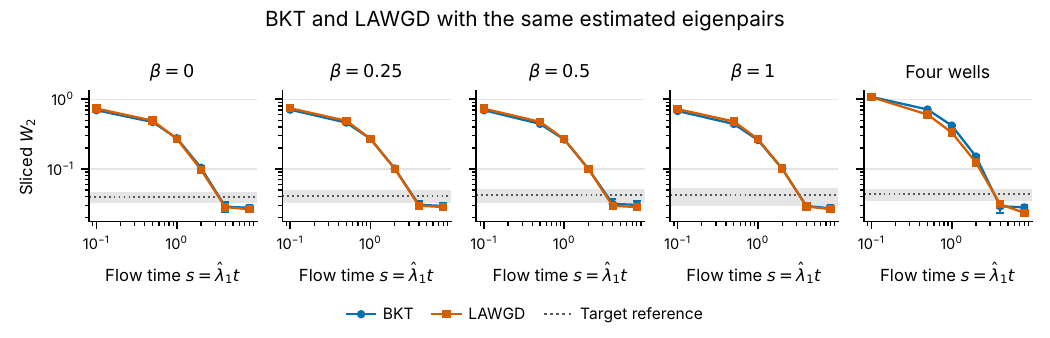

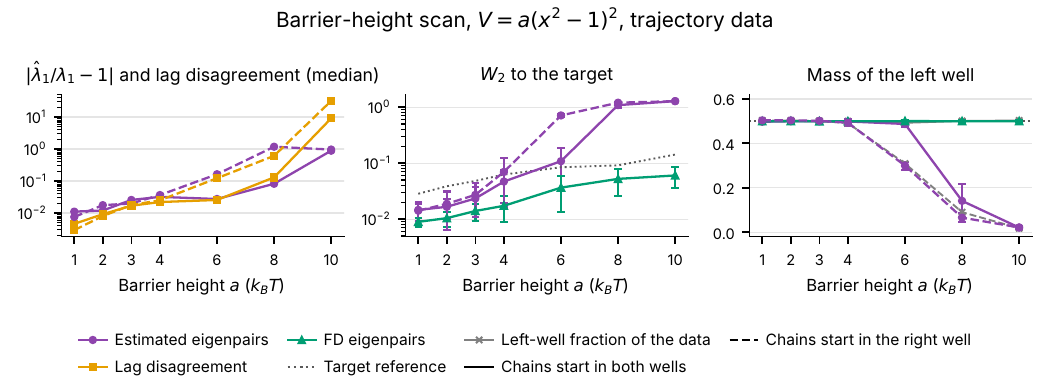

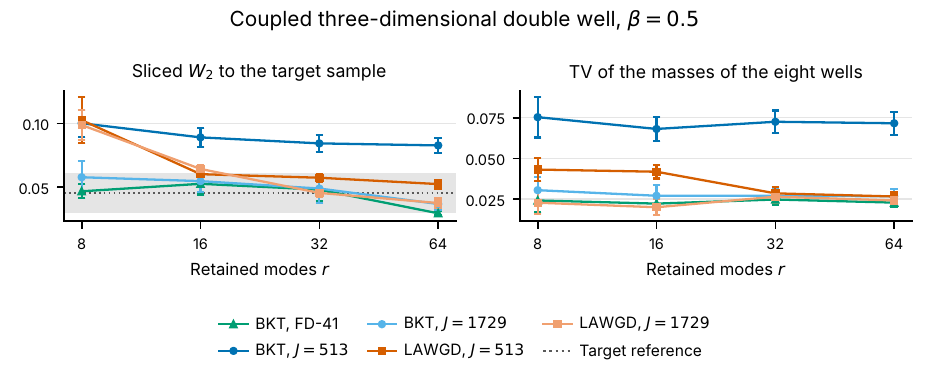

In [24]:
import importlib, make_figures
from IPython.display import Image, display
importlib.reload(make_figures)
for png in make_figures.main(png=True):
    display(Image(png))